# Modelos neuronales y ampliación de las variables predictivas

Este notebook desarrolla la etapa de modelado basada en redes neuronales.

En el análisis previo vimos que el retardo anual `Lag_52` constituye un baseline especialmente competitivo para la predicción de ventas semanales. Por este motivo, en lugar de predecir directamente `Weekly_Sales`, se reformula inicialmente el problema como la predicción de la desviación respecto al mismo periodo del año anterior:

$$
Residual_{52,t}
=
WeeklySales_t-Lag_{52,t}
$$

La predicción final se reconstruye mediante:

$$
\widehat{WeeklySales}_t
=
Lag_{52,t}
+
\widehat{Residual}_{52,t}
$$

El objetivo del primer experimento neuronal consiste en determinar si una red neuronal multicapa puede capturar relaciones no lineales en el residual que no pudieron ser aprovechadas mediante la regresión lineal.

Posteriormente se estudiará la existencia de diferentes regímenes de ventas y la posible utilización de modelos especializados y arquitecturas *Mixture of Experts*.

> **Guía de ejecución: entrenamiento, carga y experimentos opcionales.** Este notebook permite reutilizar los modelos guardados en Google Drive sin volver a entrenarlos. Las salidas visibles corresponden a la última ejecución guardada; las métricas se recalculan cuando se ejecutan sus celdas. El test original no contiene `Weekly_Sales`, por lo que el rendimiento se analiza exclusivamente en validación.

Hay **dos controles diferentes**, que no deben confundirse:

- `TRAIN` (celda de configuración global) indica si se fuerza el reentrenamiento de los modelos. Con `True`, se entrenan de nuevo y se sustituyen los artefactos correspondientes. Con `False`, se cargan los modelos compatibles; **si faltan sus pesos o su firma de entrenamiento no coincide**, el código puede entrenarlos y guardarlos igualmente. Por tanto, `TRAIN=False` no significa «prohibido entrenar», sino «reutilizar cuando sea posible».
- `RUN_SOFT_MOE` (inicio del bloque Soft MoE) determina si se ejecuta el **Soft MoE conjunto original**. Con `True`, se construye la arquitectura y se carga o entrena según las reglas anteriores. Con `False`, se omite ese experimento: no se generan sus predicciones ni aparece en las comparaciones condicionadas. **No controla** el experimento posterior de *gating* con experto congelado ni el Soft MoE con *Feature Engineering*.

| Situación | `TRAIN` | `RUN_SOFT_MOE` | Resultado esperado |
| --- | :---: | :---: | --- |
| Primera ejecución, sin artefactos | `False` | `True` | Se entrenan y guardan los modelos que faltan, incluido el Soft MoE original. |
| Primera ejecución, sin artefactos | `True` | `True` | Se entrenan y guardan todos los modelos activados. |
| Ya existen modelos compatibles | `False` | `True` | Se cargan los modelos, incluido el Soft MoE, sin reentrenarlos. |
| Ya existen modelos compatibles | `False` | `False` | Se reutilizan los demás modelos y se omite el Soft MoE original. |
| Reentrenamiento completo | `True` | `False` | Se reentrenan los demás modelos; el Soft MoE original se omite. |
| Reentrenamiento completo | `True` | `True` | Se reentrenan también los modelos del Soft MoE original. |

**El Soft MoE + FE tiene su propia carpeta y se carga con `TRAIN=False` cuando existen pesos, preprocesador y escalador. Si falta alguno, se entrena y guarda el conjunto completo; `TRAIN=True` fuerza su reentrenamiento. Su curva se recupera del historial CSV cuando está disponible.**

**Configuración recomendada para revisar los resultados ya calculados:** `TRAIN=False` y `RUN_SOFT_MOE=True`. La primera opción evita reentrenamientos innecesarios; la segunda conserva las métricas del Soft MoE original para las comparaciones. Si los archivos de Drive no están presentes o no son compatibles, la ejecución puede tardar porque será necesario entrenar. Los modelos se reconstruyen antes de cargar sus pesos; tener variables de una sesión previa de Colab no sustituye los artefactos guardados.

Por separado, `RUN_INTERPOLATION_EXPERIMENT=False` permite reutilizar los resultados registrados del experimento costoso de enmascaramiento; para repetirlo debe activarse expresamente. La validación se utiliza reiteradamente para seleccionar modelos y umbrales, de modo que sus métricas no constituyen una evaluación independiente. El EDA y el notebook anterior preparan los datos y las referencias históricas utilizados aquí.


## 1. Datos de entrada y preparación común

In [1]:
# =============================================================================
# COMPROBACIÓN DE GPU
# =============================================================================

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("\n✓ GPU detectada correctamente.")
else:
    print("\n⚠ No se ha detectado GPU.")

TensorFlow: 2.21.0
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✓ GPU detectada correctamente.


In [2]:
# =============================================================================
# LIBRERÍAS Y REPRODUCIBILIDAD
# =============================================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy import sparse


# -----------------------------------------------------------------------------
# Semilla
# -----------------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Semilla:", SEED)

Semilla: 42


In [3]:
# =============================================================================
# CONFIGURACIÓN GLOBAL: ENTRENAMIENTO Y CARGA DE MODELOS
# =============================================================================
# TRAIN = True  -> fuerza el reentrenamiento y sobrescribe artefactos.
# TRAIN = False -> carga artefactos compatibles; si faltan o su firma no
#                  coincide, se entrenan y se guardan automáticamente.
# IMPORTANTE: False NO impide entrenar en una primera ejecución.
# RUN_SOFT_MOE se configura al comienzo del bloque del Soft MoE original.
TRAIN = False
print(f"Modo de entrenamiento: TRAIN = {TRAIN}")


Modo de entrenamiento: TRAIN = False


In [4]:
# =============================================================================
# GOOGLE DRIVE
# =============================================================================

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
# =============================================================================
# GESTIÓN ÚNICA DE ARTEFACTOS Y COMPATIBILIDAD
# =============================================================================
import hashlib
import json
from pathlib import Path


def firma_entrenamiento(df, variables, objetivo, configuracion):
    """Huella reproducible del dataset y de la configuración del modelo."""
    columnas = list(dict.fromkeys(list(variables) + [objetivo]))
    valores = pd.util.hash_pandas_object(df[columnas], index=True).to_numpy()
    digest = hashlib.sha256(valores.tobytes())
    digest.update(json.dumps(configuracion, sort_keys=True, default=str).encode())
    return digest.hexdigest()


def plan_entrenamiento(nombre, ruta_modelo, dependencias, firma, forzar=False):
    """TRAIN=True reentrena; TRAIN=False carga solo conjuntos completos.

    Los modelos antiguos sin metadata se cargan por compatibilidad retroactiva,
    mostrando una advertencia: su procedencia no puede certificarse.
    """
    ruta_modelo = Path(ruta_modelo)
    directorio = ruta_modelo.parent
    ruta_firma = directorio / "training_signature.json"
    faltantes = [str(p) for p in [ruta_modelo, *map(Path, dependencias)] if not Path(p).exists()]
    if TRAIN or forzar:
        razon = "TRAIN=True" if TRAIN else "dependencia actualizada"
    elif faltantes:
        razon = "artefactos inexistentes: " + ", ".join(faltantes)
    elif ruta_firma.exists():
        with open(ruta_firma, encoding="utf-8") as f:
            guardado = json.load(f)
        razon = None if guardado.get("signature") == firma else "cambió el dataset o la configuración"
    else:
        razon = None
        print(f"⚠ {nombre}: artefacto antiguo sin firma; se comprobará la forma de sus entradas, "
              "pero no se puede garantizar su procedencia. Para certificarlo, usa TRAIN=True.")
    entrenar = razon is not None
    print(f"{nombre}: {'ENTRENAR / SOBRESCRIBIR' if entrenar else 'CARGAR'}"
          + (f" ({razon})" if razon else ""))
    return entrenar


def registrar_entrenamiento(ruta_modelo, firma):
    """Registrar una ejecución entrenada; nunca certificar artefactos antiguos."""
    ruta_firma = Path(ruta_modelo).parent / "training_signature.json"
    ruta_firma.parent.mkdir(parents=True, exist_ok=True)
    with open(ruta_firma, "w", encoding="utf-8") as f:
        json.dump({"signature": firma}, f, indent=2)


def comprobar_entrada_modelo(modelo, ancho, nombre):
    """Falla explícitamente ante una entrada numérica incompatible."""
    dimension = modelo.input_shape[-1]
    if dimension is not None and int(dimension) != int(ancho):
        raise ValueError(f"{nombre}: modelo guardado recibe {dimension} columnas; "
                         f"los datos actuales tienen {ancho}. Ejecuta TRAIN=True.")


In [6]:
# =============================================================================
# RUTAS
# =============================================================================

DATA_DIR = "/content/drive/MyDrive/TFM/data/neural_networks"

TRAIN_PATH = f"{DATA_DIR}/train_internal_nn.parquet"
VAL_PATH = f"{DATA_DIR}/validation_nn.parquet"
TEST_PATH = f"{DATA_DIR}/test_nn.parquet"

print(TRAIN_PATH)
print(VAL_PATH)
print(TEST_PATH)

/content/drive/MyDrive/TFM/data/neural_networks/train_internal_nn.parquet
/content/drive/MyDrive/TFM/data/neural_networks/validation_nn.parquet
/content/drive/MyDrive/TFM/data/neural_networks/test_nn.parquet


In [7]:
# =============================================================================
# CARGA DE DATOS
# =============================================================================

train = pd.read_parquet(TRAIN_PATH)
validation = pd.read_parquet(VAL_PATH)
test = pd.read_parquet(TEST_PATH)

print(
    f"Train:      {train.shape[0]:,} filas × {train.shape[1]} columnas"
)

print(
    f"Validation: {validation.shape[0]:,} filas × {validation.shape[1]} columnas"
)

print(
    f"Test:       {test.shape[0]:,} filas × {test.shape[1]} columnas"
)

Train:      305,982 filas × 35 columnas
Validation: 115,588 filas × 35 columnas
Test:       115,064 filas × 33 columnas


In [8]:
# =============================================================================
# COMPROBACIÓN DEL SPLIT TEMPORAL
# =============================================================================

print(
    "TRAIN:",
    train["Date"].min(),
    "→",
    train["Date"].max()
)

print(
    "VALIDATION:",
    validation["Date"].min(),
    "→",
    validation["Date"].max()
)

print(
    "TEST:",
    test["Date"].min(),
    "→",
    test["Date"].max()
)


assert train["Date"].max() < validation["Date"].min()
assert validation["Date"].max() < test["Date"].min()

print("\n✓ Separación temporal correcta.")

TRAIN: 2010-02-05 00:00:00 → 2012-01-27 00:00:00
VALIDATION: 2012-02-03 00:00:00 → 2012-10-26 00:00:00
TEST: 2012-11-02 00:00:00 → 2013-07-26 00:00:00

✓ Separación temporal correcta.


### 1.1. Disponibilidad del retardo anual y muestra residual

La formulación residual exige disponer de las ventas de la misma combinación tienda-departamento exactamente 52 semanas antes:

$$
Lag_{52,t}=WeeklySales_{t-52}.
$$

Cuando existe esta referencia, se define:

$$
Residual_{52,t}=WeeklySales_t-Lag_{52,t}.
$$

El histórico comienza en febrero de 2010. Durante aproximadamente el primer año no existe una observación correspondiente al año anterior; además, algunas series presentan discontinuidades que impiden recuperar el retardo en determinadas fechas.

Por ello, **no todas las filas pueden convertirse en ejemplos supervisados para entrenar el modelo residual**. Las observaciones del primer año sí pueden utilizarse como histórico para construir los retardos de fechas posteriores. La evaluación del sistema residual debe restringirse a las observaciones con `Lag_52` disponible y distinguirse de las comparaciones realizadas sobre el conjunto completo.


In [9]:
# =============================================================================
# VARIABLE OBJETIVO RESIDUAL
# =============================================================================

train["Residual_52"] = (
    train["Weekly_Sales"]
    - train["Lag_52"]
).astype("float32")

validation["Residual_52"] = (
    validation["Weekly_Sales"]
    - validation["Lag_52"]
).astype("float32")

In [10]:
# =============================================================================
# OBSERVACIONES CON LAG_52 DISPONIBLE
# =============================================================================

train_residual = (
    train[
        train["Lag_52"].notna()
    ]
    .copy()
)

validation_residual = (
    validation[
        validation["Lag_52"].notna()
    ]
    .copy()
)

test_residual = (
    test[
        test["Lag_52"].notna()
    ]
    .copy()
)


def show_coverage(full_df, residual_df, name):
    print(
        f"{name:12s}: "
        f"{len(residual_df):,} / {len(full_df):,} "
        f"({100 * len(residual_df) / len(full_df):.2f}%)"
    )


show_coverage(
    train,
    train_residual,
    "TRAIN"
)

show_coverage(
    validation,
    validation_residual,
    "VALIDATION"
)

show_coverage(
    test,
    test_residual,
    "TEST"
)

TRAIN       : 149,104 / 305,982 (48.73%)
VALIDATION  : 112,437 / 115,588 (97.27%)
TEST        : 113,023 / 115,064 (98.23%)


In [11]:
# =============================================================================
# VARIABLES DEL MODELO
# =============================================================================

TARGET = "Residual_52"


categorical_features = [
    "Store",
    "Dept",
    "Type"
]


numeric_features = [
    # Referencia anual
    "Lag_52",

    # Condiciones actuales
    "Temperature",
    "Fuel_Price",

    # Cambios interanuales
    "Delta_Temperature",
    "Delta_Fuel_Price",

    # Promociones
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",

    # Estructura
    "Size",

    # Tiempo
    "TimeIndex",
    "WeekSin",
    "WeekCos"
]


binary_features = [
    "IsHoliday",

    "MarkDown1_isna",
    "MarkDown2_isna",
    "MarkDown3_isna",
    "MarkDown4_isna",
    "MarkDown5_isna"
]


model_features = (
    categorical_features
    + numeric_features
    + binary_features
)


print("Número de variables de entrada:", len(model_features))

Número de variables de entrada: 23


In [12]:
# =============================================================================
# MATRICES DE ENTRENAMIENTO Y VALIDACIÓN
# =============================================================================

X_train = train_residual[
    model_features
].copy()

y_train = train_residual[
    TARGET
].copy()


X_val = validation_residual[
    model_features
].copy()

y_val = validation_residual[
    TARGET
].copy()


X_test = test_residual[
    model_features
].copy()


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nX_test:", X_test.shape)

X_train: (149104, 23)
y_train: (149104,)

X_val: (112437, 23)
y_val: (112437,)

X_test: (113023, 23)


### 1.2. Representación de las variables

En el primer experimento neuronal se conserva una representación similar a la utilizada en los modelos lineales:

- las variables numéricas se imputan, cuando sea necesario, mediante la mediana y posteriormente se estandarizan;
- las variables categóricas (`Store`, `Dept` y `Type`) se transforman mediante codificación *one-hot*;
- las variables binarias se incorporan directamente.

Esta decisión permite realizar una comparación inicial en la que la principal diferencia respecto a la regresión residual es la capacidad no lineal de la red neuronal.

En experimentos posteriores podrá estudiarse la sustitución de la codificación *one-hot* por **embeddings aprendidos**, especialmente para los identificadores `Store` y `Dept`.

#### Preprocesamiento

Además de guardar la red neuronal, también es necesario conservar el preprocesamiento utilizado durante su entrenamiento.

La razón es sencilla: la red no recibe directamente los datos tal y como aparecen en el dataset. Antes de entrenarla se realizan varias transformaciones, como rellenar valores ausentes, estandarizar las variables numéricas y codificar las variables categóricas. Algunas de estas transformaciones dependen de valores calculados a partir del conjunto de entrenamiento.

Por ejemplo, el preprocesador guarda:

- las medianas calculadas en el entrenamiento para rellenar los valores ausentes de las variables numéricas;
- las medias y desviaciones utilizadas para estandarizar las variables numéricas;
- las categorías encontradas durante la codificación de las variables categóricas;
- el orden final de las variables después de aplicar todas las transformaciones.

Por tanto, si más adelante cargamos una red ya entrenada, debemos transformar los nuevos datos exactamente de la misma forma. No tendría sentido volver a ajustar el preprocesador sobre otro conjunto, ya que podrían cambiar las medianas, las medias, las desviaciones o incluso las categorías utilizadas. En ese caso, la red estaría recibiendo unos datos diferentes de aquellos con los que aprendió.

Por este motivo se conservan, según el experimento, los elementos necesarios para reproducir sus predicciones:

- el modelo completo (`model.keras`) o sus pesos (`model.weights.h5`);
- el preprocesador (`preprocessor.joblib`) y, cuando procede, las correspondencias de categorías;
- el escalador de la variable objetivo (`target_scaler.joblib`);
- el historial de entrenamiento, si se ha guardado, y la firma de configuración para detectar cambios identificables.

Cada modelo mantiene sus artefactos asociados. El propósito de conservar el preprocesamiento no es solo ahorrar tiempo: es aplicar a las nuevas observaciones exactamente las transformaciones con las que se entrenó la red. Los artefactos antiguos sin firma pueden reutilizarse, pero su compatibilidad con una nueva versión de los datos no queda garantizada hasta reentrenar.

In [13]:
# =============================================================================
# PREPROCESAMIENTO
# =============================================================================

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ],
    remainder="drop"
)

In [14]:
import joblib

MODEL_DIR = "/content/drive/MyDrive/TFM/models/mlp_residual_global"
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PATH = f"{MODEL_DIR}/model.keras"
HISTORY_PATH = f"{MODEL_DIR}/history.csv"
PREPROCESSOR_PATH = f"{MODEL_DIR}/preprocessor.joblib"
TARGET_SCALER_PATH = f"{MODEL_DIR}/target_scaler.joblib"

FIRMA_GLOBAL = firma_entrenamiento(
    train_residual, model_features, "Residual_52",
    {"modelo": "MLP_GLOBAL", "capas": [128, 64], "dropout": [0.20, 0.10],
     "loss": "mae", "lr": 1e-3, "epochs": 100, "batch": 256,
     "holiday_weight": 5, "seed": SEED}
)
ENTRENAR_GLOBAL = plan_entrenamiento(
    "MLP residual global", MODEL_PATH,
    [PREPROCESSOR_PATH, TARGET_SCALER_PATH], FIRMA_GLOBAL
)

MLP residual global: CARGAR


In [15]:
# =============================================================================
# CARGA O AJUSTE DEL PREPROCESAMIENTO
# =============================================================================

PREPROCESSOR_PATH = (
    f"{MODEL_DIR}/preprocessor.joblib"
)


if not ENTRENAR_GLOBAL and os.path.exists(PREPROCESSOR_PATH):

    # -------------------------------------------------------------------------
    # PREPROCESADOR YA AJUSTADO
    # -------------------------------------------------------------------------

    preprocessor = joblib.load(
        PREPROCESSOR_PATH
    )

    X_train_processed = (
        preprocessor.transform(
            X_train
        )
    )

    X_val_processed = (
        preprocessor.transform(
            X_val
        )
    )

    X_test_processed = (
        preprocessor.transform(
            X_test
        )
    )

    print(
        "✓ Preprocesador cargado desde Drive."
    )


else:

    # -------------------------------------------------------------------------
    # PRIMERA EJECUCIÓN: AJUSTE EXCLUSIVAMENTE CON TRAIN
    # -------------------------------------------------------------------------

    X_train_processed = (
        preprocessor.fit_transform(
            X_train
        )
    )

    X_val_processed = (
        preprocessor.transform(
            X_val
        )
    )

    X_test_processed = (
        preprocessor.transform(
            X_test
        )
    )


    joblib.dump(
        preprocessor,
        PREPROCESSOR_PATH
    )

    print(
        "✓ Preprocesador ajustado con train y guardado."
    )


print(
    "\nTrain:",
    X_train_processed.shape
)

print(
    "Validation:",
    X_val_processed.shape
)

print(
    "Test:",
    X_test_processed.shape
)

✓ Preprocesador cargado desde Drive.

Train: (149104, 147)
Validation: (112437, 147)
Test: (113023, 147)


In [16]:
# =============================================================================
# CONVERSIÓN PARA TENSORFLOW
# =============================================================================

if sparse.issparse(X_train_processed):
    X_train_processed = X_train_processed.toarray()

if sparse.issparse(X_val_processed):
    X_val_processed = X_val_processed.toarray()

if sparse.issparse(X_test_processed):
    X_test_processed = X_test_processed.toarray()


X_train_processed = X_train_processed.astype(
    np.float32
)

X_val_processed = X_val_processed.astype(
    np.float32
)

X_test_processed = X_test_processed.astype(
    np.float32
)


print(
    "Memoria train:",
    f"{X_train_processed.nbytes / 1024**2:.2f} MB"
)

print(
    "Número final de inputs:",
    X_train_processed.shape[1]
)

Memoria train: 83.61 MB
Número final de inputs: 147


### 1.3. Estandarización del residuo

La variable objetivo presenta una elevada dispersión y contiene observaciones extremas. Para facilitar el proceso de optimización de la red se estandariza el residual utilizando exclusivamente la media y desviación estándar obtenidas a partir del conjunto de entrenamiento:

$$
z_t=
\frac{Residual_{52,t}-\mu_{\text{train}}}
{\sigma_{\text{train}}}
$$

La transformación se invierte posteriormente para obtener las predicciones en las unidades originales de ventas.

El escalado del objetivo no modifica la información disponible ni la definición del problema predictivo, sino únicamente la escala numérica utilizada durante el entrenamiento.

In [17]:
# =============================================================================
# CARGA O AJUSTE DEL ESCALADO DEL TARGET
# =============================================================================

import os
import joblib

TARGET_SCALER_PATH = (
    f"{MODEL_DIR}/target_scaler.joblib"
)


if not ENTRENAR_GLOBAL and os.path.exists(TARGET_SCALER_PATH):

    # ---------------------------------------------------------
    # SCALER YA AJUSTADO
    # ---------------------------------------------------------

    target_scaler = joblib.load(
        TARGET_SCALER_PATH
    )

    y_train_scaled = (
        target_scaler
        .transform(
            y_train
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    y_val_scaled = (
        target_scaler
        .transform(
            y_val
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    print(
        "✓ Target scaler cargado desde Drive."
    )


else:

    # ---------------------------------------------------------
    # PRIMERA EJECUCIÓN: AJUSTE SOLO CON TRAIN
    # ---------------------------------------------------------

    target_scaler = StandardScaler()

    y_train_scaled = (
        target_scaler
        .fit_transform(
            y_train
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    y_val_scaled = (
        target_scaler
        .transform(
            y_val
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    os.makedirs(
        MODEL_DIR,
        exist_ok=True
    )

    joblib.dump(
        target_scaler,
        TARGET_SCALER_PATH
    )

    print(
        "✓ Target scaler ajustado con train y guardado."
    )


print(
    "\nMedia y_train_scaled:",
    y_train_scaled.mean()
)

print(
    "Std y_train_scaled:",
    y_train_scaled.std()
)

✓ Target scaler cargado desde Drive.

Media y_train_scaled: -1.9443944e-09
Std y_train_scaled: 0.99999994


In [18]:
# =============================================================================
# PESOS DE FESTIVOS
# =============================================================================

train_weights = np.where(
    train_residual["IsHoliday"].to_numpy(),
    5.0,
    1.0
).astype(np.float32)


val_weights = np.where(
    validation_residual["IsHoliday"].to_numpy(),
    5.0,
    1.0
).astype(np.float32)


print(
    "Peso medio train:",
    train_weights.mean()
)

print(
    "Peso medio validation:",
    val_weights.mean()
)

Peso medio train: 1.3092606
Peso medio validation: 1.2061243


## 2. MLP residual global

En el notebook anterior se comprobó que una regresión lineal del residuo no conseguía mejorar suficientemente la referencia proporcionada por `Lag_52`. Esto no significa necesariamente que las variables adicionales no contengan información útil, sino que una relación lineal puede resultar demasiado limitada para aprovecharla.

Por este motivo, el siguiente paso consiste en probar una red neuronal capaz de representar relaciones más complejas entre las variables de entrada. Como primera arquitectura se utiliza un perceptrón multicapa (*Multilayer Perceptron*, MLP). Se trata de una red neuronal formada por varias capas de neuronas conectadas entre sí, en la que cada capa transforma la información recibida antes de pasarla a la siguiente.

El objetivo sigue siendo el planteado al final del notebook anterior: **no predecir directamente las ventas, sino el residuo respecto a `Lag_52`**. De esta forma, la red intenta aprender qué factores pueden hacer que las ventas de una semana sean superiores o inferiores a las registradas 52 semanas antes.

Para este primer experimento se utiliza una arquitectura relativamente sencilla:

$$
Input
\rightarrow
Dense(128)
\rightarrow
Dropout(0.20)
\rightarrow
Dense(64)
\rightarrow
Dropout(0.10)
\rightarrow
Dense(1)
$$

La primera capa oculta contiene 128 neuronas y la segunda 64. Las capas `Dense` permiten combinar la información de todas las variables de entrada y aprender relaciones entre ellas. En ambas capas se utiliza la función de activación ReLU, que introduce no linealidad y permite que la red modele relaciones más complejas que las que puede representar una regresión lineal.

Entre las capas se incorpora `Dropout`. Durante el entrenamiento, esta técnica desactiva aleatoriamente una proporción de las neuronas: un 20 % después de la primera capa y un 10 % después de la segunda. Su objetivo es reducir el riesgo de que la red dependa demasiado de combinaciones concretas de neuronas y favorecer una mejor generalización sobre datos no utilizados durante el entrenamiento.

La última capa contiene una única neurona, ya que se obtiene una sola predicción: el residuo esperado. En este caso se utiliza una activación lineal, adecuada para un problema de regresión porque permite obtener valores tanto positivos como negativos. Esto es especialmente importante en este problema, ya que el residuo puede indicar tanto un aumento como una disminución de las ventas respecto al año anterior.

Como función de pérdida se utiliza inicialmente el MAE (*Mean Absolute Error*). Además, durante el entrenamiento se aplican los pesos asociados a las semanas festivas, de manera coherente con la métrica WMAE utilizada para evaluar los modelos.

Esta primera arquitectura no pretende ser todavía una configuración óptima. Su objetivo es comprobar si un modelo no lineal de complejidad moderada puede aprender parte de las variaciones que la referencia anual y los modelos lineales anteriores no consiguen explicar.

In [19]:
# =============================================================================
# MLP RESIDUAL GLOBAL
# =============================================================================

tf.keras.backend.clear_session()


n_features = X_train_processed.shape[1]


model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(n_features,)
    ),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.20
    ),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.10
    ),

    tf.keras.layers.Dense(
        1,
        activation="linear"
    )
])


model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mae"
)


model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,265 (106.50 KB)

 Trainable params: 27,265 (106.50 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# =============================================================================
# CALLBACKS
# =============================================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)


reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [21]:
# =============================================================================
# ENTRENAMIENTO O CARGA DE LA MLP RESIDUAL GLOBAL
# =============================================================================

MODEL_PATH = f"{MODEL_DIR}/model.keras"
HISTORY_PATH = f"{MODEL_DIR}/history.csv"

if not ENTRENAR_GLOBAL:

    model = tf.keras.models.load_model(
        MODEL_PATH
    )

    comprobar_entrada_modelo(model, X_train_processed.shape[1], "MLP global")
    print("✓ MLP residual global cargada desde Drive.")


else:

    print("Entrenando MLP global (nueva ejecución o artefactos ausentes/incompatibles)...")

    history = model.fit(

        X_train_processed,
        y_train_scaled,

        sample_weight=train_weights,

        validation_data=(
            X_val_processed,
            y_val_scaled,
            val_weights
        ),

        epochs=100,
        batch_size=256,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        verbose=1
    )


    os.makedirs(
        MODEL_DIR,
        exist_ok=True
    )

    model.save(
        MODEL_PATH
    )
    pd.DataFrame(
    history.history).to_csv(
    HISTORY_PATH,
    index=False
    )

    registrar_entrenamiento(MODEL_PATH, FIRMA_GLOBAL)
    print("✓ Modelo entrenado y guardado.")

✓ MLP residual global cargada desde Drive.


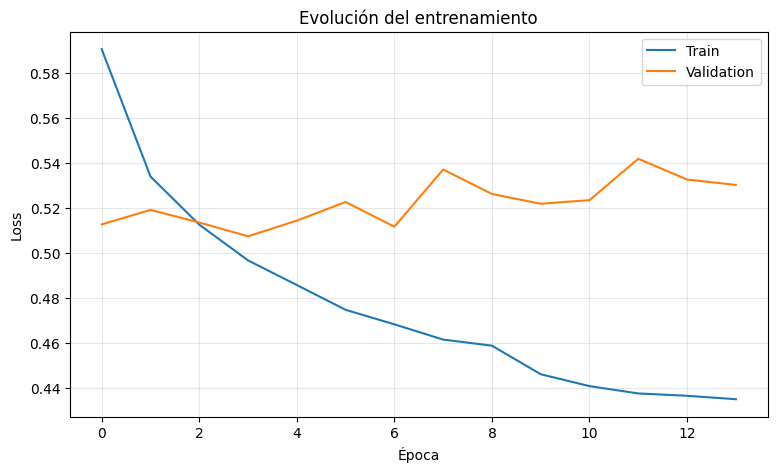

In [22]:
# =============================================================================
# EVOLUCIÓN DEL ENTRENAMIENTO
# =============================================================================

HISTORY_PATH = f"{MODEL_DIR}/history.csv"


if os.path.exists(HISTORY_PATH):

    history_df = pd.read_csv(
        HISTORY_PATH
    )

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["loss"],
        label="Train"
    )

    plt.plot(
        history_df["val_loss"],
        label="Validation"
    )

    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.title("Evolución del entrenamiento")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

else:

    print(
        "⚠ Historial no disponible: "
        "el modelo fue entrenado antes de implementar "
        "el guardado de history.csv."
    )

In [23]:
# =============================================================================
# PREDICCIÓN DEL RESIDUAL
# =============================================================================

residual_pred_scaled = (
    model.predict(
        X_val_processed,
        verbose=0
    )
    .ravel()
)


residual_pred = (
    target_scaler
    .inverse_transform(
        residual_pred_scaled.reshape(-1, 1)
    )
    .ravel()
)


print(
    "Residual predicho medio:",
    f"{residual_pred.mean():,.2f}"
)

print(
    "Residual predicho mínimo:",
    f"{residual_pred.min():,.2f}"
)

print(
    "Residual predicho máximo:",
    f"{residual_pred.max():,.2f}"
)

Residual predicho medio: 448.96
Residual predicho mínimo: -24,463.34
Residual predicho máximo: 24,132.54


In [24]:
# =============================================================================
# RECONSTRUCCIÓN DE WEEKLY_SALES
# =============================================================================

y_true = (
    validation_residual["Weekly_Sales"]
    .to_numpy()
)


lag52_val = (
    validation_residual["Lag_52"]
    .to_numpy()
)


y_pred_mlp = (
    lag52_val
    + residual_pred
)

In [25]:
# =============================================================================
# MÉTRICAS
# =============================================================================

def calculate_metrics(
    y_true,
    y_pred,
    weights
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    wmae = np.average(
        np.abs(
            y_true - y_pred
        ),
        weights=weights
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WMAE": wmae,
        "R2": r2
    }

In [26]:
# =============================================================================
# BASELINE VS MLP
# =============================================================================

metrics_baseline = calculate_metrics(
    y_true,
    lag52_val,
    val_weights
)


metrics_mlp = calculate_metrics(
    y_true,
    y_pred_mlp,
    val_weights
)


comparison = pd.DataFrame([
    {
        "Modelo": "Baseline Lag_52",
        **metrics_baseline
    },
    {
        "Modelo": "MLP residual global",
        **metrics_mlp
    }
])


display(
    comparison.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.9694
1,MLP residual global,"1,813.02","3,728.19","1,811.60",0.9721


In [27]:
# =============================================================================
# DIFERENCIA RESPECTO AL BASELINE
# =============================================================================

for metric in [
    "MAE",
    "RMSE",
    "WMAE"
]:

    baseline_value = metrics_baseline[metric]
    mlp_value = metrics_mlp[metric]

    improvement = (
        (baseline_value - mlp_value)
        / baseline_value
        * 100
    )

    print(
        f"{metric}: "
        f"{improvement:+.2f}% "
        f"respecto a Lag_52"
    )

MAE: +1.43% respecto a Lag_52
RMSE: +4.50% respecto a Lag_52
WMAE: +1.62% respecto a Lag_52


### 2.1. Resultados de la MLP residual global

La MLP aprende el residuo respecto al retardo anual `Lag_52` y reconstruye las ventas sumando la corrección estimada a esa referencia. Su rendimiento en validación mejora al baseline, aunque la reducción del WMAE es moderada.

| Modelo | MAE | RMSE | WMAE | R² |
|---|---:|---:|---:|---:|
| Baseline `Lag_52` | 1.839,24 | 3.903,93 | 1.841,52 | 0,9694 |
| MLP residual global | 1.813,02 | 3.728,19 | **1.811,60** | 0,9721 |

La reducción del WMAE es del **1,62 %**, y la del RMSE, del **4,50 %**. La formulación residual permite partir de una referencia estacional competitiva, pero la mejora agregada no implica que la corrección neuronal resulte beneficiosa para todas las observaciones. Esa heterogeneidad se estudia a continuación por volumen de ventas.


## 3. Rendimiento según el volumen de ventas

In [28]:
# =============================================================================
# QUINTILES DE VOLUMEN CALCULADOS EXCLUSIVAMENTE CON TRAIN
# =============================================================================

quantiles = (
    train_residual["Lag_52"]
    .quantile([0.20, 0.40, 0.60, 0.80])
    .to_numpy()
)

print("Umbrales:")
for q, value in zip(
    [20, 40, 60, 80],
    quantiles
):
    print(
        f"Q{q}: {value:,.2f}"
    )

Umbrales:
Q20: 1,660.93
Q40: 5,325.39
Q60: 11,867.54
Q80: 25,868.64


In [29]:
# =============================================================================
# SEGMENTACIÓN DE VALIDATION SEGÚN VOLUMEN HISTÓRICO
# =============================================================================

bins = [
    -np.inf,
    *quantiles,
    np.inf
]

labels = [
    "Q1",
    "Q2",
    "Q3",
    "Q4",
    "Q5"
]


validation_residual["Volume_Group"] = pd.cut(
    validation_residual["Lag_52"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [30]:
# =============================================================================
# BASELINE VS MLP POR VOLUMEN DE VENTAS
# =============================================================================

results_by_volume = []

for group in labels:

    mask = (
        validation_residual["Volume_Group"]
        == group
    ).to_numpy()

    y_true_group = y_true[mask]
    lag_group = lag52_val[mask]
    mlp_group = y_pred_mlp[mask]
    weights_group = val_weights[mask]

    baseline_group = calculate_metrics(
        y_true_group,
        lag_group,
        weights_group
    )

    mlp_group_metrics = calculate_metrics(
        y_true_group,
        mlp_group,
        weights_group
    )

    results_by_volume.append({
        "Grupo": group,
        "N": mask.sum(),

        "Baseline_MAE":
            baseline_group["MAE"],

        "MLP_MAE":
            mlp_group_metrics["MAE"],

        "Baseline_WMAE":
            baseline_group["WMAE"],

        "MLP_WMAE":
            mlp_group_metrics["WMAE"],

        "Mejora_WMAE_%":
            (
                baseline_group["WMAE"]
                - mlp_group_metrics["WMAE"]
            )
            / baseline_group["WMAE"]
            * 100
    })


volume_comparison = pd.DataFrame(
    results_by_volume
)


display(
    volume_comparison.style.format({
        "Baseline_MAE": "{:,.2f}",
        "MLP_MAE": "{:,.2f}",
        "Baseline_WMAE": "{:,.2f}",
        "MLP_WMAE": "{:,.2f}",
        "Mejora_WMAE_%": "{:+.2f}%"
    })
)

,Grupo,N,Baseline_MAE,MLP_MAE,Baseline_WMAE,MLP_WMAE,Mejora_WMAE_%
0,Q1,23476,270.61,349.95,277.57,366.26,-31.95%
1,Q2,22570,707.87,741.33,708.04,756.20,-6.80%
2,Q3,22929,"1,308.41","1,288.41","1,304.47","1,304.34",+0.01%
3,Q4,21746,"2,204.39","2,163.52","2,193.58","2,153.83",+1.81%
4,Q5,21716,"4,905.68","4,711.45","4,925.53","4,664.37",+5.30%


### 3.1. Análisis por quintiles

Para analizar si la corrección residual aporta la misma utilidad en todos los niveles de ventas, se agrupan las observaciones de validación en quintiles según `Lag_52`.

| Quintil | N | WMAE baseline | WMAE MLP | Mejora relativa |
|---|---:|---:|---:|---:|
| Q1 | 23.476 | 277,57 | 366,26 | -31,95 % |
| Q2 | 22.570 | 708,04 | 756,20 | -6,80 % |
| Q3 | 22.929 | 1.304,47 | 1.304,34 | +0,01 % |
| Q4 | 21.746 | 2.193,58 | 2.153,83 | +1,81 % |
| Q5 | 21.716 | 4.925,53 | 4.664,37 | +5,30 % |

En los dos quintiles de menor volumen la MLP empeora la referencia anual. En el tercero prácticamente iguala su rendimiento y en los dos superiores aporta una mejora creciente. Esta distribución del error justifica estudiar una combinación de expertos que conserve el baseline cuando la corrección neuronal no resulta ventajosa.


## 4. Combinación de expertos mediante un umbral

Hasta este punto se han comparado el baseline anual y la MLP residual buscando cuál de los dos obtiene un mejor resultado global. Sin embargo, el análisis por quintiles muestra que esta comparación no tiene por qué resolverse eligiendo un único modelo para todas las observaciones.

En las ventas de menor volumen, especialmente en el primer quintil, la corrección realizada por la red neuronal no mejora la predicción proporcionada directamente por `Lag_52`. En cambio, a medida que aumenta el nivel de ventas, la MLP residual comienza a aportar una mejora cada vez mayor.

Este resultado plantea una alternativa: **en lugar de elegir un único modelo para todas las observaciones, puede utilizarse cada uno allí donde parece funcionar mejor**.

Para las observaciones de menor volumen, donde `Lag_52` ya proporciona una buena referencia y la corrección neuronal puede incluso empeorarla, se mantiene directamente la predicción del año anterior. Para las observaciones de mayor volumen, se utiliza la MLP para estimar cuánto debemos corregir esa referencia.

Esto da lugar a un sistema sencillo de **combinación de expertos**:

$$
\hat Y_t=
\begin{cases}
Lag_{52,t},
& Lag_{52,t}\le c\\[6pt]
Lag_{52,t}+\widehat{Residual}_{52,t},
& Lag_{52,t}>c
\end{cases}
$$

En este planteamiento existen dos formas de realizar la predicción:

- `Lag_52` actúa como experto para las observaciones de menor volumen, manteniendo directamente la referencia anual;
- la MLP residual actúa como experto para las observaciones de mayor volumen, corrigiendo `Lag_52` mediante el residuo estimado;
- el umbral $c$ determina qué experto se utiliza en cada caso.

Este último elemento funciona como un mecanismo sencillo de enrutamiento o *gating*. En sistemas de expertos más complejos esta decisión puede ser aprendida por otro modelo, mientras que aquí se basa únicamente en el valor de `Lag_52`.

Por tanto, queda por decidir **qué valor debe tomar el umbral $c$**. Este valor se considera un hiperparámetro del sistema: distintos valores modifican qué proporción de observaciones se asigna al baseline y cuál a la MLP y, por tanto, pueden afectar al rendimiento final.

Inicialmente se plantea seleccionar este hiperparámetro sin utilizar la validación principal. Para ello se reserva temporalmente la parte final del conjunto de entrenamiento como una validación interna. De esta forma, la idea original es utilizar el subentrenamiento para ajustar la red, la validación interna para seleccionar $c$ y mantener la validación principal como una evaluación posterior del sistema.

Sin embargo, como veremos a continuación, esta partición interna presenta un problema relacionado con la disponibilidad temporal de las variables `MarkDown`, por lo que será necesario revisar esta estrategia.

**Nota: limitación de la validación interna y selección final del umbral**

Para crear la validación interna se reservaron inicialmente las últimas 13 semanas del conjunto de entrenamiento. Aunque esta división mantiene el orden temporal de los datos, apareció un problema importante con las variables `MarkDown1`--`MarkDown5`.

La información de estas promociones comienza a estar disponible hacia el final del periodo de entrenamiento. Como consecuencia, en el subconjunto utilizado para entrenar la red las variables `MarkDown` eran prácticamente constantes e iguales a cero, mientras que en las 13 semanas reservadas para validación interna empezaban a aparecer valores promocionales elevados.

Esto provoca un cambio importante entre ambos periodos. La red se entrena sin haber podido aprender realmente cómo se relacionan las variaciones de `MarkDown` con el residuo y, además, el preprocesamiento se ajusta sobre unas variables que apenas presentan variabilidad. Al llegar a la validación interna, el modelo recibe valores muy diferentes de los observados durante su entrenamiento y las predicciones resultantes presentan magnitudes anómalas.

Por tanto, el problema no se encuentra necesariamente en el sistema de expertos, sino en que esta partición concreta genera un **cambio de distribución** entre el subentrenamiento y la validación interna. Por este motivo se descarta la división de 13 semanas para seleccionar el umbral.

Finalmente, $c$ se trata como un hiperparámetro más del sistema y se selecciona utilizando el conjunto de validación principal. Los valores candidatos se obtienen a partir de distintos cuantiles de `Lag_52` calculados sobre entrenamiento y se evalúa en validación qué umbral proporciona el mejor comportamiento del sistema híbrido.

Esta decisión implica que la validación participa en la selección de la configuración final. Por tanto, el resultado obtenido en este conjunto no debe interpretarse como una evaluación completamente independiente de la capacidad de generalización del sistema, sino como parte del proceso de selección del modelo.

Una vez elegido el umbral, este queda fijado como parte de la configuración final, del mismo modo que el resto de hiperparámetros. Para la generación posterior de predicciones puede mantenerse el umbral seleccionado. En ausencia de ventas observadas en el test original no es posible calcular allí las métricas de error.

In [31]:
# =============================================================================
# COMPROBACIÓN DEL PUNTO DE PARTIDA
# =============================================================================

print("Observaciones validation:", len(y_true))
print("Predicciones MLP:", len(y_pred_mlp))
print("Predicciones baseline:", len(lag52_val))
print("Pesos:", len(val_weights))

assert len(y_true) == len(y_pred_mlp)
assert len(y_true) == len(lag52_val)
assert len(y_true) == len(val_weights)

print("\n✓ Dimensiones correctas.")

Observaciones validation: 112437
Predicciones MLP: 112437
Predicciones baseline: 112437
Pesos: 112437

✓ Dimensiones correctas.


In [32]:
# =============================================================================
# MÉTRICAS DE LOS EXPERTOS INDIVIDUALES
# =============================================================================

metrics_baseline = calculate_metrics(
    y_true,
    lag52_val,
    val_weights
)

metrics_mlp = calculate_metrics(
    y_true,
    y_pred_mlp,
    val_weights
)


print(
    "Baseline Lag_52 - WMAE:",
    f"{metrics_baseline['WMAE']:,.2f}"
)

print(
    "MLP residual global - WMAE:",
    f"{metrics_mlp['WMAE']:,.2f}"
)

Baseline Lag_52 - WMAE: 1,841.52
MLP residual global - WMAE: 1,811.60


In [33]:
# =============================================================================
# UMBRALES CANDIDATOS CALCULADOS SOBRE TRAIN
# =============================================================================

candidate_quantiles = np.round(
    np.arange(
        0.10,
        0.91,
        0.05
    ),
    2
)


candidate_thresholds = {
    q: train_residual["Lag_52"].quantile(q)
    for q in candidate_quantiles
}


threshold_table = pd.DataFrame({
    "Quantile": list(candidate_thresholds.keys()),
    "Threshold": list(candidate_thresholds.values())
})


display(
    threshold_table.style.format({
        "Quantile": "{:.2f}",
        "Threshold": "{:,.2f}"
    })
)

,Quantile,Threshold
0,0.10,479.22
1,0.15,991.54
2,0.20,"1,660.93"
3,0.25,"2,440.50"
4,0.30,"3,301.57"
5,0.35,"4,269.96"
6,0.40,"5,325.39"
7,0.45,"6,646.44"
8,0.50,"8,168.70"
9,0.55,"9,861.66"


In [34]:
# =============================================================================
# EVALUACIÓN DE LOS UMBRALES EN VALIDATION
# =============================================================================

threshold_results = []


for q, threshold in candidate_thresholds.items():

    # ---------------------------------------------------------
    # Decisión del gate
    # ---------------------------------------------------------

    use_mlp = (
        lag52_val > threshold
    )


    # ---------------------------------------------------------
    # Predicción híbrida
    # ---------------------------------------------------------

    y_pred_hybrid = np.where(
        use_mlp,
        y_pred_mlp,
        lag52_val
    )


    # ---------------------------------------------------------
    # Métricas
    # ---------------------------------------------------------

    metrics = calculate_metrics(
        y_true,
        y_pred_hybrid,
        val_weights
    )


    threshold_results.append({
        "Quantile": q,
        "Threshold": threshold,

        "Baseline_N":
            (~use_mlp).sum(),

        "MLP_N":
            use_mlp.sum(),

        "Baseline_%":
            100 * (~use_mlp).mean(),

        "MLP_%":
            100 * use_mlp.mean(),

        **metrics
    })


threshold_results = pd.DataFrame(
    threshold_results
)

In [35]:
# =============================================================================
# CONTROLES: BASELINE PURO Y MLP PURA
# =============================================================================

control_results = pd.DataFrame([

    # -------------------------------------------------------------------------
    # Todo al baseline
    # -------------------------------------------------------------------------

    {
        "Quantile": "Baseline puro",
        "Threshold": np.inf,

        "Baseline_N": len(y_true),
        "MLP_N": 0,

        "Baseline_%": 100.0,
        "MLP_%": 0.0,

        **metrics_baseline
    },


    # -------------------------------------------------------------------------
    # Todo a la MLP
    # -------------------------------------------------------------------------

    {
        "Quantile": "MLP pura",
        "Threshold": -np.inf,

        "Baseline_N": 0,
        "MLP_N": len(y_true),

        "Baseline_%": 0.0,
        "MLP_%": 100.0,

        **metrics_mlp
    }

])

In [36]:
# =============================================================================
# RESULTADOS DEL GATING
# =============================================================================

gate_results = pd.concat(
    [
        threshold_results,
        control_results
    ],
    ignore_index=True
)


gate_results_sorted = (
    gate_results
    .sort_values(
        "WMAE",
        ascending=True
    )
    .reset_index(drop=True)
)


display(
    gate_results_sorted.style.format({
        "Threshold": "{:,.2f}",
        "Baseline_%": "{:.2f}%",
        "MLP_%": "{:.2f}%",
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Quantile,Threshold,Baseline_N,MLP_N,Baseline_%,MLP_%,MAE,RMSE,WMAE,R2
0,0.550000,"9,861.66",63424,49013,56.41%,43.59%,"1,792.14","3,728.63","1,782.72",0.9721
1,0.450000,"6,646.44",51750,60687,46.03%,53.97%,"1,790.27","3,726.42","1,783.16",0.9721
2,0.500000,"8,168.70",57692,54745,51.31%,48.69%,"1,791.06","3,727.22","1,783.20",0.9721
3,0.400000,"5,325.39",46046,66391,40.95%,59.05%,"1,789.74","3,725.63","1,783.36",0.9721
4,0.600000,"11,867.54",68975,43462,61.35%,38.65%,"1,793.82","3,730.54","1,783.38",0.9721
5,0.650000,"14,265.78",74286,38151,66.07%,33.93%,"1,795.80","3,732.74","1,784.87",0.9720
6,0.700000,"17,103.45",79497,32940,70.70%,29.30%,"1,796.82","3,734.51","1,785.30",0.9720
7,0.350000,"4,269.96",40517,71920,36.04%,63.96%,"1,790.80","3,725.68","1,785.43",0.9721
8,0.300000,"3,301.57",34736,77701,30.89%,69.11%,"1,792.60","3,726.05","1,788.33",0.9721
9,0.750000,"20,753.96",85155,27282,75.74%,24.26%,"1,799.97","3,738.88","1,788.57",0.9719


In [37]:
# # =============================================================================
# # CÁLCULO DEL MEJOR UMBRAL
# # =============================================================================

best_idx = (
    threshold_results["WMAE"]
    .idxmin()
)



best_gate = (
    threshold_results
    .loc[best_idx]
)


best_quantile = (
    best_gate["Quantile"]
)

best_threshold = (
    best_gate["Threshold"]
)


print(
    f"Mejor percentil: "
    f"Q{int(round(best_quantile * 100))}"
)

print(
    f"Umbral Lag_52: "
    f"{best_threshold:,.2f}"
)

print(
    f"Observaciones enviadas al baseline: "
    f"{int(best_gate['Baseline_N']):,}"
)

print(
    f"Observaciones enviadas a la MLP: "
    f"{int(best_gate['MLP_N']):,}"
)

print(
    f"\nWMAE híbrido: "
    f"{best_gate['WMAE']:,.2f}"
)

Mejor percentil: Q55
Umbral Lag_52: 9,861.66
Observaciones enviadas al baseline: 63,424
Observaciones enviadas a la MLP: 49,013

WMAE híbrido: 1,782.72


In [38]:
# =============================================================================
# MEJOR UMBRAL
# =============================================================================

BEST_QUANTILE = float(best_quantile)

best_threshold = float(best_gate["Threshold"])

print(
    f"Umbral Q{int(round(BEST_QUANTILE * 100))}: {best_threshold:,.2f}"
)

Umbral Q55: 9,861.66


In [39]:
# =============================================================================
# MEJORA DEL SISTEMA HÍBRIDO
# =============================================================================

best_wmae = (
    best_gate["WMAE"]
)


improvement_vs_baseline = (
    (
        metrics_baseline["WMAE"]
        - best_wmae
    )
    / metrics_baseline["WMAE"]
    * 100
)


improvement_vs_mlp = (
    (
        metrics_mlp["WMAE"]
        - best_wmae
    )
    / metrics_mlp["WMAE"]
    * 100
)


print(
    "Mejora frente a Lag_52:",
    f"{improvement_vs_baseline:+.2f}%"
)

print(
    "Mejora frente a MLP global:",
    f"{improvement_vs_mlp:+.2f}%"
)

Mejora frente a Lag_52: +3.19%
Mejora frente a MLP global: +1.59%


In [40]:
# =============================================================================
# PREDICCIÓN DEL MEJOR SISTEMA DE EXPERTOS
# =============================================================================

use_mlp_best = (
    lag52_val > best_threshold
)


y_pred_experts = np.where(
    use_mlp_best,
    y_pred_mlp,
    lag52_val
)

In [41]:
# =============================================================================
# COMPARACIÓN FINAL
# =============================================================================

metrics_experts = calculate_metrics(
    y_true,
    y_pred_experts,
    val_weights
)


comparison_experts = pd.DataFrame([
    {
        "Modelo": "Baseline Lag_52",
        **metrics_baseline
    },
    {
        "Modelo": "MLP residual global",
        **metrics_mlp
    },
    {
        "Modelo": "Sistema de expertos",
        **metrics_experts
    }
])


display(
    comparison_experts.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.9694
1,MLP residual global,"1,813.02","3,728.19","1,811.60",0.9721
2,Sistema de expertos,"1,792.14","3,728.63","1,782.72",0.9721


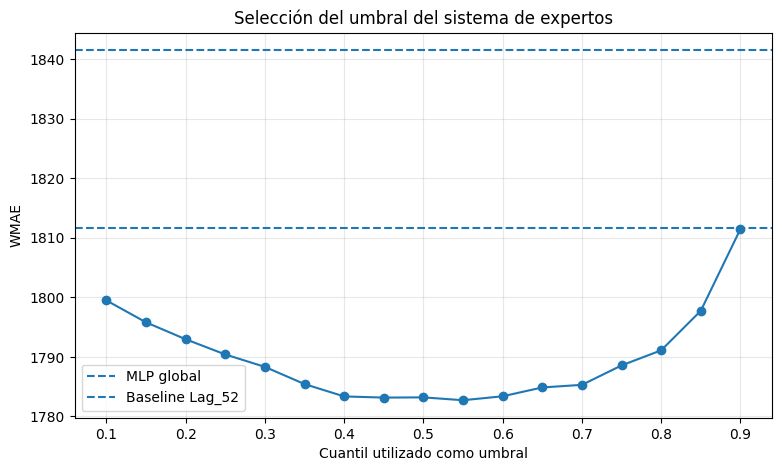

In [42]:
# =============================================================================
# WMAE EN FUNCIÓN DEL UMBRAL
# =============================================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    threshold_results["Quantile"],
    threshold_results["WMAE"],
    marker="o"
)

plt.axhline(
    metrics_mlp["WMAE"],
    linestyle="--",
    label="MLP global"
)

plt.axhline(
    metrics_baseline["WMAE"],
    linestyle="--",
    label="Baseline Lag_52"
)

plt.xlabel(
    "Cuantil utilizado como umbral"
)

plt.ylabel(
    "WMAE"
)

plt.title(
    "Selección del umbral del sistema de expertos"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

### 4.1. Selección del umbral

Se comparan distintos puntos de corte calculados a partir de la distribución de `Lag_52` en entrenamiento. El criterio de selección es el menor WMAE en validación. En la ejecución actual, el cuantil seleccionado es **Q55**, correspondiente a **9.861,66**.

| Modelo | WMAE de validación |
|---|---:|
| Baseline `Lag_52` | 1.841,52 |
| MLP residual global | 1.811,60 |
| Hard gating Q55 | **1.782,72** |

La regla asigna el baseline a las observaciones con `Lag_52` menor o igual al umbral y la corrección de la MLP al resto. El hard gating mejora el WMAE de ambos expertos por separado. El umbral se selecciona mediante validación y, por tanto, no constituye una estimación independiente de un punto de corte óptimo fuera de los candidatos explorados.


In [43]:
# =============================================================================
# RENDIMIENTO DE LOS EXPERTOS A AMBOS LADOS DEL UMBRAL
# =============================================================================

low_mask = (
    lag52_val <= best_threshold
)

high_mask = (
    lag52_val > best_threshold
)


segment_results = []


for segment_name, mask in [
    ("Volumen bajo", low_mask),
    ("Volumen medio/alto", high_mask)
]:

    # -------------------------------------------------------------------------
    # Baseline Lag_52
    # -------------------------------------------------------------------------

    baseline_metrics = calculate_metrics(
        y_true[mask],
        lag52_val[mask],
        val_weights[mask]
    )


    # -------------------------------------------------------------------------
    # MLP residual
    # -------------------------------------------------------------------------

    mlp_metrics = calculate_metrics(
        y_true[mask],
        y_pred_mlp[mask],
        val_weights[mask]
    )


    # -------------------------------------------------------------------------
    # Mejora relativa de la MLP respecto al baseline
    #
    # > 0  -> MLP mejor
    # < 0  -> Baseline mejor
    # -------------------------------------------------------------------------

    improvement_mae = (
        (
            baseline_metrics["MAE"]
            - mlp_metrics["MAE"]
        )
        / baseline_metrics["MAE"]
        * 100
    )

    improvement_rmse = (
        (
            baseline_metrics["RMSE"]
            - mlp_metrics["RMSE"]
        )
        / baseline_metrics["RMSE"]
        * 100
    )

    improvement_wmae = (
        (
            baseline_metrics["WMAE"]
            - mlp_metrics["WMAE"]
        )
        / baseline_metrics["WMAE"]
        * 100
    )


    segment_results.append({

        "Segmento": segment_name,

        "N": mask.sum(),

        "Porcentaje_%":
            100 * mask.mean(),

        "Baseline_MAE":
            baseline_metrics["MAE"],

        "MLP_MAE":
            mlp_metrics["MAE"],

        "Mejora_MAE_%":
            improvement_mae,

        "Baseline_RMSE":
            baseline_metrics["RMSE"],

        "MLP_RMSE":
            mlp_metrics["RMSE"],

        "Mejora_RMSE_%":
            improvement_rmse,

        "Baseline_WMAE":
            baseline_metrics["WMAE"],

        "MLP_WMAE":
            mlp_metrics["WMAE"],

        "Mejora_WMAE_%":
            improvement_wmae
    })


segment_results = pd.DataFrame(
    segment_results
)


display(
    segment_results.style.format({

        "Porcentaje_%": "{:.2f}%",

        "Baseline_MAE": "{:,.2f}",
        "MLP_MAE": "{:,.2f}",
        "Mejora_MAE_%": "{:+.2f}%",

        "Baseline_RMSE": "{:,.2f}",
        "MLP_RMSE": "{:,.2f}",
        "Mejora_RMSE_%": "{:+.2f}%",

        "Baseline_WMAE": "{:,.2f}",
        "MLP_WMAE": "{:,.2f}",
        "Mejora_WMAE_%": "{:+.2f}%"
    })
)

,Segmento,N,Porcentaje_%,Baseline_MAE,MLP_MAE,Mejora_MAE_%,Baseline_RMSE,MLP_RMSE,Mejora_RMSE_%,Baseline_WMAE,MLP_WMAE,Mejora_WMAE_%
0,Volumen bajo,63424,56.41%,686.69,723.71,-5.39%,"1,331.56","1,329.38",+0.16%,686.41,737.71,-7.47%
1,Volumen medio/alto,49013,43.59%,"3,330.66","3,222.62",+3.24%,"5,715.59","5,440.47",+4.81%,"3,329.06","3,194.54",+4.04%


In [44]:
# =============================================================================
# CONTRIBUCIÓN DE CADA RÉGIMEN AL ERROR ABSOLUTO PONDERADO
# =============================================================================

contribution_results = []


for segment_name, mask in [
    ("Volumen bajo", low_mask),
    ("Volumen medio/alto", high_mask)
]:

    # Errores absolutos ponderados
    baseline_weighted_error = np.sum(
        val_weights[mask]
        * np.abs(
            y_true[mask]
            - lag52_val[mask]
        )
    )

    mlp_weighted_error = np.sum(
        val_weights[mask]
        * np.abs(
            y_true[mask]
            - y_pred_mlp[mask]
        )
    )


    contribution_results.append({

        "Segmento": segment_name,

        "Baseline_Error_Ponderado":
            baseline_weighted_error,

        "MLP_Error_Ponderado":
            mlp_weighted_error
    })


contribution_results = pd.DataFrame(
    contribution_results
)


# Contribución porcentual dentro de cada modelo
contribution_results[
    "Baseline_Contribucion_%"
] = (
    contribution_results[
        "Baseline_Error_Ponderado"
    ]
    / contribution_results[
        "Baseline_Error_Ponderado"
    ].sum()
    * 100
)


contribution_results[
    "MLP_Contribucion_%"
] = (
    contribution_results[
        "MLP_Error_Ponderado"
    ]
    / contribution_results[
        "MLP_Error_Ponderado"
    ].sum()
    * 100
)


display(
    contribution_results.style.format({

        "Baseline_Error_Ponderado":
            "{:,.0f}",

        "MLP_Error_Ponderado":
            "{:,.0f}",

        "Baseline_Contribucion_%":
            "{:.2f}%",

        "MLP_Contribucion_%":
            "{:.2f}%"
    })
)

,Segmento,Baseline_Error_Ponderado,MLP_Error_Ponderado,Baseline_Contribucion_%,MLP_Contribucion_%
0,Volumen bajo,"52,397,504","56,313,816",20.98%,22.92%
1,Volumen medio/alto,"197,336,960","189,362,704",79.02%,77.08%


### 4.2. Resultados por régimen de ventas

El umbral Q55 (`Lag_52 = 9.861,66`) permite separar dos grupos con distinto comportamiento predictivo:

| Régimen | N | WMAE baseline | WMAE MLP |
|---|---:|---:|---:|
| `Lag_52` ≤ 9.861,66 | 63.424 | **686,41** | 737,71 |
| `Lag_52` > 9.861,66 | 49.013 | 3.329,06 | **3.194,54** |

En el primer grupo, la corrección de la MLP aumenta el WMAE aproximadamente un **7,47 %**; en el segundo lo reduce un **4,04 %**. Por ello, el sistema híbrido utiliza el baseline en el régimen de menor volumen y la MLP en el superior. El análisis describe el comportamiento observado en validación y motiva la posterior especialización de los expertos.


## 5. Combinación de expertos mediante una puerta aprendida

El sistema híbrido desarrollado en la sección anterior parte de una idea sencilla: el baseline anual y la MLP residual no funcionan igual de bien para todos los niveles de ventas. A partir de esta observación se definió una regla de enrutamiento basada en un umbral de `Lag_52`, utilizando el baseline para las observaciones de menor volumen y la corrección de la MLP para las de mayor volumen.

Este mecanismo puede interpretarse como una forma de *hard gating*, ya que la decisión es binaria:

$$
Lag_{52}\le c
\quad\Rightarrow\quad
\text{no aplicar corrección}
$$

$$
Lag_{52}>c
\quad\Rightarrow\quad
\text{aplicar la corrección completa de la MLP}.
$$

Aunque esta estrategia es sencilla e interpretable, presenta una limitación evidente: la decisión depende exclusivamente de `Lag_52` y cambia de forma brusca al atravesar el umbral. Dos observaciones con valores de `Lag_52` muy similares pueden recibir tratamientos completamente distintos simplemente por encontrarse a lados diferentes de $c$.

A partir de esta limitación se plantea una generalización del sistema mediante una arquitectura de tipo *Mixture of Experts* (MoE). La idea consiste en mantener los dos comportamientos anteriores, pero sustituir la regla fija por un mecanismo de enrutamiento aprendido a partir de los datos.

En este caso se consideran dos expertos sobre el residuo.

El primero representa la decisión de **no corregir el baseline anual**:

$$
E_1(X)=0.
$$

Si se selecciona este experto, el residuo predicho es cero y, por tanto, la predicción final coincide directamente con `Lag_52`.

El segundo experto representa la **corrección residual estimada por la red neuronal**:

$$
E_2(X)=f_{\theta}(X),
$$

donde $f_{\theta}(X)$ es la MLP encargada de predecir cuánto deberían diferir las ventas actuales respecto a las observadas 52 semanas antes.

En lugar de seleccionar uno de los dos expertos mediante una regla fija, se introduce una segunda red neuronal que actúa como puerta o *gate*. Esta red aprende un valor:

$$
g_{\phi}(X)\in[0,1],
$$

que determina cuánto peso se asigna a la corrección propuesta por la MLP.

La predicción del residuo se obtiene entonces como:

$$
\widehat{Residual}_{52}
=
(1-g_{\phi}(X))E_1(X)
+
g_{\phi}(X)E_2(X).
$$

Como el primer experto representa una corrección nula, es decir, $E_1(X)=0$, la expresión se simplifica a:

$$
\widehat{Residual}_{52}
=
g_{\phi}(X)f_{\theta}(X).
$$

La predicción final de ventas mantiene, por tanto, la misma estructura residual utilizada hasta ahora:

$$
\hat Y_t
=
Lag_{52,t}
+
g_{\phi}(X_t)f_{\theta}(X_t).
$$

Esta formulación permite interpretar con facilidad el papel de la puerta. Si:

$$
g_{\phi}(X)\approx 0,
$$

el modelo apenas modifica `Lag_52` y su comportamiento se aproxima al baseline anual. Si, por el contrario:

$$
g_{\phi}(X)\approx 1,
$$

se aplica prácticamente toda la corrección estimada por la MLP. Para valores intermedios, el modelo aplica únicamente una parte de dicha corrección.

Por tanto, la principal diferencia respecto al sistema basado en umbral es que la decisión deja de ser necesariamente binaria. El modelo puede aprender tanto **cuánto corregir** mediante $f_{\theta}(X)$ como **en qué medida confiar en esa corrección** mediante $g_{\phi}(X)$.

Además, mientras que el *hard gating* anterior utiliza únicamente `Lag_52` para decidir qué experto aplicar, la puerta aprendida puede considerar conjuntamente las características disponibles en $X$. Esto permite estudiar si existen patrones más complejos que expliquen cuándo resulta conveniente mantener la referencia anual y cuándo resulta útil modificarla.

Esta arquitectura no garantiza por sí misma una mejora respecto al sistema basado en umbral. Su incorporación constituye un experimento adicional para comprobar si un mecanismo de enrutamiento más flexible es capaz de aprovechar mejor la especialización observada entre el baseline anual y el modelo residual.

In [45]:
# =============================================================================
# VALOR DEL EXPERTO BASELINE EN LA ESCALA DEL TARGET
# =============================================================================

baseline_residual_scaled = float(
    target_scaler.transform(
        np.array([[0.0]])
    )[0, 0]
)

print(
    "Residual 0 en escala estandarizada:",
    baseline_residual_scaled
)

Residual 0 en escala estandarizada: 0.001182795451995697


In [46]:
# =============================================================================
# SOFT MOE: ENTRENAR SI FALTA, CARGAR SI EXISTE
# =============================================================================
# Ya no se utilizan métricas copiadas manualmente de ejecuciones anteriores.
# True: ejecutar el Soft MoE original (cargarlo si es compatible o entrenarlo).
# False: omitir su construcción, entrenamiento, predicción y métricas.
# Independiente del soft gate con experto congelado y del futuro Soft MoE + FE.
# Para comparar los modelos existentes sin reentrenarlos: TRAIN=False y True aquí.
RUN_SOFT_MOE = True
SOFT_MOE_DIR = "/content/drive/MyDrive/TFM/models/soft_moe_conjunto"
os.makedirs(SOFT_MOE_DIR, exist_ok=True)
SOFT_MOE_WEIGHTS_PATH = f"{SOFT_MOE_DIR}/model.weights.h5"
SOFT_MOE_HISTORY_PATH = f"{SOFT_MOE_DIR}/history.csv"
FIRMA_SOFT_MOE = firma_entrenamiento(
    train_residual, model_features, "Residual_52",
    {"modelo": "SOFT_MOE", "capas_experto": [128, 64],
     "capas_gate": [32, 16], "loss": "mae", "lr": 1e-3,
     "epochs": 100, "batch": 256, "holiday_weight": 5,
     "firma_preprocesado": FIRMA_GLOBAL, "seed": SEED}
)
ENTRENAR_SOFT_MOE = (
    plan_entrenamiento(
        "Soft MoE conjunto", SOFT_MOE_WEIGHTS_PATH, [], FIRMA_SOFT_MOE,
        forzar=ENTRENAR_GLOBAL
    ) if RUN_SOFT_MOE else False
)

Soft MoE conjunto: CARGAR


In [47]:
# =============================================================================
# MIXTURE OF EXPERTS CON SOFT GATING
# =============================================================================

if RUN_SOFT_MOE:

  tf.keras.utils.set_random_seed(SEED)

  n_features = X_train_processed.shape[1]


  # -----------------------------------------------------------------------------
  # Entrada común
  # -----------------------------------------------------------------------------

  inputs = tf.keras.layers.Input(
      shape=(n_features,),
      name="features"
  )


  # =============================================================================
  # EXPERTO 2: MLP RESIDUAL
  # =============================================================================

  expert = tf.keras.layers.Dense(
      128,
      activation="relu",
      name="expert_dense_1"
  )(inputs)

  expert = tf.keras.layers.Dropout(
      0.20,
      name="expert_dropout_1"
  )(expert)

  expert = tf.keras.layers.Dense(
      64,
      activation="relu",
      name="expert_dense_2"
  )(expert)

  expert = tf.keras.layers.Dropout(
      0.10,
      name="expert_dropout_2"
  )(expert)

  expert_output = tf.keras.layers.Dense(
      1,
      activation="linear",
      name="expert_output"
  )(expert)


  # =============================================================================
  # GATING NETWORK
  # =============================================================================

  gate = tf.keras.layers.Dense(
      32,
      activation="relu",
      name="gate_dense_1"
  )(inputs)

  gate = tf.keras.layers.Dense(
      16,
      activation="relu",
      name="gate_dense_2"
  )(gate)

  gate_output = tf.keras.layers.Dense(
      1,
      activation="sigmoid",
      name="gate"
  )(gate)


  # =============================================================================
  # EXPERTO 1: RESIDUAL = 0
  #
  # En la escala estandarizada, residual cero no tiene por qué ser exactamente 0.
  # =============================================================================

  baseline_output = tf.keras.layers.Lambda(
      lambda x: tf.ones_like(x) * baseline_residual_scaled,
      name="baseline_expert"
  )(expert_output)


  # =============================================================================
  # SOFT MIXTURE
  #
  # output =
  #     (1 - gate) * baseline
  #     + gate * expert
  # =============================================================================

  baseline_weighted = tf.keras.layers.Multiply()([
      tf.keras.layers.Lambda(
          lambda x: 1.0 - x
      )(gate_output),
      baseline_output
  ])

  expert_weighted = tf.keras.layers.Multiply()([
      gate_output,
      expert_output
  ])

  moe_output = tf.keras.layers.Add(
      name="mixture_output"
  )([
      baseline_weighted,
      expert_weighted
  ])


  # =============================================================================
  # MODELO
  # =============================================================================

  moe_model = tf.keras.Model(
      inputs=inputs,
      outputs=moe_output,
      name="Residual_Mixture_of_Experts"
  )


  moe_model.compile(
      optimizer=tf.keras.optimizers.Adam(
          learning_rate=1e-3
      ),
      loss="mae"
  )


  moe_model.summary()

else:

  print(
      "✓ Soft MoE omitido: experimento ya finalizado."
  )

Model: "Residual_Mixture_of_Experts"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ features            │ (None, 147)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dense_1      │ (None, 128)       │     18,944 │ features[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dropout_1    │ (None, 128)       │          0 │ expert_dense_1[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_dense_1        │ (None, 32)        │      4,736 │ features[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dense_2      │ (None, 64)        │      8,256 │ expert_dropout_1… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_dense_2        │ (None, 16)        │        528 │ gate_dense_1[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dropout_2    │ (None, 64)        │          0 │ expert_dense_2[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate (Dense)        │ (None, 1)         │         17 │ gate_dense_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_output       │ (None, 1)         │         65 │ expert_dropout_2… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 1)         │          0 │ gate[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ baseline_expert     │ (None, 1)         │          0 │ expert_output[0]… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 1)         │          0 │ lambda[0][0],     │
│                     │                   │            │ baseline_expert[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 1)         │          0 │ gate[0][0],       │
│ (Multiply)          │                   │            │ expert_output[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mixture_output      │ (None, 1)         │          0 │ multiply[0][0],   │
│ (Add)               │                   │            │ multiply_1[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 32,546 (127.13 KB)

 Trainable params: 32,546 (127.13 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
# =============================================================================
# CALLBACKS
# =============================================================================

moe_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

moe_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [49]:
# =============================================================================
# ENTRENAMIENTO O CARGA DE SOFT MOE
# =============================================================================
if RUN_SOFT_MOE:
    if not ENTRENAR_SOFT_MOE:
        moe_model.load_weights(SOFT_MOE_WEIGHTS_PATH)
        print("✓ Soft MoE conjunto cargado.")
    else:
        history_moe = moe_model.fit(
            X_train_processed, y_train_scaled,
            sample_weight=train_weights,
            validation_data=(X_val_processed, y_val_scaled, val_weights),
            epochs=100, batch_size=256,
            callbacks=[moe_early_stopping, moe_reduce_lr], verbose=1
        )
        moe_model.save_weights(SOFT_MOE_WEIGHTS_PATH)
        pd.DataFrame(history_moe.history).to_csv(SOFT_MOE_HISTORY_PATH, index=False)
        registrar_entrenamiento(SOFT_MOE_WEIGHTS_PATH, FIRMA_SOFT_MOE)
        print("✓ Soft MoE entrenado y guardado.")

✓ Soft MoE conjunto cargado.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [50]:
# =============================================================================
# PREDICCIÓN DEL RESIDUAL
# =============================================================================

if RUN_SOFT_MOE:
  moe_pred_scaled = (
      moe_model.predict(
          X_val_processed,
          verbose=0
      )
      .ravel()
  )


  moe_residual_pred = (
      target_scaler
      .inverse_transform(
          moe_pred_scaled.reshape(-1, 1)
      )
      .ravel()
  )


  y_pred_moe = (
      lag52_val
      + moe_residual_pred
  )

In [51]:
# =============================================================================
# EVALUACIÓN DEL MIXTURE OF EXPERTS
# =============================================================================

if RUN_SOFT_MOE:
  metrics_moe = calculate_metrics(
      y_true,
      y_pred_moe,
      val_weights
  )


  comparison_moe = pd.DataFrame([
      {
          "Modelo": "Baseline Lag_52",
          **metrics_baseline
      },
      {
          "Modelo": "MLP residual global",
          **metrics_mlp
      },
      {
          "Modelo": f"Hard gate Q{int(round(BEST_QUANTILE * 100))}",
          **metrics_experts
      },
      {
          "Modelo": "Mixture of Experts",
          **metrics_moe
      }
  ])


  display(
      comparison_moe.style.format({
          "MAE": "{:,.2f}",
          "RMSE": "{:,.2f}",
          "WMAE": "{:,.2f}",
          "R2": "{:.4f}"
      })
  )

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.9694
1,MLP residual global,"1,813.02","3,728.19","1,811.60",0.9721
2,Hard gate Q55,"1,792.14","3,728.63","1,782.72",0.9721
3,Mixture of Experts,"1,778.27","3,703.02","1,764.86",0.9725


### 5.1. Evaluación del modelo con soft gating conjunto

El Soft MoE original sustituye la decisión binaria del umbral por una puerta aprendida que pondera de manera continua la corrección del experto neuronal. A diferencia del enfoque con experto congelado estudiado después, aquí el experto y la puerta se entrenan conjuntamente.

El resultado debe leerse en la tabla calculada por la celda de evaluación precedente. Este experimento se compara con el hard gating Q55 y la MLP global utilizando las predicciones de la ejecución actual; se evitan las cifras históricas del antiguo umbral Q35. El objetivo es comprobar si una combinación continua ofrece ventajas antes de incorporar las nuevas variables del bloque de *Feature Engineering*.


### 5.2. Soft gating con experto neuronal congelado

En el experimento anterior, la MLP residual y la red de *gating* se entrenaban simultáneamente. Esto significa que la MLP estaba aprendiendo qué corrección realizar mientras que, al mismo tiempo, el *gate* intentaba aprender cuánto debía confiar en esa corrección.

Este planteamiento no consiguió mejorar el resultado obtenido con el sistema más sencillo basado en un umbral fijo. Una posible explicación es que ambas partes del modelo se estaban modificando al mismo tiempo, haciendo más difícil que el *gate* aprendiera un criterio estable.

Para comprobarlo se plantea un experimento más sencillo: **mantener fija la MLP residual entrenada previamente y aprender únicamente el mecanismo de *gating*.**

La MLP utilizada como experto es, por tanto, la misma red residual global analizada anteriormente, que obtuvo en validación:

$$
WMAE_{MLP}=1771,15.
$$

Durante este nuevo experimento sus pesos permanecen congelados, por lo que sus predicciones no cambian. El objetivo ya no es aprender una nueva forma de corregir `Lag_52`, sino aprender cuánto conviene utilizar la corrección que propone esta MLP.

Se consideran dos posibles comportamientos. El primero consiste en no realizar ninguna corrección:

$$
E_1(X)=0,
$$

mientras que el segundo utiliza el residuo estimado por la MLP ya entrenada:

$$
E_2(X)=\widehat{Residual}_{MLP}.
$$

La única parte que se entrena ahora es una pequeña red de *gating* que produce un valor entre 0 y 1:

$$
g_\phi(X)\in[0,1].
$$

La corrección final puede expresarse como:

$$
\widehat{Residual}_{52}
=
g_\phi(X)\widehat{Residual}_{MLP}.
$$

La interpretación es directa. Si el *gate* produce un valor próximo a cero, prácticamente se ignora la corrección de la MLP y la predicción final se mantiene cerca de `Lag_52`:

$$
g_\phi(X)\approx0
\quad\Rightarrow\quad
\hat Y_t\approx Lag_{52,t}.
$$

Si produce un valor próximo a uno, se aplica prácticamente toda la corrección propuesta por la MLP:

$$
g_\phi(X)\approx1
\quad\Rightarrow\quad
\hat Y_t\approx Lag_{52,t}+\widehat{Residual}_{MLP}.
$$

Los valores intermedios permiten aplicar únicamente una parte de la corrección. Por ejemplo, un valor de $g_\phi(X)=0,4$ implica utilizar aproximadamente el 40 % del residuo estimado por la MLP.

La diferencia respecto al sistema basado en un umbral es que allí la decisión era rígida: se utilizaba el baseline o se aplicaba completamente la MLP. En este caso, el *gate* puede aprender una transición más gradual y utilizar conjuntamente las variables disponibles para decidir cuánto confiar en la corrección neuronal.

A nivel de implementación no es necesario entrenar ni guardar un nuevo experto. Se parte de la MLP residual global ya construida, se copian su arquitectura y sus pesos y se desactiva su entrenamiento:

```python
frozen_expert.trainable = False

In [52]:
# =============================================================================
# EXPERTO NEURONAL CONGELADO
# =============================================================================

frozen_expert = tf.keras.models.clone_model(
    model
)

frozen_expert.set_weights(
    model.get_weights()
)

frozen_expert.trainable = False


print(
    "Parámetros entrenables del experto:",
    sum(
        np.prod(v.shape)
        for v in frozen_expert.trainable_weights
    )
)

print(
    "Parámetros no entrenables del experto:",
    sum(
        np.prod(v.shape)
        for v in frozen_expert.non_trainable_weights
    )
)

Parámetros entrenables del experto: 0
Parámetros no entrenables del experto: 27265


In [53]:
# =============================================================================
# RESIDUAL CERO EN LA ESCALA ESTANDARIZADA
# =============================================================================

baseline_residual_scaled = float(
    target_scaler.transform(
        np.array(
            [[0.0]],
            dtype=np.float32
        )
    )[0, 0]
)


print(
    "Residual 0 en escala estandarizada:",
    baseline_residual_scaled
)

Residual 0 en escala estandarizada: 0.0011827953858301044


**Construcción del *soft gating* con experto congelado**

Una vez definido el planteamiento, se construyen dos componentes: la MLP residual que actuará como experto y la nueva red de *gating*.

La MLP residual es la misma utilizada anteriormente. En este experimento se busca conservar exactamente el comportamiento que ya hemos observado, por lo que sus parámetros se mantienen congelados. Esto significa que la red puede seguir generando predicciones, pero sus pesos no se modifican durante el entrenamiento del *gate*.

Además de congelar sus parámetros, el experto se ejecuta utilizando:

```python
training=False

In [54]:
# =============================================================================
# FROZEN-EXPERT SOFT GATING
# =============================================================================

# IMPORTANTE:
# no hacemos clear_session(), ya que queremos mantener intactos
# los modelos actualmente cargados.

tf.keras.utils.set_random_seed(SEED)


n_features = (
    X_train_processed.shape[1]
)


# -----------------------------------------------------------------------------
# Entrada
# -----------------------------------------------------------------------------

gate_inputs = tf.keras.layers.Input(
    shape=(n_features,),
    name="gate_features"
)


# -----------------------------------------------------------------------------
# Experto neuronal CONGELADO
#
# training=False es importante para que Dropout permanezca desactivado.
# -----------------------------------------------------------------------------

expert_prediction = frozen_expert(
    gate_inputs,
    training=False
)


# -----------------------------------------------------------------------------
# Red de gating
# -----------------------------------------------------------------------------

gate_hidden = tf.keras.layers.Dense(
    32,
    activation="relu",
    name="gate_dense_1"
)(gate_inputs)

gate_hidden = tf.keras.layers.Dropout(
    0.10,
    name="gate_dropout"
)(gate_hidden)

gate_hidden = tf.keras.layers.Dense(
    16,
    activation="relu",
    name="gate_dense_2"
)(gate_hidden)


gate_probability = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="gate_probability"
)(gate_hidden)

**Combinación de los expertos mediante *soft gating***

Una vez obtenidas las dos salidas anteriores, se combinan para construir la predicción residual final.

El primer experto representa la decisión de **no corregir `Lag_52`**. En la escala original del residuo, esto equivale simplemente a predecir:

$$
\hat r_{\text{baseline}}=0.
$$

Sin embargo, la red neuronal no trabaja directamente con el residuo en su escala original, sino con una versión estandarizada. Por este motivo, ese residuo nulo debe transformarse utilizando el mismo escalado aplicado al target durante el entrenamiento. Es decir, dentro del modelo se utiliza el valor estandarizado que corresponde a un residuo real igual a cero.

El segundo experto es la MLP residual congelada, que proporciona su propuesta de corrección para cada observación:

$$
\hat r_{\text{MLP}}(X).
$$

Por su parte, la red de *gating* genera un valor:

$$
g(X)\in[0,1],
$$

que determina qué peso recibe la corrección de la MLP. El peso restante:

$$
1-g(X)
$$

se asigna al experto que representa la ausencia de corrección.

La salida residual del modelo se obtiene entonces mediante una media ponderada de ambos expertos:

$$
\hat r(X)
=
(1-g(X))\,\hat r_{\text{baseline}}
+
g(X)\,\hat r_{\text{MLP}}(X).
$$

La idea es sencilla. Si:

$$
g(X)\approx0,
$$

el modelo da prácticamente todo el peso al experto que propone no realizar ninguna corrección, por lo que la predicción final se mantiene cerca de `Lag_52`.

En cambio, si:

$$
g(X)\approx1,
$$

el peso recae casi por completo sobre la MLP y se utiliza prácticamente toda la corrección residual que esta propone.

Los valores intermedios permiten combinar ambos comportamientos. Por ejemplo, un valor $g(X)=0,6$ hace que la predicción se sitúe entre no corregir `Lag_52` y aplicar completamente la corrección propuesta por la MLP.

De esta forma, a diferencia del *hard gating* basado en un umbral, la transición entre ambos expertos deja de ser una decisión binaria y pasa a realizarse de manera continua para cada observación.

In [55]:
# =============================================================================
# COMBINACIÓN DE EXPERTOS
# =============================================================================

# -----------------------------------------------------------------------------
# Experto 1:
# Residual = 0
# -----------------------------------------------------------------------------

baseline_prediction = tf.keras.layers.Lambda(
    lambda x: (
        tf.ones_like(x)
        * baseline_residual_scaled
    ),
    name="baseline_expert"
)(
    expert_prediction
)


# -----------------------------------------------------------------------------
# Peso del baseline = 1 - gate
# -----------------------------------------------------------------------------

baseline_gate = tf.keras.layers.Lambda(
    lambda x: 1.0 - x,
    name="baseline_gate"
)(
    gate_probability
)


# -----------------------------------------------------------------------------
# Componentes ponderadas
# -----------------------------------------------------------------------------

weighted_baseline = tf.keras.layers.Multiply(
    name="weighted_baseline"
)([
    baseline_gate,
    baseline_prediction
])


weighted_expert = tf.keras.layers.Multiply(
    name="weighted_mlp"
)([
    gate_probability,
    expert_prediction
])


# -----------------------------------------------------------------------------
# Predicción residual final
# -----------------------------------------------------------------------------

gated_output = tf.keras.layers.Add(
    name="gated_residual"
)([
    weighted_baseline,
    weighted_expert
])

In [56]:
# =============================================================================
# MODELO DE GATING
# =============================================================================

frozen_gate_model = tf.keras.Model(
    inputs=gate_inputs,
    outputs=gated_output,
    name="FrozenExpert_Gating"
)


frozen_gate_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-4
    ),
    loss="mae"
)


frozen_gate_model.summary()

Model: "FrozenExpert_Gating"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ gate_features       │ (None, 147)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_dense_1        │ (None, 32)        │      4,736 │ gate_features[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_dropout        │ (None, 32)        │          0 │ gate_dense_1[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_dense_2        │ (None, 16)        │        528 │ gate_dropout[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_probability    │ (None, 1)         │         17 │ gate_dense_2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 1)         │     27,265 │ gate_features[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ baseline_gate       │ (None, 1)         │          0 │ gate_probability… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ baseline_expert     │ (None, 1)         │          0 │ sequential[0][0]  │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ weighted_baseline   │ (None, 1)         │          0 │ baseline_gate[0]… │
│ (Multiply)          │                   │            │ baseline_expert[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ weighted_mlp        │ (None, 1)         │          0 │ gate_probability… │
│ (Multiply)          │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gated_residual      │ (None, 1)         │          0 │ weighted_baselin… │
│ (Add)               │                   │            │ weighted_mlp[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 32,546 (127.13 KB)

 Trainable params: 5,281 (20.63 KB)

 Non-trainable params: 27,265 (106.50 KB)

In [57]:
# =============================================================================
# CALLBACKS
# =============================================================================

frozen_gate_early_stopping = (
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
)


frozen_gate_reduce_lr = (
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
)

**Guardado y reutilización del *frozen-expert soft gate***

El modelo de *soft gating* se reconstruye en cada ejecución del notebook a partir de la MLP global previamente cargada y de la arquitectura de la red de *gating*. Esta reconstrucción tiene un coste computacional muy reducido, ya que no implica entrenamiento.

Por este motivo, no es necesario guardar el modelo completo. En su lugar, se almacenan únicamente los pesos aprendidos durante el entrenamiento del gate:

```text
model.weights.h5
```

In [58]:
# =============================================================================
# ENTRENAMIENTO O CARGA DEL FROZEN-EXPERT SOFT GATING
# =============================================================================

FROZEN_GATE_DIR = (
    "/content/drive/MyDrive/TFM/models/"
    "frozen_expert_soft_gate"
)

os.makedirs(
    FROZEN_GATE_DIR,
    exist_ok=True
)

FROZEN_GATE_WEIGHTS_PATH = (
    f"{FROZEN_GATE_DIR}/model.weights.h5"
)

FROZEN_GATE_HISTORY_PATH = (
    f"{FROZEN_GATE_DIR}/history.csv"
)


FIRMA_FROZEN_GATE = firma_entrenamiento(
    train_residual, model_features, "Residual_52",
    {"modelo": "FROZEN_GATE", "capas": [32, 16], "lr": 5e-4,
     "epochs": 100, "batch": 256, "holiday_weight": 5,
     "firma_global": FIRMA_GLOBAL, "seed": SEED}
)
ENTRENAR_FROZEN_GATE = plan_entrenamiento(
    "Gating experto congelado", FROZEN_GATE_WEIGHTS_PATH, [],
    FIRMA_FROZEN_GATE, forzar=ENTRENAR_GLOBAL
)

if not ENTRENAR_FROZEN_GATE:

    # -------------------------------------------------------------------------
    # MODELO YA ENTRENADO: CARGAR PESOS
    # -------------------------------------------------------------------------

    frozen_gate_model.load_weights(
        FROZEN_GATE_WEIGHTS_PATH
    )

    print(
        "✓ Frozen-expert soft gate cargado desde Drive."
    )


else:

    # -------------------------------------------------------------------------
    # MODELO NO EXISTENTE: ENTRENAR
    # -------------------------------------------------------------------------

    print(
        "Modelo no encontrado. "
        "Comenzando entrenamiento del gate..."
    )

    history_frozen_gate = frozen_gate_model.fit(

        X_train_processed,
        y_train_scaled,

        sample_weight=train_weights,

        validation_data=(
            X_val_processed,
            y_val_scaled,
            val_weights
        ),

        epochs=100,
        batch_size=256,

        callbacks=[
            frozen_gate_early_stopping,
            frozen_gate_reduce_lr
        ],

        verbose=1
    )


    # -------------------------------------------------------------------------
    # GUARDADO DE PESOS
    # -------------------------------------------------------------------------

    frozen_gate_model.save_weights(
        FROZEN_GATE_WEIGHTS_PATH
    )


    # -------------------------------------------------------------------------
    # GUARDADO DEL HISTORIAL
    # -------------------------------------------------------------------------

    pd.DataFrame(
        history_frozen_gate.history
    ).to_csv(
        FROZEN_GATE_HISTORY_PATH,
        index=False
    )


    registrar_entrenamiento(FROZEN_GATE_WEIGHTS_PATH, FIRMA_FROZEN_GATE)
    print(
        "✓ Frozen-expert soft gate entrenado y guardado."
    )

Gating experto congelado: CARGAR
✓ Frozen-expert soft gate cargado desde Drive.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


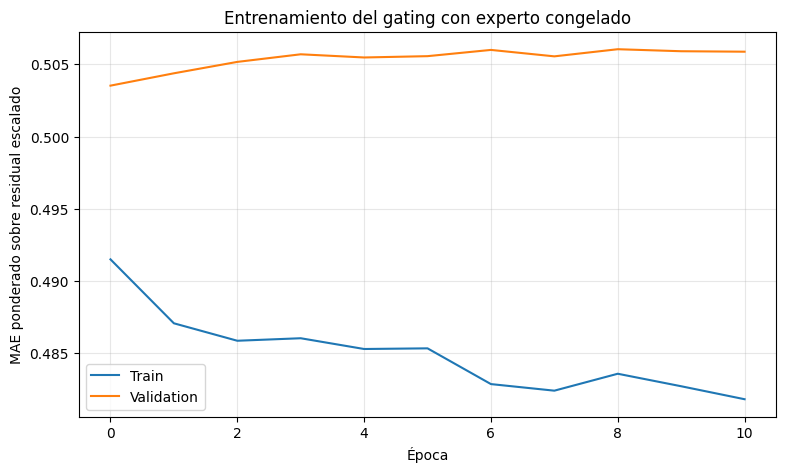

In [59]:
# =============================================================================
# CURVA DE ENTRENAMIENTO
# =============================================================================

if os.path.exists(FROZEN_GATE_HISTORY_PATH):

    # -------------------------------------------------------------------------
    # CARGA DEL HISTORIAL GUARDADO
    # -------------------------------------------------------------------------

    history_frozen_gate_df = pd.read_csv(
        FROZEN_GATE_HISTORY_PATH
    )


    # -------------------------------------------------------------------------
    # REPRESENTACIÓN
    # -------------------------------------------------------------------------

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        history_frozen_gate_df["loss"],
        label="Train"
    )

    plt.plot(
        history_frozen_gate_df["val_loss"],
        label="Validation"
    )

    plt.xlabel("Época")

    plt.ylabel(
        "MAE ponderado sobre residual escalado"
    )

    plt.title(
        "Entrenamiento del gating con experto congelado"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.show()


else:

    print(
        "⚠ No existe un historial de entrenamiento guardado."
    )

In [60]:
# =============================================================================
# PREDICCIÓN
# =============================================================================

frozen_gate_pred_scaled = (
    frozen_gate_model.predict(
        X_val_processed,
        verbose=0
    )
    .ravel()
)


frozen_gate_residual_pred = (
    target_scaler
    .inverse_transform(
        frozen_gate_pred_scaled.reshape(-1, 1)
    )
    .ravel()
)


y_pred_frozen_gate = (
    lag52_val
    + frozen_gate_residual_pred
)

In [61]:
# =============================================================================
# MÉTRICAS
# =============================================================================

metrics_frozen_gate = calculate_metrics(
    y_true,
    y_pred_frozen_gate,
    val_weights
)

In [62]:
# =============================================================================
# COMPARACIÓN DE TODOS LOS ENFOQUES
# =============================================================================

comparison_frozen_gate = pd.DataFrame([
    {
        "Modelo":
            "Baseline Lag_52",
        **metrics_baseline
    },
    {
        "Modelo":
            "MLP residual global",
        **metrics_mlp
    },
    {
        "Modelo":
            f"Hard gate Q{int(round(BEST_QUANTILE * 100))}",
        **metrics_experts
    },
    *([{"Modelo": "Soft MoE conjunto", **metrics_moe}] if RUN_SOFT_MOE else []),
    {
        "Modelo":
            "Gate + MLP congelada",
        **metrics_frozen_gate
    }
])


display(
    comparison_frozen_gate.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.9694
1,MLP residual global,"1,813.02","3,728.19","1,811.60",0.9721
2,Hard gate Q55,"1,792.14","3,728.63","1,782.72",0.9721
3,Soft MoE conjunto,"1,778.27","3,703.02","1,764.86",0.9725
4,Gate + MLP congelada,"1,800.91","3,719.78","1,797.78",0.9722


#### Pesos de la puerta aprendida

Una vez recuperados los pesos del modelo de *gating*, se construye un modelo auxiliar cuya salida corresponde directamente a la capa `gate_probability`.

Este modelo no realiza ningún entrenamiento adicional. Únicamente permite obtener, para cada observación de validación, el valor

$$
g(X)\in[0,1],
$$

que representa el peso asignado al experto neuronal.

La construcción de este modelo auxiliar y el cálculo de los valores del *gate* tienen un coste computacional reducido, por lo que se realizan nuevamente en cada ejecución del notebook y no es necesario almacenarlos de forma independiente.

In [63]:
# =============================================================================
# MODELO PARA EXTRAER LOS PESOS DEL GATE
# =============================================================================

gate_inspector = tf.keras.Model(
    inputs=frozen_gate_model.input,
    outputs=frozen_gate_model.get_layer(
        "gate_probability"
    ).output
)


gate_values_val = (
    gate_inspector.predict(
        X_val_processed,
        verbose=0
    )
    .ravel()
)

In [64]:
# =============================================================================
# DISTRIBUCIÓN DE LOS PESOS DEL GATE
# =============================================================================

display(
    pd.Series(
        gate_values_val,
        name="Gate_MLP"
    )
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .to_frame()
)

,Gate_MLP
count,112437.000000
mean,0.923261
std,0.056260
min,0.588902
1%,0.743102
5%,0.809522
10%,0.844715
25%,0.895752
50%,0.937460
75%,0.963421


In [65]:
# =============================================================================
# GATE SEGÚN RÉGIMEN SELECCIONADO
# =============================================================================

gate_by_segment = pd.DataFrame({

    "Segmento": np.where(
        lag52_val <= best_threshold,
        "Volumen bajo",
        "Volumen medio/alto"
    ),

    "Gate_MLP":
        gate_values_val
})


display(
    gate_by_segment
    .groupby("Segmento")["Gate_MLP"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

,count,mean,median,std,min,max
Segmento,,,,,,
Volumen bajo,63424,0.916246,0.930248,0.058788,0.590737,1.0
Volumen medio/alto,49013,0.932338,0.945383,0.051408,0.588902,1.0


In [66]:
# =============================================================================
# PESO MEDIO DEL GATE POR QUINTIL
# =============================================================================

validation_gate_analysis = (
    validation_residual[
        [
            "Lag_52"
        ]
    ]
    .copy()
)


validation_gate_analysis[
    "Gate_MLP"
] = gate_values_val


validation_gate_analysis[
    "Volume_Group"
] = pd.cut(
    validation_gate_analysis["Lag_52"],
    bins=bins,
    labels=labels,
    include_lowest=True
)


gate_by_quintile = (
    validation_gate_analysis
    .groupby(
        "Volume_Group",
        observed=True
    )["Gate_MLP"]
    .agg([
        "count",
        "mean",
        "median",
        "std"
    ])
)


display(
    gate_by_quintile.style.format({
        "mean": "{:.4f}",
        "median": "{:.4f}",
        "std": "{:.4f}"
    })
)

,count,mean,median,std
Volume_Group,,,,
Q1,23476,0.9007,0.9154,0.0657
Q2,22570,0.9246,0.9365,0.0518
Q3,22929,0.9252,0.9381,0.0533
Q4,21746,0.9287,0.9414,0.0517
Q5,21716,0.9388,0.9519,0.0494


#### Análisis del *soft gating* con experto congelado

El análisis de la puerta aprendida permite estudiar qué peso asigna a la corrección residual según el volumen histórico de ventas. Las tablas y gráficos de las celdas anteriores describen ese comportamiento en la ejecución actual. A diferencia del hard gating, la puerta puede reducir gradualmente la corrección sin descartarla por completo. La comparación de métricas de validación determina si esa flexibilidad mejora el sistema; no se trasladan aquí valores de una ejecución anterior.


## 6. MLP especializada en ventas medias y altas

Los análisis anteriores sugieren que el rendimiento de la MLP residual no es igual para todos los niveles de `Lag_52`. En las observaciones de menor volumen, el baseline anual obtiene mejores resultados, mientras que en las observaciones de volumen medio y alto la corrección de la MLP resulta más útil.

A partir de este comportamiento surge una nueva pregunta: **¿podría la MLP mejorar sus predicciones en las ventas medias y altas si se entrenara únicamente con observaciones de este tipo?**

Hasta ahora, la MLP global se ha entrenado utilizando conjuntamente observaciones con niveles de ventas muy diferentes. Es posible que esta variedad sea beneficiosa, ya que permite aprender patrones compartidos entre todo el conjunto de datos. Sin embargo, también cabe la posibilidad de que una red entrenada específicamente sobre las observaciones de mayor volumen pueda adaptarse mejor a sus características.

Para comprobarlo se plantea un nuevo experimento. Se entrena una MLP utilizando únicamente las observaciones que cumplen:

$$
Lag_{52}>c,
$$

donde $c$ es el umbral seleccionado anteriormente:

$$
c=Q_{35}.
$$

La nueva red mantiene las mismas variables de entrada y la misma arquitectura que la MLP residual global. La principal diferencia es, por tanto, el conjunto de observaciones utilizado durante el entrenamiento.

Para realizar una comparación justa, los modelos se evaluarán sobre las mismas observaciones de validación situadas por encima del umbral:

$$
\text{Baseline}
\quad vs \quad
\text{MLP global}
\quad vs \quad
\text{MLP especializada}.
$$

El objetivo no es asumir de antemano que separar las observaciones vaya a producir una mejora, sino comprobar si la especialización aporta alguna ventaja respecto a utilizar la MLP entrenada con todos los niveles de ventas.

Si la MLP especializada obtiene mejores resultados, esto sugeriría que centrar el entrenamiento en este subconjunto puede resultar beneficioso. Si, por el contrario, la MLP global mantiene un rendimiento igual o superior, indicaría que eliminar las observaciones de menor volumen no aporta una ventaja y que la información compartida durante el entrenamiento global puede seguir siendo útil.

In [67]:
# =============================================================================
# DIRECTORIO DE LA MLP ESPECIALIZADA
# =============================================================================

HIGH_MODEL_DIR = (
    "/content/drive/MyDrive/TFM/models/"
    "mlp_residual_high_specialist"
)

os.makedirs(
    HIGH_MODEL_DIR,
    exist_ok=True
)

In [68]:
# =============================================================================
# RÉGIMEN DE VENTAS MEDIAS / ALTAS
# =============================================================================

train_high = (
    train_residual[
        train_residual["Lag_52"] > best_threshold
    ]
    .copy()
)

validation_high = (
    validation_residual[
        validation_residual["Lag_52"] > best_threshold
    ]
    .copy()
)


print(
    f"Umbral utilizado: {best_threshold:,.2f}"
)

print("\nTRAIN")
print(
    f"{len(train_high):,} / {len(train_residual):,} "
    f"({100 * len(train_high) / len(train_residual):.2f}%)"
)

print("\nVALIDATION")
print(
    f"{len(validation_high):,} / {len(validation_residual):,} "
    f"({100 * len(validation_high) / len(validation_residual):.2f}%)"
)

Umbral utilizado: 9,861.66

TRAIN
67,097 / 149,104 (45.00%)

VALIDATION
49,013 / 112,437 (43.59%)


In [69]:
# =============================================================================
# MATRICES DEL MODELO ESPECIALIZADO
# =============================================================================

X_train_high = (
    train_high[
        model_features
    ]
    .copy()
)

y_train_high = (
    train_high[TARGET]
    .copy()
)


X_val_high = (
    validation_high[
        model_features
    ]
    .copy()
)

y_val_high = (
    validation_high[TARGET]
    .copy()
)


print("X_train_high:", X_train_high.shape)
print("y_train_high:", y_train_high.shape)

print("\nX_val_high:", X_val_high.shape)
print("y_val_high:", y_val_high.shape)

X_train_high: (67097, 23)
y_train_high: (67097,)

X_val_high: (49013, 23)
y_val_high: (49013,)


### 6.1. Preprocesamiento del especialista

La MLP especializada utiliza la misma estructura de preprocesamiento que la red global, pero sus parámetros se ajustan exclusivamente con las observaciones pertenecientes al régimen de ventas medio/alto.

Para ello se crea, cuando es necesario, una copia limpia del preprocesador global mediante `clone()`. Esta operación conserva la configuración del pipeline, pero no reutiliza parámetros aprendidos previamente, como medias, desviaciones, medianas o categorías.

A continuación, el nuevo preprocesador se ajusta únicamente sobre `train_high` y se aplica posteriormente a `validation_high`.

Si el preprocesador especializado ya fue ajustado y guardado en una ejecución anterior, se carga directamente desde Drive y se utiliza mediante `transform()`, evitando volver a ajustarlo.

De esta forma se garantiza que la MLP especializada trabaja con una representación coherente con la distribución del régimen para el que ha sido entrenada.

In [70]:
# =============================================================================
# CARGA O AJUSTE DEL PREPROCESAMIENTO ESPECIALIZADO
# =============================================================================

import os
import joblib

from sklearn.base import clone


HIGH_MODEL_DIR = (
    "/content/drive/MyDrive/TFM/models/"
    "mlp_residual_high_specialist"
)

os.makedirs(
    HIGH_MODEL_DIR,
    exist_ok=True
)


HIGH_PREPROCESSOR_PATH = (
    f"{HIGH_MODEL_DIR}/preprocessor.joblib"
)


HIGH_MODEL_PATH = f"{HIGH_MODEL_DIR}/model.keras"
HIGH_TARGET_SCALER_PATH = f"{HIGH_MODEL_DIR}/target_scaler.joblib"
FIRMA_HIGH = firma_entrenamiento(
    train_high, model_features, "Residual_52",
    {"modelo": "MLP_HIGH", "capas": [128, 64],
     "dropout": [0.20, 0.10], "loss": "mae", "lr": 1e-3,
     "epochs": 100, "batch": 256, "holiday_weight": 5,
     "best_threshold": float(best_threshold), "seed": SEED}
)
ENTRENAR_HIGH = plan_entrenamiento(
    "MLP especialista", HIGH_MODEL_PATH,
    [HIGH_PREPROCESSOR_PATH, HIGH_TARGET_SCALER_PATH], FIRMA_HIGH
)

if not ENTRENAR_HIGH and os.path.exists(HIGH_PREPROCESSOR_PATH):

    # -------------------------------------------------------------------------
    # PREPROCESADOR ESPECIALIZADO YA AJUSTADO
    # -------------------------------------------------------------------------

    preprocessor_high = joblib.load(
        HIGH_PREPROCESSOR_PATH
    )

    X_train_high_processed = (
        preprocessor_high.transform(
            X_train_high
        )
    )

    X_val_high_processed = (
        preprocessor_high.transform(
            X_val_high
        )
    )

    print(
        "✓ Preprocesador especializado cargado desde Drive."
    )


else:

    # -------------------------------------------------------------------------
    # PRIMERA EJECUCIÓN:
    # misma estructura que el preprocesador global,
    # pero ajustada exclusivamente sobre train_high
    # -------------------------------------------------------------------------

    preprocessor_high = clone(
        preprocessor
    )

    X_train_high_processed = (
        preprocessor_high.fit_transform(
            X_train_high
        )
    )

    X_val_high_processed = (
        preprocessor_high.transform(
            X_val_high
        )
    )


    joblib.dump(
        preprocessor_high,
        HIGH_PREPROCESSOR_PATH
    )

    print(
        "✓ Preprocesador especializado ajustado y guardado."
    )


print(
    "\nTrain especializado:",
    X_train_high_processed.shape
)

print(
    "Validation especializado:",
    X_val_high_processed.shape
)

MLP especialista: CARGAR
✓ Preprocesador especializado cargado desde Drive.

Train especializado: (67097, 135)
Validation especializado: (49013, 135)


In [71]:
# =============================================================================
# CONVERSIÓN A FLOAT32
# =============================================================================

if sparse.issparse(X_train_high_processed):
    X_train_high_processed = (
        X_train_high_processed.toarray()
    )

if sparse.issparse(X_val_high_processed):
    X_val_high_processed = (
        X_val_high_processed.toarray()
    )


X_train_high_processed = (
    X_train_high_processed.astype(np.float32)
)

X_val_high_processed = (
    X_val_high_processed.astype(np.float32)
)


print(
    "Train especializado:",
    X_train_high_processed.shape
)

print(
    "Validation especializado:",
    X_val_high_processed.shape
)

Train especializado: (67097, 135)
Validation especializado: (49013, 135)


**Escalado específico del target del especialista**

La MLP especializada utiliza un escalador propio para la variable objetivo porque se entrena únicamente con las observaciones del régimen de ventas medio/alto.

Aunque el target continúa siendo el mismo residual,

$$
Residual_{52}
=
Weekly\_Sales - Lag_{52},
$$

su distribución cambia al restringir el conjunto de entrenamiento a:

$$
Lag_{52}>Q_{35}.
$$

Por tanto, la media y la desviación típica del residual en `train_high` no tienen por qué coincidir con las obtenidas en el conjunto global.

El escalado especializado se define como:

$$
y'=
\frac{y-\mu_{\text{high}}}
{\sigma_{\text{high}}},
$$

donde $\mu_{\text{high}}$ y $\sigma_{\text{high}}$ se calculan exclusivamente sobre `y_train_high`.

De esta forma, la red especializada aprende sobre una escala adaptada a la distribución concreta de su régimen de entrenamiento.

Si el `target_scaler` especializado ya existe, se carga directamente; en caso contrario, se ajusta con `y_train_high` y se guarda para garantizar la reproducibilidad del modelo.

In [72]:
# =============================================================================
# CARGA O AJUSTE DEL ESCALADO DEL TARGET ESPECIALIZADO
# =============================================================================

HIGH_TARGET_SCALER_PATH = (
    f"{HIGH_MODEL_DIR}/target_scaler.joblib"
)


if not ENTRENAR_HIGH and os.path.exists(HIGH_TARGET_SCALER_PATH):

    # -------------------------------------------------------------------------
    # SCALER ESPECIALIZADO YA AJUSTADO
    # -------------------------------------------------------------------------

    target_scaler_high = joblib.load(
        HIGH_TARGET_SCALER_PATH
    )

    y_train_high_scaled = (
        target_scaler_high
        .transform(
            y_train_high
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    y_val_high_scaled = (
        target_scaler_high
        .transform(
            y_val_high
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    print(
        "✓ Target scaler especializado cargado desde Drive."
    )


else:

    # -------------------------------------------------------------------------
    # PRIMERA EJECUCIÓN: AJUSTE SOLO CON TRAIN_HIGH
    # -------------------------------------------------------------------------

    target_scaler_high = StandardScaler()

    y_train_high_scaled = (
        target_scaler_high
        .fit_transform(
            y_train_high
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    y_val_high_scaled = (
        target_scaler_high
        .transform(
            y_val_high
            .to_numpy()
            .reshape(-1, 1)
        )
        .ravel()
        .astype(np.float32)
    )

    joblib.dump(
        target_scaler_high,
        HIGH_TARGET_SCALER_PATH
    )

    print(
        "✓ Target scaler especializado ajustado y guardado."
    )


print(
    "\nMedia y_train_high_scaled:",
    y_train_high_scaled.mean()
)

print(
    "Std y_train_high_scaled:",
    y_train_high_scaled.std()
)

✓ Target scaler especializado cargado desde Drive.

Media y_train_high_scaled: -9.0965555e-09
Std y_train_high_scaled: 1.0


In [73]:
# =============================================================================
# ESCALADO DEL TARGET ESPECIALIZADO (SIN REAJUSTE DUPLICADO)
# =============================================================================
# El escalador y sus transformaciones ya han sido definidos en la celda anterior.
# No se debe volver a ajustar aquí: si se cargó la red, debe usarse SU escalador.
assert target_scaler_high.n_features_in_ == 1
print("✓ Target del especialista coherente con el escalador seleccionado.")

✓ Target del especialista coherente con el escalador seleccionado.


In [74]:
# =============================================================================
# PESOS WMAE
# =============================================================================

train_weights_high = np.where(
    train_high["IsHoliday"].to_numpy(),
    5.0,
    1.0
).astype(np.float32)


val_weights_high = np.where(
    validation_high["IsHoliday"].to_numpy(),
    5.0,
    1.0
).astype(np.float32)

### 6.2. Configuración y entrenamiento

In [75]:
# =============================================================================
# MLP ESPECIALIZADA EN VENTAS MEDIAS / ALTAS
# =============================================================================

tf.keras.utils.set_random_seed(SEED)


mlp_high = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(
            X_train_high_processed.shape[1],
        )
    ),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.20
    ),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.10
    ),

    tf.keras.layers.Dense(
        1,
        activation="linear"
    )
])


mlp_high.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mae"
)


mlp_high.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,729 (100.50 KB)

 Trainable params: 25,729 (100.50 KB)

 Non-trainable params: 0 (0.00 B)

In [76]:
# =============================================================================
# CALLBACKS
# =============================================================================

high_early_stopping = (
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
)


high_reduce_lr = (
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
)

In [77]:
# =============================================================================
# ENTRENAMIENTO O CARGA DE LA MLP ESPECIALIZADA
# =============================================================================

HIGH_MODEL_PATH = (
    f"{HIGH_MODEL_DIR}/model.keras"
)

HIGH_HISTORY_PATH = (
    f"{HIGH_MODEL_DIR}/history.csv"
)


if not ENTRENAR_HIGH:

    # -------------------------------------------------------------------------
    # MODELO YA ENTRENADO
    # -------------------------------------------------------------------------

    mlp_high = tf.keras.models.load_model(
        HIGH_MODEL_PATH
    )

    comprobar_entrada_modelo(mlp_high, X_train_high_processed.shape[1], "MLP especialista")
    print(
        "✓ MLP especializada cargada desde Drive."
    )


else:

    # -------------------------------------------------------------------------
    # MODELO NO EXISTENTE: ENTRENAR
    # -------------------------------------------------------------------------

    print(
        "Modelo especializado no encontrado. "
        "Comenzando entrenamiento..."
    )

    history_high = mlp_high.fit(

        X_train_high_processed,
        y_train_high_scaled,

        sample_weight=train_weights_high,

        validation_data=(
            X_val_high_processed,
            y_val_high_scaled,
            val_weights_high
        ),

        epochs=100,
        batch_size=256,

        callbacks=[
            high_early_stopping,
            high_reduce_lr
        ],

        verbose=1
    )


    # -------------------------------------------------------------------------
    # GUARDADO DEL MODELO
    # -------------------------------------------------------------------------

    mlp_high.save(
        HIGH_MODEL_PATH
    )


    # -------------------------------------------------------------------------
    # GUARDADO DEL HISTORIAL
    # -------------------------------------------------------------------------

    pd.DataFrame(
        history_high.history
    ).to_csv(
        HIGH_HISTORY_PATH,
        index=False
    )


    registrar_entrenamiento(HIGH_MODEL_PATH, FIRMA_HIGH)
    print(
        "✓ MLP especializada e historial guardados."
    )

✓ MLP especializada cargada desde Drive.


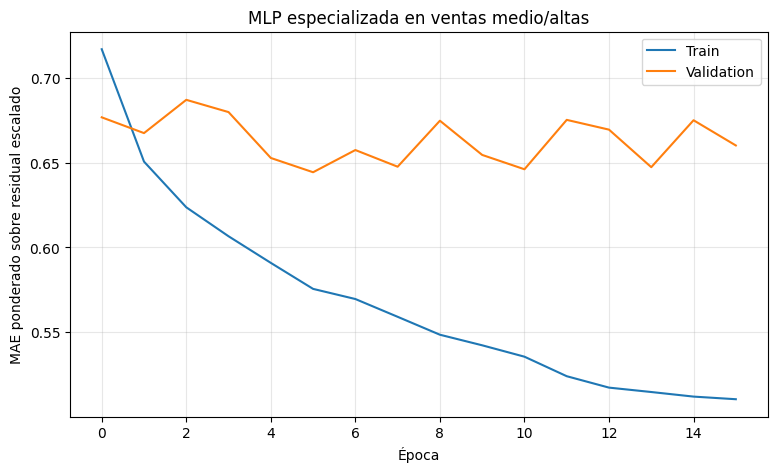

In [78]:
# =============================================================================
# CURVA DE APRENDIZAJE
# =============================================================================

if os.path.exists(HIGH_HISTORY_PATH):

    # -------------------------------------------------------------------------
    # CARGA DEL HISTORIAL GUARDADO
    # -------------------------------------------------------------------------

    history_high_df = pd.read_csv(
        HIGH_HISTORY_PATH
    )


    # -------------------------------------------------------------------------
    # REPRESENTACIÓN
    # -------------------------------------------------------------------------

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        history_high_df["loss"],
        label="Train"
    )

    plt.plot(
        history_high_df["val_loss"],
        label="Validation"
    )

    plt.xlabel("Época")

    plt.ylabel(
        "MAE ponderado sobre residual escalado"
    )

    plt.title(
        "MLP especializada en ventas medio/altas"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.show()


else:

    print(
        "⚠ No existe un historial de entrenamiento guardado."
    )

In [79]:
# =============================================================================
# PREDICCIÓN RESIDUAL
# =============================================================================

high_residual_pred_scaled = (
    mlp_high.predict(
        X_val_high_processed,
        verbose=0
    )
    .ravel()
)


high_residual_pred = (
    target_scaler_high
    .inverse_transform(
        high_residual_pred_scaled.reshape(-1, 1)
    )
    .ravel()
)

In [80]:
# =============================================================================
# RECONSTRUCCIÓN DE WEEKLY_SALES
# =============================================================================

y_true_high = (
    validation_high[
        "Weekly_Sales"
    ]
    .to_numpy()
)


lag52_high = (
    validation_high[
        "Lag_52"
    ]
    .to_numpy()
)


y_pred_high_specialist = (
    lag52_high
    + high_residual_pred
)

In [81]:
# =============================================================================
# MLP GLOBAL EN EL MISMO SEGMENTO
# =============================================================================

high_mask = (
    lag52_val > best_threshold
)


y_pred_high_global = (
    y_pred_mlp[
        high_mask
    ]
)


# Comprobación
assert len(y_pred_high_global) == len(
    y_pred_high_specialist
)

assert len(y_true_high) == len(
    y_pred_high_specialist
)

In [82]:
# =============================================================================
# COMPARACIÓN DENTRO DEL RÉGIMEN MEDIO / ALTO
# =============================================================================

metrics_high_baseline = calculate_metrics(
    y_true_high,
    lag52_high,
    val_weights_high
)


metrics_high_global = calculate_metrics(
    y_true_high,
    y_pred_high_global,
    val_weights_high
)


metrics_high_specialist = calculate_metrics(
    y_true_high,
    y_pred_high_specialist,
    val_weights_high
)


comparison_high = pd.DataFrame([
    {
        "Modelo":
            "Baseline Lag_52",
        **metrics_high_baseline
    },
    {
        "Modelo":
            "MLP global",
        **metrics_high_global
    },
    {
        "Modelo":
            "MLP especializada",
        **metrics_high_specialist
    }
])


display(
    comparison_high.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"3,330.66","5,715.59","3,329.06",0.9500
1,MLP global,"3,222.62","5,440.47","3,194.54",0.9547
2,MLP especializada,"3,353.13","5,521.12","3,328.51",0.9533


In [83]:
# =============================================================================
# GANANCIA POR ESPECIALIZACIÓN
# =============================================================================

improvement_high_vs_global = (
    (
        metrics_high_global["WMAE"]
        - metrics_high_specialist["WMAE"]
    )
    / metrics_high_global["WMAE"]
    * 100
)


improvement_high_vs_baseline = (
    (
        metrics_high_baseline["WMAE"]
        - metrics_high_specialist["WMAE"]
    )
    / metrics_high_baseline["WMAE"]
    * 100
)


print(
    "Mejora frente a MLP global:",
    f"{improvement_high_vs_global:+.2f}%"
)

print(
    "Mejora frente a Lag_52:",
    f"{improvement_high_vs_baseline:+.2f}%"
)

Mejora frente a MLP global: -4.19%
Mejora frente a Lag_52: +0.02%


In [84]:
# =============================================================================
# SISTEMA FINAL CON EXPERTO ESPECIALIZADO
# =============================================================================

y_pred_specialized_system = (
    lag52_val.copy()
)


y_pred_specialized_system[
    high_mask
] = y_pred_high_specialist

In [85]:
# =============================================================================
# EVALUACIÓN GLOBAL
# =============================================================================

metrics_specialized_system = (
    calculate_metrics(
        y_true,
        y_pred_specialized_system,
        val_weights
    )
)

In [86]:
# =============================================================================
# COMPARACIÓN DE SISTEMAS
# =============================================================================

comparison_specialists = pd.DataFrame([
    {
        "Modelo":
            "Baseline Lag_52",
        **metrics_baseline
    },
    {
        "Modelo":
            "MLP residual global",
        **metrics_mlp
    },
    {
        "Modelo":
            "Hard gate + MLP global",
        **metrics_experts
    },
    {
        "Modelo":
            "Hard gate + MLP especializada",
        **metrics_specialized_system
    }
])


display(
    comparison_specialists.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.9694
1,MLP residual global,"1,813.02","3,728.19","1,811.60",0.9721
2,Hard gate + MLP global,"1,792.14","3,728.63","1,782.72",0.9721
3,Hard gate + MLP especializada,"1,849.03","3,779.95","1,841.28",0.9713


### 6.3. Resultados del especialista

El especialista residual se entrena únicamente con las observaciones del régimen superior al umbral seleccionado, **Q55 (`Lag_52 > 9.861,66`)**, y se compara con la MLP global sobre ese mismo subconjunto. Las tablas generadas por las celdas anteriores permiten evaluar si la especialización mejora la predicción dentro del régimen de ventas altas y qué ocurre al integrarla en el sistema completo de hard gating.

Las métricas deben consultarse en esas tablas recalculadas, puesto que el cambio de Q35 a Q55 altera las observaciones utilizadas para entrenar y evaluar al especialista. En consecuencia, los resultados del régimen Q35 de ejecuciones anteriores no se trasladan a este apartado. La comparación posterior con *Feature Engineering* se realizará sobre una muestra común y con el umbral actual.


## 7. Representación de tienda y departamento mediante *embeddings*

Hasta ahora, `Store` y `Dept` se han tratado como variables categóricas mediante codificación *one-hot*. Esta decisión es importante porque, aunque ambas variables estén representadas originalmente mediante números, esos números funcionan únicamente como identificadores.

Por ejemplo, que una observación pertenezca a la tienda 20 y otra a la tienda 10 no significa que la primera tenga el doble de alguna característica que la segunda. Tampoco tendría sentido interpretar que las tiendas 10 y 11 son necesariamente más parecidas entre sí que las tiendas 10 y 30.

Por este motivo, en los modelos anteriores cada tienda se transforma mediante *one-hot encoding*. De forma simplificada, si existieran cuatro tiendas:

$$
Store_1=[1,0,0,0]
$$

$$
Store_2=[0,1,0,0]
$$

$$
Store_3=[0,0,1,0]
$$

$$
Store_4=[0,0,0,1].
$$

Esta representación resuelve el problema anterior: el modelo ya no interpreta el número de la tienda como una cantidad. Cada posición simplemente indica la pertenencia a una categoría.

Sin embargo, esta forma de representar las tiendas tiene otra característica: **todas se tratan inicialmente como categorías completamente independientes**. La representación de `Store_1` no contiene información que indique si su comportamiento puede parecerse más al de `Store_2` que al de `Store_4`.

Lo mismo sucede con los departamentos.

Esto lleva a plantear una representación diferente para estas dos variables: los ***embeddings***.

### ¿Qué es un embedding?

La idea básica es sustituir el vector de ceros y unos del *one-hot encoding* por un pequeño conjunto de números que la propia red neuronal aprende durante el entrenamiento.

Por ejemplo, en lugar de representar una tienda de esta forma:

$$
Store_{14}
=
[0,0,\ldots,1,\ldots,0],
$$

podríamos representarla mediante:

$$
Store_{14}
\longrightarrow
[0.31,-0.82,0.15,0.44].
$$

Estos números no corresponden a variables que existan originalmente en el dataset. No representan directamente características como el tamaño de la tienda, sus ventas medias o su localización. Son parámetros internos que la red aprende porque le resultan útiles para realizar la predicción.

Formalmente, a cada tienda $s$ se le asigna un vector:

$$
e_{\text{Store}}(s)\in\mathbb{R}^{d_s},
$$

donde $d_s$ indica cuántos valores se utilizan para representar cada tienda.

De la misma forma, cada departamento $d$ tiene su propio vector:

$$
e_{\text{Dept}}(d)\in\mathbb{R}^{d_d}.
$$

### ¿Cómo se obtienen estos valores?

Una diferencia importante respecto a otras variables del dataset es que **no es necesario decidir manualmente qué valores debe tener cada tienda o departamento**.

Al comenzar el entrenamiento, los vectores se inicializan con determinados valores y después se van modificando mediante el mismo proceso de aprendizaje utilizado para ajustar el resto de pesos de la red.

Es decir, cuando la red comete un error de predicción, la retropropagación no solo modifica las capas densas de la MLP. También puede modificar la representación interna asociada a las tiendas y departamentos que han participado en esas observaciones.

De forma simplificada, el proceso sería:

$$
\text{identificador de tienda}
\rightarrow
\text{vector aprendido}
\rightarrow
\text{MLP}
\rightarrow
\text{predicción}.
$$

El objetivo del entrenamiento sigue siendo exactamente el mismo que hasta ahora: reducir el error de predicción. La diferencia es que la red también aprende **cómo le resulta útil representar cada tienda y cada departamento para conseguirlo**.

### ¿Qué ventaja puede tener frente al one-hot encoding?

Con *one-hot encoding*, dos tiendas diferentes siempre tienen representaciones distintas y separadas. Con los *embeddings*, en cambio, la red dispone de libertad para aprender representaciones que compartan ciertas características.

Por ejemplo, después del entrenamiento podría ocurrir que:

$$
e_{\text{Store}}(4)
\approx
e_{\text{Store}}(23).
$$

Esto no significa necesariamente que podamos concluir que las tiendas 4 y 23 son similares desde un punto de vista comercial. Lo que podemos decir es que, para la tarea que estamos entrenando, la red ha encontrado útil asignarles representaciones parecidas.

Esta posibilidad resulta interesante en nuestro problema porque `Store` y `Dept` tienen una importancia considerable en el comportamiento de las ventas. Es razonable plantear que diferentes tiendas o departamentos puedan compartir determinados patrones que una representación aprendida sea capaz de aprovechar.

Por tanto, el objetivo de este experimento no es asumir que los *embeddings* serán superiores al *one-hot encoding*, sino comprobar si permitir que la red aprenda una representación propia de `Store` y `Dept` mejora la predicción del residuo.

### Integración con el resto de variables

La introducción de *embeddings* no modifica el tratamiento del resto de características.

Las variables numéricas, binarias y temporales continúan entrando en el modelo de forma similar a los experimentos anteriores. El cambio afecta principalmente a `Store` y `Dept`, que dejan de pasar por el *one-hot encoding* y disponen de sus propias capas de *embedding*.

Por tanto, pasamos de una estructura simplificada como:

$$
\text{Store/Dept}
\rightarrow
\text{One-Hot}
\rightarrow
\text{MLP}
$$

a procesar ambas variables por separado:

$$
\text{Store}
\rightarrow
\text{Embedding Store}
$$

$$
\text{Dept}
\rightarrow
\text{Embedding Dept}.
$$

Después, estas representaciones se unen con el resto de variables:

$$
[
e_{\text{Store}},
e_{\text{Dept}},
X_{\text{numérico}},
X_{\text{binario}},
X_{\text{temporal}}
]
\rightarrow
\text{MLP}.
$$

De forma esquemática:

```text
Store ─────► Embedding ─────┐
                            │
Dept ──────► Embedding ─────┤
                            │
Variables numéricas ────────┤
                            ├──► Concatenación
Variables binarias ─────────┤          │
                            │          ▼
Variables temporales ───────┘        Dense
                                       │
                                       ▼
                                     Dense
                                       │
                                       ▼
                               Residual predicho

In [87]:
# =============================================================================
# CONFIGURACIÓN DEL MODELO CON EMBEDDINGS
# =============================================================================

import os
import json
import joblib

EMBEDDING_MODEL_DIR = (
    "/content/drive/MyDrive/TFM/models/"
    "mlp_residual_high_embeddings"
)

os.makedirs(
    EMBEDDING_MODEL_DIR,
    exist_ok=True
)

EMBEDDING_MODEL_PATH = (
    f"{EMBEDDING_MODEL_DIR}/model.keras"
)

EMBEDDING_HISTORY_PATH = (
    f"{EMBEDDING_MODEL_DIR}/history.csv"
)

EMBEDDING_PREPROCESSOR_PATH = (
    f"{EMBEDDING_MODEL_DIR}/preprocessor.joblib"
)

EMBEDDING_MAPPING_PATH = (
    f"{EMBEDDING_MODEL_DIR}/category_mappings.json"
)
FIRMA_EMBEDDINGS = firma_entrenamiento(
    train_high, model_features, "Residual_52",
    {"modelo": "EMBEDDINGS_HIGH", "dim_store": 8, "dim_dept": 12,
     "capas": [128, 64], "dropout": [0.20, 0.10],
     "loss": "mae", "lr": 1e-3, "epochs": 100, "batch": 256,
     "holiday_weight": 5, "best_threshold": float(best_threshold),
     "firma_especialista": FIRMA_HIGH, "seed": SEED}
)
ENTRENAR_EMBEDDINGS = plan_entrenamiento(
    "MLP embeddings", EMBEDDING_MODEL_PATH,
    [EMBEDDING_PREPROCESSOR_PATH, EMBEDDING_MAPPING_PATH], FIRMA_EMBEDDINGS,
    forzar=ENTRENAR_HIGH
)

MLP embeddings: CARGAR


In [88]:
# =============================================================================
# COMPROBACIÓN DE CATEGORÍAS
# =============================================================================

train_stores = set(
    train_high["Store"].unique()
)

val_stores = set(
    validation_high["Store"].unique()
)

train_depts = set(
    train_high["Dept"].unique()
)

val_depts = set(
    validation_high["Dept"].unique()
)


unknown_stores_val = (
    val_stores - train_stores
)

unknown_depts_val = (
    val_depts - train_depts
)


print(
    "Stores en train_high:",
    len(train_stores)
)

print(
    "Depts en train_high:",
    len(train_depts)
)

print(
    "\nStores nuevos en validation:",
    sorted(unknown_stores_val)
)

print(
    "Depts nuevos en validation:",
    sorted(unknown_depts_val)
)

Stores en train_high: 45
Depts en train_high: 67

Stores nuevos en validation: []
Depts nuevos en validation: []


In [89]:
# =============================================================================
# CODIFICACIÓN DE STORE Y DEPT PARA EMBEDDINGS
# =============================================================================

if not ENTRENAR_EMBEDDINGS and os.path.exists(EMBEDDING_MAPPING_PATH):

    # -------------------------------------------------------------------------
    # CARGA DE MAPPINGS EXISTENTES
    # -------------------------------------------------------------------------

    with open(
        EMBEDDING_MAPPING_PATH,
        "r"
    ) as f:

        embedding_config = json.load(f)

    store_values = (
        embedding_config["store_values"]
    )

    dept_values = (
        embedding_config["dept_values"]
    )

    print(
        "✓ Mappings de embeddings cargados desde Drive."
    )


else:

    # -------------------------------------------------------------------------
    # CREACIÓN DE MAPPINGS A PARTIR DE TRAIN_HIGH
    # -------------------------------------------------------------------------

    store_values = sorted(
        int(x)
        for x in train_high["Store"].unique()
    )

    dept_values = sorted(
        int(x)
        for x in train_high["Dept"].unique()
    )


    embedding_config = {
        "store_values": store_values,
        "dept_values": dept_values
    }


    with open(
        EMBEDDING_MAPPING_PATH,
        "w"
    ) as f:

        json.dump(
            embedding_config,
            f,
            indent=4
        )

    print(
        "✓ Mappings de embeddings creados y guardados."
    )


# Índice 0 reservado para categorías desconocidas

store_to_index = {
    value: i + 1
    for i, value in enumerate(store_values)
}

dept_to_index = {
    value: i + 1
    for i, value in enumerate(dept_values)
}


N_STORES = len(store_values)
N_DEPTS = len(dept_values)


print(
    "\nNº tiendas:",
    N_STORES
)

print(
    "Nº departamentos:",
    N_DEPTS
)

✓ Mappings de embeddings cargados desde Drive.

Nº tiendas: 45
Nº departamentos: 67


In [90]:
# =============================================================================
# TRANSFORMACIÓN A ÍNDICES PARA EMBEDDINGS
# =============================================================================

def encode_category(series, mapping):

    return (
        series
        .map(mapping)
        .fillna(0)
        .astype(np.int32)
        .to_numpy()
    )


store_train_idx = encode_category(
    train_high["Store"],
    store_to_index
)

store_val_idx = encode_category(
    validation_high["Store"],
    store_to_index
)


dept_train_idx = encode_category(
    train_high["Dept"],
    dept_to_index
)

dept_val_idx = encode_category(
    validation_high["Dept"],
    dept_to_index
)


print(
    "Store train:",
    store_train_idx.shape
)

print(
    "Dept train:",
    dept_train_idx.shape
)

print(
    "\nCategorías desconocidas en validation:"
)

print(
    "Store:",
    np.sum(store_val_idx == 0)
)

print(
    "Dept:",
    np.sum(dept_val_idx == 0)
)

Store train: (67097,)
Dept train: (67097,)

Categorías desconocidas en validation:
Store: 0
Dept: 0


In [91]:
# =============================================================================
# VARIABLES NO REPRESENTADAS MEDIANTE EMBEDDINGS
# =============================================================================

embedding_numeric_features = [
    "Lag_52",
    "Temperature",
    "Fuel_Price",
    "Delta_Temperature",
    "Delta_Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "Size",
    "TimeIndex",
    "WeekSin",
    "WeekCos"
]


embedding_binary_features = [
    "IsHoliday",
    "MarkDown1_isna",
    "MarkDown2_isna",
    "MarkDown3_isna",
    "MarkDown4_isna",
    "MarkDown5_isna"
]


embedding_categorical_features = [
    "Type"
]


embedding_other_features = (
    embedding_numeric_features
    + embedding_binary_features
    + embedding_categorical_features
)

In [92]:
# =============================================================================
# VARIABLES RESTANTES
# =============================================================================

X_train_high_other = (
    train_high[
        embedding_other_features
    ]
    .copy()
)


X_val_high_other = (
    validation_high[
        embedding_other_features
    ]
    .copy()
)

In [93]:
# =============================================================================
# PREPROCESAMIENTO DE VARIABLES NO EMBEDDING
# =============================================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer


embedding_numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])


embedding_categorical_transformer = Pipeline([
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


embedding_preprocessor = ColumnTransformer([
    (
        "numeric",
        embedding_numeric_transformer,
        embedding_numeric_features
    ),
    (
        "categorical",
        embedding_categorical_transformer,
        embedding_categorical_features
    ),
    (
        "binary",
        "passthrough",
        embedding_binary_features
    )
])

In [94]:
# =============================================================================
# CARGA O AJUSTE DEL PREPROCESAMIENTO CON EMBEDDINGS
# =============================================================================

if not ENTRENAR_EMBEDDINGS and os.path.exists(
    EMBEDDING_PREPROCESSOR_PATH
):

    embedding_preprocessor = joblib.load(
        EMBEDDING_PREPROCESSOR_PATH
    )


    X_train_high_other_processed = (
        embedding_preprocessor.transform(
            X_train_high_other
        )
    )

    X_val_high_other_processed = (
        embedding_preprocessor.transform(
            X_val_high_other
        )
    )


    print(
        "✓ Preprocesador de embeddings cargado."
    )


else:

    X_train_high_other_processed = (
        embedding_preprocessor.fit_transform(
            X_train_high_other
        )
    )

    X_val_high_other_processed = (
        embedding_preprocessor.transform(
            X_val_high_other
        )
    )


    joblib.dump(
        embedding_preprocessor,
        EMBEDDING_PREPROCESSOR_PATH
    )


    print(
        "✓ Preprocesador de embeddings ajustado y guardado."
    )

✓ Preprocesador de embeddings cargado.


In [95]:
# =============================================================================
# CONVERSIÓN PARA TENSORFLOW
# =============================================================================

X_train_high_other_processed = (
    np.asarray(
        X_train_high_other_processed
    )
    .astype(np.float32)
)


X_val_high_other_processed = (
    np.asarray(
        X_val_high_other_processed
    )
    .astype(np.float32)
)


print(
    "Train:",
    X_train_high_other_processed.shape
)

print(
    "Validation:",
    X_val_high_other_processed.shape
)

Train: (67097, 23)
Validation: (49013, 23)


In [96]:
# =============================================================================
# ENTRADAS DEL MODELO
# =============================================================================

train_embedding_inputs = {

    "store_input":
        store_train_idx.reshape(-1, 1),

    "dept_input":
        dept_train_idx.reshape(-1, 1),

    "other_features":
        X_train_high_other_processed
}


val_embedding_inputs = {

    "store_input":
        store_val_idx.reshape(-1, 1),

    "dept_input":
        dept_val_idx.reshape(-1, 1),

    "other_features":
        X_val_high_other_processed
}

In [97]:
# =============================================================================
# ARQUITECTURA MLP ESPECIALIZADA CON EMBEDDINGS
# =============================================================================

STORE_EMBEDDING_DIM = 8
DEPT_EMBEDDING_DIM = 12


def build_embedding_model():

    tf.keras.utils.set_random_seed(
        SEED
    )


    # -------------------------------------------------------------------------
    # STORE
    # -------------------------------------------------------------------------

    store_input = tf.keras.layers.Input(
        shape=(1,),
        dtype="int32",
        name="store_input"
    )


    store_embedding = tf.keras.layers.Embedding(
        input_dim=N_STORES + 1,
        output_dim=STORE_EMBEDDING_DIM,
        name="store_embedding"
    )(
        store_input
    )


    store_embedding = (
        tf.keras.layers.Flatten()(
            store_embedding
        )
    )


    # -------------------------------------------------------------------------
    # DEPT
    # -------------------------------------------------------------------------

    dept_input = tf.keras.layers.Input(
        shape=(1,),
        dtype="int32",
        name="dept_input"
    )


    dept_embedding = tf.keras.layers.Embedding(
        input_dim=N_DEPTS + 1,
        output_dim=DEPT_EMBEDDING_DIM,
        name="dept_embedding"
    )(
        dept_input
    )


    dept_embedding = (
        tf.keras.layers.Flatten()(
            dept_embedding
        )
    )


    # -------------------------------------------------------------------------
    # RESTO DE VARIABLES
    # -------------------------------------------------------------------------

    other_input = tf.keras.layers.Input(
        shape=(
            X_train_high_other_processed.shape[1],
        ),
        dtype="float32",
        name="other_features"
    )


    # -------------------------------------------------------------------------
    # CONCATENACIÓN
    # -------------------------------------------------------------------------

    x = tf.keras.layers.Concatenate(
        name="feature_concatenation"
    )([
        store_embedding,
        dept_embedding,
        other_input
    ])


    # -------------------------------------------------------------------------
    # MLP
    # -------------------------------------------------------------------------

    x = tf.keras.layers.Dense(
        128,
        activation="relu"
    )(x)


    x = tf.keras.layers.Dropout(
        0.20
    )(x)


    x = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(x)


    x = tf.keras.layers.Dropout(
        0.10
    )(x)


    output = tf.keras.layers.Dense(
        1,
        activation="linear",
        name="residual_output"
    )(x)


    model_embeddings = tf.keras.Model(
        inputs=[
            store_input,
            dept_input,
            other_input
        ],
        outputs=output,
        name="High_Sales_MLP_Embeddings"
    )


    model_embeddings.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),

        loss="mae"
    )


    return model_embeddings

In [98]:
# =============================================================================
# CALLBACKS
# =============================================================================

embedding_early_stopping = (
    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=10,

        restore_best_weights=True,

        verbose=1
    )
)


embedding_reduce_lr = (
    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=5,

        min_lr=1e-6,

        verbose=1
    )
)

In [99]:
# =============================================================================
# ENTRENAMIENTO O CARGA DEL MODELO CON EMBEDDINGS
# =============================================================================

if not ENTRENAR_EMBEDDINGS:

    mlp_high_embeddings = (
        tf.keras.models.load_model(
            EMBEDDING_MODEL_PATH
        )
    )

    print(
        "✓ MLP especializada con embeddings cargada desde Drive."
    )


else:

    print(
        "Modelo con embeddings no encontrado. "
        "Comenzando entrenamiento..."
    )


    mlp_high_embeddings = (
        build_embedding_model()
    )


    history_embeddings = (
        mlp_high_embeddings.fit(

            train_embedding_inputs,

            y_train_high_scaled,

            sample_weight=
                train_weights_high,

            validation_data=(
                val_embedding_inputs,
                y_val_high_scaled,
                val_weights_high
            ),

            epochs=100,

            batch_size=256,

            callbacks=[
                embedding_early_stopping,
                embedding_reduce_lr
            ],

            verbose=1
        )
    )


    # -------------------------------------------------------------------------
    # GUARDADO DEL MODELO
    # -------------------------------------------------------------------------

    mlp_high_embeddings.save(
        EMBEDDING_MODEL_PATH
    )


    # -------------------------------------------------------------------------
    # GUARDADO DEL HISTORIAL
    # -------------------------------------------------------------------------

    pd.DataFrame(
        history_embeddings.history
    ).to_csv(
        EMBEDDING_HISTORY_PATH,
        index=False
    )


    registrar_entrenamiento(EMBEDDING_MODEL_PATH, FIRMA_EMBEDDINGS)
    print(
        "✓ Modelo con embeddings e historial guardados."
    )

✓ MLP especializada con embeddings cargada desde Drive.


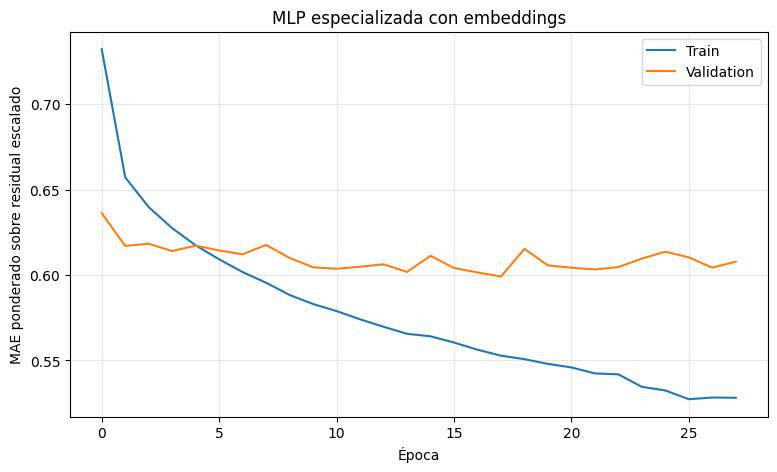

In [100]:
# =============================================================================
# CURVA DE APRENDIZAJE
# =============================================================================

if os.path.exists(
    EMBEDDING_HISTORY_PATH
):

    history_embeddings_df = (
        pd.read_csv(
            EMBEDDING_HISTORY_PATH
        )
    )


    plt.figure(
        figsize=(9, 5)
    )


    plt.plot(
        history_embeddings_df["loss"],
        label="Train"
    )


    plt.plot(
        history_embeddings_df["val_loss"],
        label="Validation"
    )


    plt.xlabel(
        "Época"
    )

    plt.ylabel(
        "MAE ponderado sobre residual escalado"
    )

    plt.title(
        "MLP especializada con embeddings"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.show()


else:

    print(
        "⚠ No existe historial de entrenamiento."
    )

In [101]:
# =============================================================================
# PREDICCIÓN DEL ESPECIALISTA CON EMBEDDINGS
# =============================================================================

embedding_residual_pred_scaled = (
    mlp_high_embeddings.predict(
        val_embedding_inputs,
        verbose=0
    )
    .ravel()
)


embedding_residual_pred = (
    target_scaler_high
    .inverse_transform(
        embedding_residual_pred_scaled
        .reshape(-1, 1)
    )
    .ravel()
)


y_pred_high_embeddings = (
    lag52_high
    + embedding_residual_pred
)

In [102]:
# =============================================================================
# EVALUACIÓN DEL ESPECIALISTA CON EMBEDDINGS
# =============================================================================

metrics_high_embeddings = (
    calculate_metrics(
        y_true_high,
        y_pred_high_embeddings,
        val_weights_high
    )
)


comparison_embeddings_high = pd.DataFrame([
    {
        "Modelo":
            "Baseline Lag_52",
        **metrics_high_baseline
    },
    {
        "Modelo":
            "MLP global",
        **metrics_high_global
    },
    {
        "Modelo":
            "MLP especializada One-Hot",
        **metrics_high_specialist
    },
    {
        "Modelo":
            "MLP especializada Embeddings",
        **metrics_high_embeddings
    }
])


display(
    comparison_embeddings_high.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"3,330.66","5,715.59","3,329.06",0.9500
1,MLP global,"3,222.62","5,440.47","3,194.54",0.9547
2,MLP especializada One-Hot,"3,353.13","5,521.12","3,328.51",0.9533
3,MLP especializada Embeddings,"3,130.16","5,359.79","3,095.05",0.9560


In [103]:
# =============================================================================
# SISTEMA HARD GATE + MLP CON EMBEDDINGS
# =============================================================================

high_mask_embeddings = (
    validation_residual[
        "Lag_52"
    ]
    .to_numpy()
    > best_threshold
)


assert (
    high_mask_embeddings.sum()
    ==
    len(y_pred_high_embeddings)
)


y_pred_embedding_system = (
    validation_residual[
        "Lag_52"
    ]
    .to_numpy()
    .copy()
)


y_pred_embedding_system[
    high_mask_embeddings
] = y_pred_high_embeddings

In [104]:
# =============================================================================
# EVALUACIÓN GLOBAL
# =============================================================================

metrics_embedding_system = (
    calculate_metrics(
        y_true,
        y_pred_embedding_system,
        val_weights
    )
)

In [105]:
# =============================================================================
# COMPARACIÓN FINAL DE SISTEMAS
# =============================================================================

comparison_embedding_system = pd.DataFrame([
    {
        "Modelo":
            "Baseline Lag_52",
        **metrics_baseline
    },
    {
        "Modelo":
            "MLP residual global",
        **metrics_mlp
    },
    {
        "Modelo":
            "Hard gate + MLP global",
        **metrics_experts
    },
    {
        "Modelo":
            "Hard gate + MLP especializada One-Hot",
        **metrics_specialized_system
    },
    {
        "Modelo":
            "Hard gate + MLP especializada Embeddings",
        **metrics_embedding_system
    }
])


display(
    comparison_embedding_system.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WMAE": "{:,.2f}",
        "R2": "{:.4f}"
    })
)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.9694
1,MLP residual global,"1,813.02","3,728.19","1,811.60",0.9721
2,Hard gate + MLP global,"1,792.14","3,728.63","1,782.72",0.9721
3,Hard gate + MLP especializada One-Hot,"1,849.03","3,779.95","1,841.28",0.9713
4,Hard gate + MLP especializada Embeddings,"1,751.83","3,677.34","1,739.23",0.9729


### 7.1. Resultados del especialista con embeddings

Se compara la representación categórica mediante *one-hot encoding* con una alternativa basada en *embeddings* para `Store` y `Dept`, manteniendo el planteamiento de especialista residual. Las métricas se muestran en las tablas calculadas por las celdas anteriores y deben interpretarse dentro del régimen de ventas seleccionado en la ejecución actual.

Esta comparación permite estudiar si aprender representaciones densas de las categorías aporta una ventaja frente a la codificación explícita. No se extrapolan las cifras de ejecuciones anteriores basadas en Q35, porque la población de entrenamiento y evaluación cambió al seleccionar Q55. La selección final de arquitectura se realiza posteriormente, tras incorporar las variables de *Feature Engineering*.


## 8. Ampliación de las variables a partir del análisis exploratorio

Hasta este punto, gran parte de los experimentos se han centrado en modificar la arquitectura o la forma en la que el modelo utiliza las variables disponibles. Sin embargo, otra posible vía de mejora consiste en revisar la propia información que recibe el modelo.

Por este motivo, en esta sección volvemos sobre algunos patrones y características detectados durante el análisis exploratorio para realizar una nueva fase de **ingeniería de variables (*feature engineering*)**.

El objetivo consiste en crear nuevas variables a partir de la información ya disponible en el dataset, buscando representar de forma más adecuada determinados patrones que las variables utilizadas hasta ahora pueden no estar recogiendo completamente.

Estas nuevas características no incorporan fuentes de información externas, sino que se construyen a partir de los propios datos disponibles y respetando en todo momento el orden temporal, de forma que cada predicción utilice únicamente información que habría estado disponible en ese momento.

En los siguientes apartados se presentan las nuevas variables incorporadas, la motivación de cada una y su forma de construcción.

### 8.1. Tipo de festividad

`HolidayType` separa Super Bowl, Labor Day, Thanksgiving y Christmas; el resto de fechas recibe la categoría `None`. El diccionario utiliza las fechas semanales marcadas en el conjunto de datos, que no tienen por qué coincidir con el día natural de la celebración.

Comprobamos su correspondencia con `IsHoliday` y las campañas presentes en cada partición. Como ya se señaló en el segundo notebook, validación contiene Super Bowl y Labor Day, mientras que el test también incluye Thanksgiving y Christmas. Tener horizontes de la misma duración no asegura la misma cobertura estacional.

In [106]:
# =============================================================================
# COPIAS PARA LA NUEVA FASE DE FEATURE ENGINEERING
# =============================================================================

train_enriched = (
    train
    .copy()
)

validation_enriched = (
    validation
    .copy()
)

test_enriched = (
    test
    .copy()
)


print(
    "Train:",
    train_enriched.shape
)

print(
    "Validation:",
    validation_enriched.shape
)

print(
    "Test:",
    test_enriched.shape
)

Train: (305982, 35)
Validation: (115588, 35)
Test: (115064, 33)


In [107]:
# =============================================================================
# DEFINICIÓN DE LOS FESTIVOS DEL DATASET
# =============================================================================

holiday_dates = {

    # -------------------------------------------------------------------------
    # SUPER BOWL
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-02-12"):
        "SuperBowl",

    pd.Timestamp("2011-02-11"):
        "SuperBowl",

    pd.Timestamp("2012-02-10"):
        "SuperBowl",

    pd.Timestamp("2013-02-08"):
        "SuperBowl",


    # -------------------------------------------------------------------------
    # LABOR DAY
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-09-10"):
        "LaborDay",

    pd.Timestamp("2011-09-09"):
        "LaborDay",

    pd.Timestamp("2012-09-07"):
        "LaborDay",


    # -------------------------------------------------------------------------
    # THANKSGIVING
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-11-26"):
        "Thanksgiving",

    pd.Timestamp("2011-11-25"):
        "Thanksgiving",

    pd.Timestamp("2012-11-23"):
        "Thanksgiving",


    # -------------------------------------------------------------------------
    # CHRISTMAS
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-12-31"):
        "Christmas",

    pd.Timestamp("2011-12-30"):
        "Christmas",

    pd.Timestamp("2012-12-28"):
        "Christmas"
}

In [108]:
# =============================================================================
# CREACIÓN DE HOLIDAYTYPE
# =============================================================================

HOLIDAY_CATEGORIES = [
    "None",
    "SuperBowl",
    "LaborDay",
    "Thanksgiving",
    "Christmas"
]


def add_holiday_type(df):

    df = df.copy()

    df["HolidayType"] = (
        df["Date"]
        .map(
            holiday_dates
        )
        .fillna(
            "None"
        )
    )


    df["HolidayType"] = pd.Categorical(
        df["HolidayType"],
        categories=HOLIDAY_CATEGORIES
    )


    return df

In [109]:
# =============================================================================
# APLICACIÓN A TRAIN, VALIDATION Y TEST
# =============================================================================

train_enriched = add_holiday_type(
    train_enriched
)

validation_enriched = add_holiday_type(
    validation_enriched
)

test_enriched = add_holiday_type(
    test_enriched
)


print(
    "✓ HolidayType incorporado."
)

✓ HolidayType incorporado.


In [110]:
# =============================================================================
# VALIDACIÓN DE HOLIDAYTYPE
# =============================================================================

def validate_holiday_type(
    df,
    dataset_name
):

    expected_holiday = (
        df["HolidayType"]
        .astype(str)
        .ne("None")
    )


    consistency = (
        expected_holiday
        ==
        df["IsHoliday"].astype(bool)
    )


    print(
        f"\n{dataset_name}"
    )

    print(
        "Filas:",
        f"{len(df):,}"
    )

    print(
        "Coincidencias:",
        f"{consistency.sum():,}"
    )

    print(
        "Discrepancias:",
        f"{(~consistency).sum():,}"
    )


    if not consistency.all():

        display(
            df.loc[
                ~consistency,
                [
                    "Date",
                    "IsHoliday",
                    "HolidayType"
                ]
            ]
            .drop_duplicates()
            .sort_values(
                "Date"
            )
        )


validate_holiday_type(
    train_enriched,
    "TRAIN"
)

validate_holiday_type(
    validation_enriched,
    "VALIDATION"
)

validate_holiday_type(
    test_enriched,
    "TEST"
)


TRAIN
Filas: 305,982
Coincidencias: 305,982
Discrepancias: 0

VALIDATION
Filas: 115,588
Coincidencias: 115,588
Discrepancias: 0

TEST
Filas: 115,064
Coincidencias: 115,064
Discrepancias: 0


In [111]:
# =============================================================================
# FECHAS FESTIVAS PRESENTES EN CADA DATASET
# =============================================================================

for name, df in [

    ("TRAIN", train_enriched),
    ("VALIDATION", validation_enriched),
    ("TEST", test_enriched)

]:

    print(
        f"\n{name}"
    )

    display(
        df.loc[
            df["HolidayType"]
            .astype(str)
            .ne("None"),
            [
                "Date",
                "HolidayType"
            ]
        ]
        .drop_duplicates()
        .sort_values("Date")
        .reset_index(drop=True)
    )


TRAIN


,Date,HolidayType
0,2010-02-12,SuperBowl
1,2010-09-10,LaborDay
2,2010-11-26,Thanksgiving
3,2010-12-31,Christmas
4,2011-02-11,SuperBowl
5,2011-09-09,LaborDay
6,2011-11-25,Thanksgiving
7,2011-12-30,Christmas



VALIDATION


,Date,HolidayType
0,2012-02-10,SuperBowl
1,2012-09-07,LaborDay



TEST


,Date,HolidayType
0,2012-11-23,Thanksgiving
1,2012-12-28,Christmas
2,2013-02-08,SuperBowl


### 8.2. Huecos internos y cobertura potencial

Retomamos el diagnóstico de continuidad del primer notebook sobre el histórico completo de ventas conocidas, formado por entrenamiento interno y validación. Aquí interesa la longitud de cada hueco, no solo el número total de semanas ausentes de una serie.

La tabla calcula cuántas semanas podrían recuperarse para distintos límites de longitud. La columna `Percentage_internal_gaps` conserva su nombre original, pero expresa un porcentaje de **semanas ausentes internas**, no de huecos. El experimento posterior de reconstrucción de ventas conocidas se realiza únicamente sobre el entrenamiento interno.

In [112]:
# =============================================================================
# HISTÓRICO COMPLETO CON WEEKLY_SALES CONOCIDO
# =============================================================================

sales_history = (
    pd.concat(
        [
            train_enriched,
            validation_enriched
        ],
        axis=0,
        ignore_index=True
    )
    .sort_values(
        [
            "Store",
            "Dept",
            "Date"
        ]
    )
    .reset_index(drop=True)
)


print(
    "Filas:",
    f"{len(sales_history):,}"
)

print(
    "Fecha mínima:",
    sales_history["Date"].min()
)

print(
    "Fecha máxima:",
    sales_history["Date"].max()
)

print(
    "Pares Store-Dept:",
    sales_history[
        ["Store", "Dept"]
    ]
    .drop_duplicates()
    .shape[0]
)

Filas: 421,570
Fecha mínima: 2010-02-05 00:00:00
Fecha máxima: 2012-10-26 00:00:00
Pares Store-Dept: 3331


In [113]:
# =============================================================================
# DISTANCIA TEMPORAL ENTRE OBSERVACIONES CONSECUTIVAS
# =============================================================================

gap_analysis = (
    sales_history[
        [
            "Store",
            "Dept",
            "Date"
        ]
    ]
    .copy()
)


gap_analysis["Previous_Date"] = (
    gap_analysis
    .groupby(
        ["Store", "Dept"]
    )["Date"]
    .shift(1)
)


gap_analysis["Days_Between"] = (
    gap_analysis["Date"]
    -
    gap_analysis["Previous_Date"]
).dt.days


gap_analysis["Weeks_Between"] = (
    gap_analysis["Days_Between"]
    / 7
)


# Número de semanas ausentes ENTRE ambas observaciones
gap_analysis["Missing_Weeks"] = (
    gap_analysis["Weeks_Between"]
    - 1
)


internal_gaps = (
    gap_analysis[
        gap_analysis["Missing_Weeks"] > 0
    ]
    .copy()
)


print(
    "Saltos temporales internos:",
    f"{len(internal_gaps):,}"
)

print(
    "Semanas ausentes acumuladas:",
    f"{internal_gaps['Missing_Weeks'].sum():,.0f}"
)

Saltos temporales internos: 5,447
Semanas ausentes acumuladas: 27,667


In [114]:
# =============================================================================
# DISTRIBUCIÓN DE LOS HUECOS INTERNOS
# =============================================================================

gap_length_distribution = (
    internal_gaps["Missing_Weeks"]
    .astype(int)
    .value_counts()
    .sort_index()
    .rename_axis(
        "Semanas_consecutivas_ausentes"
    )
    .reset_index(
        name="Numero_huecos"
    )
)


gap_length_distribution[
    "Observaciones_recuperables"
] = (
    gap_length_distribution[
        "Semanas_consecutivas_ausentes"
    ]
    *
    gap_length_distribution[
        "Numero_huecos"
    ]
)


display(
    gap_length_distribution.head(20)
)

,Semanas_consecutivas_ausentes,Numero_huecos,Observaciones_recuperables
0,1,2346,2346
1,2,862,1724
2,3,517,1551
3,4,338,1352
4,5,214,1070
5,6,150,900
6,7,145,1015
7,8,117,936
8,9,101,909
9,10,72,720


In [115]:
# =============================================================================
# COBERTURA POTENCIAL SEGÚN LONGITUD MÁXIMA DEL HUECO
# =============================================================================

recovery_summary = []

total_missing_internal = (
    internal_gaps["Missing_Weeks"]
    .sum()
)


for max_gap in [
    1,
    2,
    3,
    4,
    5,
    8,
    13
]:

    recoverable = (
        internal_gaps.loc[
            internal_gaps[
                "Missing_Weeks"
            ] <= max_gap,
            "Missing_Weeks"
        ]
        .sum()
    )


    recovery_summary.append({
        "Max_gap": max_gap,
        "Recoverable_weeks":
            int(recoverable),
        "Percentage_internal_gaps":
            100
            * recoverable
            / total_missing_internal
    })


recovery_summary = pd.DataFrame(
    recovery_summary
)


display(
    recovery_summary.style.format({
        "Percentage_internal_gaps":
            "{:.2f}%"
    })
)

,Max_gap,Recoverable_weeks,Percentage_internal_gaps
0,1,2346,8.48%
1,2,4070,14.71%
2,3,5621,20.32%
3,4,6973,25.20%
4,5,8043,29.07%
5,8,10894,39.38%
6,13,14245,51.49%


In [116]:
# =============================================================================
# PARES STORE-DEPT AFECTADOS
# =============================================================================

pairs_with_gaps = (
    internal_gaps[
        [
            "Store",
            "Dept"
        ]
    ]
    .drop_duplicates()
)


all_pairs = (
    sales_history[
        [
            "Store",
            "Dept"
        ]
    ]
    .drop_duplicates()
)


print(
    "Pares totales:",
    f"{len(all_pairs):,}"
)

print(
    "Pares con al menos un hueco interno:",
    f"{len(pairs_with_gaps):,}"
)

print(
    "Porcentaje:",
    f"{100 * len(pairs_with_gaps) / len(all_pairs):.2f}%"
)

Pares totales: 3,331
Pares con al menos un hueco interno: 605
Porcentaje: 18.16%


### 8.3. Criterios para estudiar la interpolación

Antes de completar los huecos temporales del histórico de ventas es necesario determinar qué compromiso entre cobertura y error ofrece cada longitud de hueco.

La decisión no debe basarse únicamente en cuántas observaciones pueden recuperarse. Permitir huecos cada vez mayores aumenta la cobertura del dataset, pero también obliga a asumir que las ventas evolucionan de forma suficientemente continua entre dos observaciones alejadas en el tiempo. Esta hipótesis puede dejar de ser razonable cuando existen cambios bruscos asociados a estacionalidad, promociones, festivos o variaciones específicas de cada combinación `Store-Dept`.

Por este motivo, la longitud máxima de interpolación se seleccionará evaluando conjuntamente los siguientes aspectos.

#### 1. Cobertura recuperada

Para cada longitud máxima de hueco $k$ se calculará cuántas semanas internas ausentes podrían reconstruirse.

Por ejemplo:

$$
k \in \{1,2,3,4,5,8,13\}
$$

permitirá conocer la relación entre la complejidad asumida y la cantidad de información recuperada.

Esta medida responde a la pregunta:

> ¿Cuántas observaciones adicionales conseguimos al permitir huecos de hasta $k$ semanas?

Sin embargo, una mayor cobertura no implica necesariamente una mejor reconstrucción, por lo que esta medida nunca se utilizará de forma aislada.

---

#### 2. Error de reconstrucción mediante enmascaramiento artificial

El criterio principal será comprobar qué capacidad tiene la interpolación para reconstruir valores de ventas que realmente conocemos.

Para ello se utilizan ventanas completas del entrenamiento interno y se ocultan artificialmente uno o varios valores consecutivos. Las ventas ocultadas se conservan aparte para evaluar la reconstrucción.

Por ejemplo:

$$
Y_{t-1},\quad Y_t,\quad Y_{t+1}
$$

se transforma temporalmente en:

$$
Y_{t-1},\quad ?,\quad Y_{t+1}.
$$

El valor ocultado se reconstruye mediante interpolación lineal:

$$
\hat{Y}_t=
Y_{t-1}
+
\frac{Y_{t+1}-Y_{t-1}}{2}.
$$

En el caso de ocultar $k$ semanas consecutivas, se interpolarán todos los puntos comprendidos entre los dos extremos conocidos.

Como los valores originales siguen estando disponibles para la evaluación, será posible comparar:

$$
Y_t
\qquad \text{frente a} \qquad
\hat{Y}_t.
$$

De esta comparación se calcularán principalmente:

$$
MAE=
\frac{1}{n}
\sum_{i=1}^{n}
|Y_i-\hat{Y}_i|
$$

y

$$
RMSE=
\sqrt{
\frac{1}{n}
\sum_{i=1}^{n}
(Y_i-\hat{Y}_i)^2
}.
$$

El `MAE` indicará el error medio introducido por la reconstrucción, mientras que el `RMSE` permitirá detectar si existen casos con errores especialmente elevados.

---

#### 3. Error relativo al nivel de ventas

El error absoluto debe interpretarse teniendo en cuenta la escala de ventas.

Un error de 1.000 unidades monetarias puede ser muy importante para un departamento que vende 2.000 por semana, pero relativamente pequeño para otro que vende 50.000.

Por este motivo también se calculará una medida normalizada:

$$
NMAE=
\frac{MAE}
{\operatorname{media}(|Y|)}.
$$

Esta métrica permitirá comparar la calidad de la interpolación entre huecos de distinta longitud sin que el resultado dependa únicamente del volumen absoluto de ventas.

---

#### 4. Evolución del error con la longitud del hueco

No solo interesa conocer el error para cada caso de forma independiente, sino estudiar cómo evoluciona a medida que aumenta la longitud del periodo reconstruido.

Se compara la evolución del error entre longitudes, sin exigir que aumente de forma estricta en cada paso.

Es esperable que reconstruir una única semana sea más fiable que reconstruir ocho o trece semanas consecutivas.

La longitud máxima se situará antes del punto en el que el error comience a aumentar de forma suficientemente importante como para que la ganancia de cobertura deje de compensar la pérdida de calidad.

Por tanto, no se buscará necesariamente el hueco máximo que pueda interpolarse, sino un compromiso entre:

$$
\boxed{
\text{Cobertura recuperada}
\quad \leftrightarrow \quad
\text{Error introducido}
}
$$

---

#### 5. Comportamiento en semanas festivas

Las semanas festivas presentan un comportamiento especialmente relevante en este dataset y ya se ha observado que los errores de predicción son mayores durante estos periodos.

Una interpolación lineal puede funcionar correctamente durante semanas ordinarias, pero fallar al intentar reconstruir un pico asociado a eventos como:

- `SuperBowl`,
- `LaborDay`,
- `Thanksgiving`,
- `Christmas`.

Por ello se evaluará el error de interpolación por separado para:

$$
IsHoliday = 0
$$

y

$$
IsHoliday = 1.
$$

El desglose por cada `HolidayType` quedó como una posibilidad; no se desarrolla en este experimento.

Si la reconstrucción resulta claramente peor en semanas festivas, podría establecerse una regla adicional que impida interpolar aquellas observaciones correspondientes a estos eventos.

---

#### 6. Comportamiento según el volumen de ventas

Las series `Store-Dept` presentan niveles de ventas muy diferentes.

Dado que anteriormente se observó que los departamentos de mayor volumen concentran gran parte del error absoluto, también será conveniente comprobar si la calidad de la interpolación depende del nivel de ventas.

En este experimento se forman grupos según el valor absoluto de la venta real ocultada, a diferencia de los quintiles anteriores definidos con `Lag_52`:

$$
Q_1,\ Q_2,\ Q_3,\ Q_4,\ Q_5.
$$

Este desglose es descriptivo: la venta oculta se conoce en el experimento, pero no estaría disponible al reconstruir un hueco real. Por tanto, no se utiliza para decidir qué huecos interpolar.

---

#### 7. Sesgo de la reconstrucción

Además del tamaño del error, interesa comprobar si la interpolación introduce un sesgo sistemático.

Se calculará:

$$
Bias=
\frac{1}{n}
\sum_{i=1}^{n}
(Y_i-\hat{Y}_i).
$$

Un valor próximo a cero indicaría que los errores positivos y negativos tienden a compensarse.

Por el contrario, un sesgo claramente positivo o negativo indicaría que la interpolación tiende sistemáticamente a infraestimar o sobreestimar las ventas.

Este punto es especialmente importante porque los valores reconstruidos se utilizarán posteriormente para generar lags y, por tanto, cualquier sesgo podría propagarse a las variables predictoras futuras.

---

#### 8. Número de ejemplos utilizados en la evaluación

Cada longitud de hueco debe evaluarse utilizando un número suficiente de ejemplos.

Un error aparentemente bajo calculado a partir de muy pocas secuencias no constituye una evidencia sólida.

Por este motivo, junto con cada métrica se almacenará el número de observaciones evaluadas:

$$
N_k.
$$

Las ventanas pueden solaparse. Por eso, $N_k$ cuenta reconstrucciones evaluadas y una misma observación original puede aparecer varias veces. No representa filas distintas ni observaciones independientes, lo que explica que algunos recuentos superen el tamaño del entrenamiento.

---

#### 9. Prevención de *data leakage*

La reconstrucción se utilizará únicamente para completar información histórica destinada a generar variables predictoras futuras.

Los valores interpolados no se consideran nuevas ventas observadas. Sí pueden intervenir en el retardo que después se resta a `Weekly_Sales` para definir el objetivo residual.

Además, para una predicción correspondiente a una fecha $T$, cualquier observación utilizada durante la reconstrucción deberá satisfacer:

$$
\max(\text{fecha utilizada para reconstruir}) < T.
$$

Aunque la interpolación utilice una semana posterior al hueco, esa semana debe seguir siendo anterior a la fecha objetivo. Para validación se consulta únicamente el histórico del entrenamiento interno; para test puede utilizarse también la validación, ya conocida antes de comenzar ese horizonte. La condición de anterioridad a cada fecha objetivo no sustituye esta separación por cortes temporales.

---

#### Criterio de selección

La longitud máxima de hueco permitida se determinará combinando:

- porcentaje de semanas recuperadas;
- `MAE` de reconstrucción;
- `RMSE` de reconstrucción;
- error relativo (`NMAE`);
- sesgo medio;
- estabilidad del error al aumentar la longitud del hueco;
- comportamiento específico en semanas festivas;
- comportamiento según el volumen de ventas;
- número de ejemplos disponibles para cada longitud.

El límite se adopta como un compromiso a partir de estos resultados. No se calcula una función que determine automáticamente una longitud óptima ni se demuestra que el error en los huecos reales sea idéntico al del enmascaramiento.

El objetivo es recuperar parte del historial sin perder de vista el error introducido y las restricciones temporales de su uso posterior.

In [117]:
# =============================================================================
# EVALUACIÓN DE LA INTERPOLACIÓN SOBRE DATOS CONOCIDOS
# =============================================================================

def evaluate_interpolation_gap(
    df,
    gap_size
):

    errors = []
    records = []

    # -------------------------------------------------------------------------
    # Trabajamos por cada serie Store-Dept
    # -------------------------------------------------------------------------

    for (store, dept), group in df.groupby(
        ["Store", "Dept"],
        sort=False
    ):

        group = (
            group[
                ["Date", "Weekly_Sales", "IsHoliday"]
            ]
            .sort_values("Date")
            .reset_index(drop=True)
        )

        dates = group["Date"].to_numpy()
        sales = group["Weekly_Sales"].to_numpy()
        holidays = group["IsHoliday"].to_numpy()

        n = len(group)

        # Necesitamos:
        #
        # extremo izquierdo
        # gap_size observaciones interiores
        # extremo derecho
        #
        window_size = gap_size + 2

        if n < window_size:
            continue


        for start in range(
            0,
            n - window_size + 1
        ):

            end = start + gap_size + 1

            # -------------------------------------------------------------
            # Comprobamos que todas las fechas del intervalo están
            # realmente separadas exactamente una semana.
            # -------------------------------------------------------------

            expected_days = (
                (gap_size + 1) * 7
            )

            actual_days = (
                dates[end] - dates[start]
            ) / np.timedelta64(1, "D")


            if actual_days != expected_days:
                continue


            # -------------------------------------------------------------
            # Extremos conocidos
            # -------------------------------------------------------------

            y_left = sales[start]
            y_right = sales[end]


            # -------------------------------------------------------------
            # Interpolación lineal de los puntos interiores
            # -------------------------------------------------------------

            for j in range(
                1,
                gap_size + 1
            ):

                weight = (
                    j
                    / (gap_size + 1)
                )

                y_pred = (
                    y_left
                    + weight
                    * (y_right - y_left)
                )

                y_true = (
                    sales[start + j]
                )

                error = (
                    y_true - y_pred
                )

                errors.append(
                    error
                )

                records.append({
                    "Store": store,
                    "Dept": dept,
                    "Gap_Size": gap_size,
                    "Date": dates[start + j],
                    "IsHoliday": holidays[start + j],
                    "y_true": y_true,
                    "y_interp": y_pred,
                    "error": error,
                    "abs_error": abs(error)
                })


    results = pd.DataFrame(
        records
    )

    if len(results) == 0:

        return None, results


    metrics = {

        "Gap_Size":
            gap_size,

        "N":
            len(results),

        "MAE":
            np.mean(
                np.abs(errors)
            ),

        "RMSE":
            np.sqrt(
                np.mean(
                    np.square(errors)
                )
            )
    }


    return metrics, results

In [118]:
# Las siguientes celdas tienen un coste computacional grande.
# Si se quiere verificar el funcionamiento del código,
# cambiar a True

RUN_INTERPOLATION_EXPERIMENT = False

In [119]:
# =============================================================================
# ERROR DE RECONSTRUCCIÓN SEGÚN LONGITUD DEL HUECO
# =============================================================================

# Código original

if RUN_INTERPOLATION_EXPERIMENT:

  gap_sizes = [1,2,3,4,5,8,13]


  interpolation_metrics = []

  interpolation_details = {}


  for gap_size in gap_sizes:

      print(
          f"Evaluando huecos de {gap_size} semana(s)..."
      )

      metrics_gap, details_gap = (
          evaluate_interpolation_gap(
              train_enriched,
              gap_size
          )
      )


      if metrics_gap is not None:

          interpolation_metrics.append(
              metrics_gap
          )

          interpolation_details[
              gap_size
          ] = details_gap


  interpolation_metrics = (
      pd.DataFrame(
          interpolation_metrics
      )
  )


  display(
      interpolation_metrics.style.format({
          "MAE": "{:,.2f}",
          "RMSE": "{:,.2f}"
      })
  )


# Resultados guardados
else:
  interpolation_metrics = pd.DataFrame({
    "Gap_Size": [1, 2, 3, 4, 5, 8, 13],

    "N": [293957,579390,857313,1128188,1392260,2145392,3275168],

    "MAE": [1895.53,2088.80,2288.31,2319.75,2339.18,2556.60,2747.83],

    "RMSE": [6858.97,7295.89,7790.54,7676.79,7739.56,8294.07,8572.81]
  })


# Tabla de resultados
display(
    interpolation_metrics.style.format({
        "N": "{:,.0f}",
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}"
    })
)

,Gap_Size,N,MAE,RMSE
0,1,"293,957","1,895.53","6,858.97"
1,2,"579,390","2,088.80","7,295.89"
2,3,"857,313","2,288.31","7,790.54"
3,4,"1,128,188","2,319.75","7,676.79"
4,5,"1,392,260","2,339.18","7,739.56"
5,8,"2,145,392","2,556.60","8,294.07"
6,13,"3,275,168","2,747.83","8,572.81"


**Resultados registrados del experimento de enmascaramiento**

| Gap Size (semanas) | Reconstrucciones evaluadas (N) | MAE | RMSE |
|---:|---:|---:|---:|
| 1  | 293.957   | 1.895,53 | 6.858,97 |
| 2  | 579.390   | 2.088,80 | 7.295,89 |
| 3  | 857.313   | 2.288,31 | 7.790,54 |
| 4  | 1.128.188 | 2.319,75 | 7.676,79 |
| 5  | 1.392.260 | 2.339,18 | 7.739,56 |
| 8  | 2.145.392 | 2.556,60 | 8.294,07 |
| 13 | 3.275.168 | 2.747,83 | 8.572,81 |

Con `RUN_INTERPOLATION_EXPERIMENT = False`, el código carga los resultados numéricos guardados. La rama de cálculo original se conserva para poder repetir el experimento; los valores de esta tabla proceden de la ejecución documentada, no de una nueva ejecución durante la revisión editorial.

In [120]:
# =============================================================================
# ERROR RELATIVO DE LA INTERPOLACIÓN
# =============================================================================

# Código original

if RUN_INTERPOLATION_EXPERIMENT:
  relative_results = []


  for gap_size, df_gap in (
      interpolation_details.items()
  ):

      mean_sales = (
          np.mean(
              np.abs(
                  df_gap["y_true"]
              )
          )
      )

      nmae = (
          df_gap["abs_error"].mean()
          / mean_sales
      )


      relative_results.append({

          "Gap_Size":
              gap_size,

          "N":
              len(df_gap),

          "Mean_Sales":
              mean_sales,

          "MAE":
              df_gap[
                  "abs_error"
              ].mean(),

          "NMAE":
              nmae
      })


  relative_results = pd.DataFrame(
      relative_results
  )


  display(
      relative_results.style.format({

          "Mean_Sales":
              "{:,.2f}",

          "MAE":
              "{:,.2f}",

          "NMAE":
              "{:.2%}"
      })
  )

# Resultados guardados
else:
  relative_results = pd.DataFrame({
      "Gap_Size": [1, 2, 3, 4, 5, 8, 13],

      "N": [293957,579390,857313,1128188,1392260,2145392,3275168],

      "Mean_Sales": [16382.41,16466.08,16532.75,16590.79,16640.18,16701.35,16759.32],

      "MAE": [1895.53,2088.80,2288.31,2319.75,2339.18,2556.60,2747.83],

      "NMAE": [0.1157,0.1269,0.1384,0.1398,0.1406,0.1531,0.1640]
  })

display(
    relative_results.style.format({
        "N": "{:,.0f}",
        "Mean_Sales": "{:,.2f}",
        "MAE": "{:,.2f}",
        "NMAE": "{:.2%}"
    })
)

,Gap_Size,N,Mean_Sales,MAE,NMAE
0,1,"293,957","16,382.41","1,895.53",11.57%
1,2,"579,390","16,466.08","2,088.80",12.69%
2,3,"857,313","16,532.75","2,288.31",13.84%
3,4,"1,128,188","16,590.79","2,319.75",13.98%
4,5,"1,392,260","16,640.18","2,339.18",14.06%
5,8,"2,145,392","16,701.35","2,556.60",15.31%
6,13,"3,275,168","16,759.32","2,747.83",16.40%


In [121]:
# =============================================================================
# ERROR DE INTERPOLACIÓN: FESTIVOS VS NO FESTIVOS
# =============================================================================

# Código original
if RUN_INTERPOLATION_EXPERIMENT:

  holiday_interpolation_results = []


  for gap_size, df_gap in (
      interpolation_details.items()
  ):

      for holiday_value, subset in (
          df_gap.groupby("IsHoliday")
      ):

          holiday_interpolation_results.append({

              "Gap_Size":
                  gap_size,

              "IsHoliday":
                  holiday_value,

              "N":
                  len(subset),

              "MAE":
                  subset[
                      "abs_error"
                  ].mean(),

              "RMSE":
                  np.sqrt(
                      np.mean(
                          subset[
                              "error"
                          ] ** 2
                      )
                  )
          })


  holiday_interpolation_results = (
      pd.DataFrame(
          holiday_interpolation_results
      )
  )

else:
  holiday_interpolation_results = pd.DataFrame([
      [1, False, 270828, 1692.42,  5320.23],
      [1, True,   23129, 4273.89, 16324.49],

      [2, False, 536211, 1907.65,  5915.17],
      [2, True,   43179, 4338.49, 16725.70],

      [3, False, 794203, 2123.19,  6579.46],
      [3, True,   63110, 4366.26, 16724.30],

      [4, False, 1045249, 2163.48,  6491.52],
      [4, True,    82939, 4289.26, 16449.08],

      [5, False, 1292441, 2197.49,  6605.48],
      [5, True,    99819, 4173.75, 16448.15],

      [8, False, 1995222, 2409.02,  7141.05],
      [8, True,   150170, 4517.35, 17471.34],

      [13, False, 3053276, 2611.97,  7513.87],
      [13, True,   221892, 4617.21, 17546.98]
  ],
  columns=[
      "Gap_Size",
      "IsHoliday",
      "N",
      "MAE",
      "RMSE"
  ])


display(
    holiday_interpolation_results
    .style
    .format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}"
    })
)

,Gap_Size,IsHoliday,N,MAE,RMSE
0,1,False,270828,"1,692.42","5,320.23"
1,1,True,23129,"4,273.89","16,324.49"
2,2,False,536211,"1,907.65","5,915.17"
3,2,True,43179,"4,338.49","16,725.70"
4,3,False,794203,"2,123.19","6,579.46"
5,3,True,63110,"4,366.26","16,724.30"
6,4,False,1045249,"2,163.48","6,491.52"
7,4,True,82939,"4,289.26","16,449.08"
8,5,False,1292441,"2,197.49","6,605.48"
9,5,True,99819,"4,173.75","16,448.15"


### 8.4. Error de reconstrucción y semanas festivas

El experimento de enmascaramiento artificial muestra que el error de reconstrucción aumenta generalmente con la longitud del hueco, aunque dicho incremento no es uniforme.

El `NMAE` pasa del 11,57 % para huecos de una semana al 13,84 % para huecos de tres semanas. Sin embargo, entre tres y cinco semanas el deterioro es muy reducido:

$$
13,84\% \rightarrow 13,98\% \rightarrow 14,06\%.
$$

A partir de este punto el error vuelve a aumentar de forma más clara, alcanzando un 15,31 % para ocho semanas y un 16,40 % para trece.

Este comportamiento resulta especialmente relevante al combinarlo con la cobertura potencialmente recuperada. Permitir huecos de hasta cinco semanas permitiría reconstruir aproximadamente el 29,07 % de todas las semanas ausentes internas, frente al 20,32 % obtenido con un límite de tres semanas, mientras que el incremento observado en el error relativo es pequeño.

Por tanto, un límite máximo de cinco semanas aparece inicialmente como un candidato razonable para la reconstrucción, aunque la decisión definitiva se tomará después de estudiar el sesgo y el comportamiento de la interpolación según el volumen de ventas.

El análisis también muestra una diferencia muy importante entre semanas ordinarias y festivas. Las observaciones correspondientes a periodos festivos presentan errores de interpolación considerablemente superiores para todas las longitudes de hueco.

Por ejemplo, para un hueco de una única semana el MAE pasa de 1.692,42 en semanas ordinarias a 4.273,89 en semanas festivas. Esta diferencia se mantiene al aumentar la longitud del intervalo.

El mayor error en el grupo festivo aconseja tratar con cautela esas reconstrucciones. El desglose no separa cada campaña, por lo que no permite atribuir el mismo comportamiento a todas ellas. La regla adoptada más adelante excluye los huecos que contienen alguna semana ausente festiva; no se desarrolla una interpolación específica para cada campaña.

In [122]:
# =============================================================================
# SESGO DE LA INTERPOLACIÓN SEGÚN LONGITUD DEL HUECO
# =============================================================================

if RUN_INTERPOLATION_EXPERIMENT:

  bias_results = []


  for gap_size, df_gap in interpolation_details.items():

      bias = (
          df_gap["y_true"]
          -
          df_gap["y_interp"]
      ).mean()

      bias_abs_relative = (
          bias
          /
          df_gap["y_true"].abs().mean()
      )


      bias_results.append({
          "Gap_Size": gap_size,
          "N": len(df_gap),
          "Bias": bias,
          "Relative_Bias": bias_abs_relative
      })


  bias_results = pd.DataFrame(
      bias_results
  )

# Resultados guardados
else:
  bias_results = pd.DataFrame({
      "Gap_Size": [1, 2, 3, 4, 5, 8, 13],

      "N": [293957,579390,857313,1128188,1392260,2145392,3275168],

      "Bias": [1.99,2.14,-0.02,6.31,64.60,66.98,38.31],

      "Relative_Bias": [0.0001,0.0001,-0.0000,0.0004,0.0039,0.0040,0.0023]
  })


display(
    bias_results.style.format({
        "N": "{:,.0f}",
        "Bias": "{:,.2f}",
        "Relative_Bias": "{:.2%}"
    })
)

,Gap_Size,N,Bias,Relative_Bias
0,1,"293,957",1.99,0.01%
1,2,"579,390",2.14,0.01%
2,3,"857,313",-0.02,-0.00%
3,4,"1,128,188",6.31,0.04%
4,5,"1,392,260",64.60,0.39%
5,8,"2,145,392",66.98,0.40%
6,13,"3,275,168",38.31,0.23%


### 8.5. Sesgo de la reconstrucción

Además del error absoluto de reconstrucción, se ha evaluado si la interpolación lineal introduce una desviación sistemática en las ventas reconstruidas.

El sesgo se define como:

$$
Bias =
\frac{1}{n}
\sum_{i=1}^{n}
\left(
Y_i-\hat{Y}_i
\right).
$$

De esta forma:

- un valor positivo indica que la interpolación tiende a infraestimar las ventas;
- un valor negativo indica una tendencia a sobreestimarlas;
- un valor próximo a cero indica que los errores firmados se compensan en el conjunto analizado, aunque puede haber diferencias entre grupos.

Los resultados muestran que el sesgo es muy reducido para todas las longitudes de hueco analizadas. Para huecos de una, dos y tres semanas, el sesgo relativo es prácticamente nulo, situándose alrededor del 0,01 % o por debajo.

Incluso para huecos de mayor longitud, el máximo observado es únicamente del 0,40 %, correspondiente a huecos de ocho semanas.

Por tanto, aunque el error de reconstrucción aumenta conforme se amplía la longitud del intervalo interpolado, no se observa una tendencia importante a sobreestimar o infraestimar las ventas de forma sistemática.

Esto indica que la principal limitación de la interpolación no es la aparición de un sesgo global, sino el aumento de la variabilidad del error en determinadas observaciones.

En consecuencia, el análisis del sesgo no obliga a reducir el límite de interpolación considerado hasta el momento. El intervalo de hasta cinco semanas continúa siendo un candidato razonable, pendiente de comprobar si su comportamiento es estable entre series con distintos niveles de ventas.

In [123]:
# =============================================================================
# ERROR DE INTERPOLACIÓN SEGÚN VOLUMEN DE VENTAS
# =============================================================================

# Código original
if RUN_INTERPOLATION_EXPERIMENT:

  volume_interpolation_results = []


  for gap_size, df_gap in interpolation_details.items():

      df_temp = df_gap.copy()

      # -------------------------------------------------------------------------
      # Quintiles según el volumen absoluto de la venta real
      # -------------------------------------------------------------------------

      df_temp["Volume_Quintile"] = pd.qcut(
          df_temp["y_true"].abs(),
          q=5,
          labels=[
              "Q1",
              "Q2",
              "Q3",
              "Q4",
              "Q5"
          ],
          duplicates="drop"
      )


      for quintile, subset in df_temp.groupby(
          "Volume_Quintile",
          observed=True
      ):

          mae = (
              subset["abs_error"]
              .mean()
          )

          rmse = np.sqrt(
              np.mean(
                  subset["error"] ** 2
              )
          )

          mean_sales = (
              subset["y_true"]
              .abs()
              .mean()
          )

          nmae = (
              mae
              / mean_sales
          )


          volume_interpolation_results.append({
              "Gap_Size": gap_size,
              "Volume_Quintile": quintile,
              "N": len(subset),
              "Mean_Sales": mean_sales,
              "MAE": mae,
              "RMSE": rmse,
              "NMAE": nmae
          })


  volume_interpolation_results = pd.DataFrame(
      volume_interpolation_results
  )

# Resultados guardados
else:
  volume_interpolation_results = pd.DataFrame([
      # Gap 1
      [1, "Q1",  58792,  558.43,   158.81,   410.91,   0.2844],
      [1, "Q2",  58791, 3275.93,   544.01,   979.87,   0.1661],
      [1, "Q3",  58791, 8144.58,  1036.43,  1760.39,   0.1273],
      [1, "Q4",  58791,17567.34,  1962.67,  3498.84,   0.1117],
      [1, "Q5",  58792,52365.41,  5775.70, 14790.39,   0.1103],

      # Gap 2
      [2, "Q1", 115878,  587.70,   187.86,   515.08,   0.3197],
      [2, "Q2", 115878, 3337.86,   605.71,  1109.46,   0.1815],
      [2, "Q3", 115878, 8224.44,  1163.11,  2047.39,   0.1414],
      [2, "Q4", 115878,17672.68,  2203.60,  4063.93,   0.1247],
      [2, "Q5", 115878,52507.70,  6283.74, 15618.78,   0.1197],

      # Gap 3
      [3, "Q1", 171465,  610.37,   212.69,   616.13,   0.3485],
      [3, "Q2", 171461, 3386.48,   661.79,  1240.38,   0.1954],
      [3, "Q3", 171462, 8287.53,  1287.26,  2354.94,   0.1553],
      [3, "Q4", 171466,17758.54,  2443.34,  4642.36,   0.1376],
      [3, "Q5", 171459,52621.64,  6836.57, 16566.62,   0.1299],

      # Gap 4
      [4, "Q1", 225639,  629.59,   231.17,   694.56,   0.3672],
      [4, "Q2", 225636, 3427.94,   695.95,  1311.60,   0.2030],
      [4, "Q3", 225641, 8342.05,  1346.55,  2518.01,   0.1614],
      [4, "Q4", 225634,17834.16,  2533.36,  4921.18,   0.1421],
      [4, "Q5", 225638,52720.31,  6791.75, 16183.46,   0.1288],

      # Gap 5
      [5, "Q1", 278453,  645.94,   242.67,   760.59,   0.3757],
      [5, "Q2", 278451, 3462.63,   717.20,  1366.33,   0.2071],
      [5, "Q3", 278454, 8387.00,  1381.24,  2570.90,   0.1647],
      [5, "Q4", 278450,17895.68,  2579.86,  4960.46,   0.1442],
      [5, "Q5", 278452,52809.74,  6774.92, 16304.69,   0.1283],

      # Gap 8
      [8, "Q1", 429079,  681.08,   278.30,   903.67,   0.4086],
      [8, "Q2", 429085, 3531.68,   805.34,  1579.56,   0.2280],
      [8, "Q3", 429073, 8466.06,  1549.85,  2930.25,   0.1831],
      [8, "Q4", 429079,17985.72,  2851.56,  5514.17,   0.1585],
      [8, "Q5", 429076,52842.59,  7297.98, 17368.22,   0.1381],

      # Gap 13
      [13, "Q1", 655038,  721.23,   336.81,  1067.63,  0.4670],
      [13, "Q2", 655035, 3608.71,   911.06,  1777.83,  0.2525],
      [13, "Q3", 655039, 8549.61,  1767.62,  3351.82,  0.2067],
      [13, "Q4", 655023,18076.26,  3164.96,  6126.64,  0.1751],
      [13, "Q5", 655033,52841.00,  7558.73, 17731.19,  0.1430]
  ],
  columns=["Gap_Size","Volume_Quintile","N","Mean_Sales","MAE","RMSE","NMAE"])


display(
    volume_interpolation_results.style.format({
        "N": "{:,.0f}","Mean_Sales": "{:,.2f}",
        "MAE": "{:,.2f}","RMSE": "{:,.2f}",
        "NMAE": "{:.2%}"
    })
)

,Gap_Size,Volume_Quintile,N,Mean_Sales,MAE,RMSE,NMAE
0,1,Q1,"58,792",558.43,158.81,410.91,28.44%
1,1,Q2,"58,791","3,275.93",544.01,979.87,16.61%
2,1,Q3,"58,791","8,144.58","1,036.43","1,760.39",12.73%
3,1,Q4,"58,791","17,567.34","1,962.67","3,498.84",11.17%
4,1,Q5,"58,792","52,365.41","5,775.70","14,790.39",11.03%
5,2,Q1,"115,878",587.70,187.86,515.08,31.97%
6,2,Q2,"115,878","3,337.86",605.71,"1,109.46",18.15%
7,2,Q3,"115,878","8,224.44","1,163.11","2,047.39",14.14%
8,2,Q4,"115,878","17,672.68","2,203.60","4,063.93",12.47%
9,2,Q5,"115,878","52,507.70","6,283.74","15,618.78",11.97%


### 8.6. Volumen de ventas y límite de interpolación

El último análisis estudia si el rendimiento de la interpolación depende del nivel de ventas. Para ello, las observaciones utilizadas en el experimento de enmascaramiento artificial se dividieron en cinco quintiles según el valor absoluto de la venta real.

Los resultados muestran que el error relativo es considerablemente mayor en las observaciones de menor volumen. Por ejemplo, para huecos de cinco semanas se obtiene:

$$
NMAE_{Q1}=37,57 \%
$$

frente a:

$$
NMAE_{Q5}=12,83 \%.
$$

Sin embargo, esta diferencia debe interpretarse conjuntamente con el error absoluto. El primer quintil presenta unas ventas medias de únicamente 645,94 y un MAE de 242,67, mientras que el quinto quintil alcanza unas ventas medias de 52.809,74 y un MAE de 6.774,92.

Por tanto, el elevado error relativo de las series de menor volumen se debe en buena medida al reducido denominador utilizado en la normalización y no implica que dichas interpolaciones produzcan los mayores errores absolutos.

Además, los quintiles han sido construidos utilizando el valor real de la venta ocultada durante el experimento. Esta información no estará disponible cuando se reconstruyan huecos reales, por lo que el nivel de ventas observado no puede utilizarse directamente como criterio para decidir si una observación debe interpolarse. Este análisis se utiliza únicamente para comprobar la estabilidad del procedimiento entre distintos niveles de ventas.

Considerando conjuntamente todos los análisis realizados, se adopta un máximo de cinco semanas consecutivas para la interpolación.

La elección se fundamenta en que pasar de cuatro a cinco semanas incrementa la proporción de semanas ausentes internas potencialmente recuperables del 25,20 % al 29,07 %, mientras que el deterioro en el error global es muy reducido:

$$
NMAE_{4}=13,98\%
$$

$$
NMAE_{5}=14,06\%.
$$

Por el contrario, ampliar el intervalo hasta ocho o trece semanas incrementa de forma más clara el error de reconstrucción, alcanzando respectivamente un NMAE del 15,31 % y del 16,40 %.

El análisis del sesgo tampoco muestra desviaciones sistemáticas relevantes, ya que para huecos de hasta cinco semanas el sesgo relativo permanece por debajo del 0,40 %.

Finalmente, se ha observado que las semanas festivas presentan errores de interpolación sustancialmente superiores a las semanas ordinarias. Por este motivo, si alguna fecha ausente del intervalo es festiva, se descarta la interpolación del hueco completo.

En consecuencia, se establece la siguiente regla:

$$
\boxed{
\text{Interpolar huecos internos de hasta 5 semanas sin fechas ausentes festivas}
}
$$

Los valores reconstruidos se utilizarán únicamente como información histórica para generar variables predictoras posteriores. Además, se conservará un indicador que permita distinguir los valores observados originalmente de aquellos obtenidos mediante interpolación.

### 8.7. Reconstrucción y comprobación del historial

Se aplica la regla anterior por serie tienda-departamento, sin extrapolar antes de su primera observación ni después de la última. Los valores observados se conservan y cada valor reconstruido queda identificado mediante `Sales_Imputed`, la longitud del hueco y las fechas de sus dos extremos.

Se construyen dos históricos separados: uno con el entrenamiento interno y otro con entrenamiento y validación. El primero genera los retardos de entrenamiento y validación; el segundo se reserva para los retardos de test. Las comprobaciones revisan duplicados, longitud de los huecos, fechas festivas y posición temporal de las reconstrucciones.

In [124]:
# =============================================================================
# RECONSTRUCCIÓN DEL HISTÓRICO DE WEEKLY_SALES
# =============================================================================

def build_interpolated_sales_history(df,max_gap=5,holiday_dates=None):

    # -------------------------------------------------------------------------
    # Histórico original
    # -------------------------------------------------------------------------

    base = (
        df[["Store","Dept","Date","Weekly_Sales"]]
        .copy()
        .sort_values(["Store","Dept","Date"])
        .reset_index(drop=True)
    )

    base["Date"] = pd.to_datetime(base["Date"])


    # -------------------------------------------------------------------------
    # Comprobación de unicidad
    # -------------------------------------------------------------------------

    duplicates = base.duplicated(subset=["Store","Dept","Date"]).sum()

    if duplicates > 0:
        raise ValueError(f"Existen {duplicates} duplicados Store-Dept-Date.")

    # -------------------------------------------------------------------------
    # Fechas festivas
    # -------------------------------------------------------------------------

    if holiday_dates is None:
        holiday_set = set()
    else:
        holiday_set = set(
            pd.Timestamp(date) for date in holiday_dates.keys())


    # -------------------------------------------------------------------------
    # Contadores para auditoría
    # -------------------------------------------------------------------------

    candidate_gaps = 0
    candidate_weeks = 0

    interpolated_gaps = 0
    interpolated_weeks = 0

    skipped_holiday_gaps = 0
    skipped_holiday_weeks = 0

    synthetic_rows = []


    # -------------------------------------------------------------------------
    # Procesamiento por serie Store-Dept
    # -------------------------------------------------------------------------

    for (store, dept), group in base.groupby(["Store","Dept"],sort=False):

        group = (group.sort_values("Date").reset_index(drop=True))
        dates = group["Date"].to_numpy()
        sales = group["Weekly_Sales"].to_numpy()
        # ---------------------------------------------------------------------
        # Comparación entre observaciones consecutivas reales
        # ---------------------------------------------------------------------

        for i in range(len(group) - 1):
            left_date = pd.Timestamp(dates[i])
            right_date = pd.Timestamp(dates[i + 1])
            days_between = (right_date-left_date).days
            # -------------------------------------------------------------
            # La frecuencia esperada es semanal.
            # -------------------------------------------------------------
            if days_between <= 7:
                continue
            # Si no es múltiplo de 7 no consideramos el intervalo
            # una secuencia semanal estándar.
            if days_between % 7 != 0:
                continue

            weeks_between = days_between // 7

            missing_weeks = weeks_between - 1
            # -------------------------------------------------------------
            # Solo huecos internos entre 1 y max_gap
            # -------------------------------------------------------------

            if not (1<= missing_weeks<= max_gap):
                continue

            candidate_gaps += 1
            candidate_weeks += missing_weeks


            # -------------------------------------------------------------
            # Fechas ausentes
            # -------------------------------------------------------------

            missing_dates = [left_date+ pd.Timedelta(weeks=j)
                for j in range(1,missing_weeks + 1)]


            # -------------------------------------------------------------
            # Criterio conservador:
            #
            # si alguna semana ausente es festiva,
            # no reconstruimos el hueco completo.
            # -------------------------------------------------------------

            contains_holiday = any(
                date in holiday_set for date in missing_dates)

            if contains_holiday:

                skipped_holiday_gaps += 1
                skipped_holiday_weeks += missing_weeks

                continue


            # -------------------------------------------------------------
            # Valores de los dos extremos observados
            # -------------------------------------------------------------

            y_left = float(sales[i])
            y_right = float(sales[i + 1])

            # -------------------------------------------------------------
            # Interpolación lineal
            # -------------------------------------------------------------

            for j, missing_date in enumerate(missing_dates,start=1):

                weight = (j/(missing_weeks + 1))
                y_interp = y_left + weight * (y_right - y_left)
                synthetic_rows.append({
                    "Store":store,
                    "Dept":dept,
                    "Date":missing_date,
                    "Weekly_Sales_History":y_interp,
                    "Sales_Imputed":True,
                    "Imputation_Gap_Size":missing_weeks,
                    "Imputation_Position":j,
                    "Source_Left_Date":left_date,
                    "Source_Right_Date":right_date
                })

            interpolated_gaps += 1
            interpolated_weeks += missing_weeks

    # =========================================================================
    # OBSERVACIONES REALES
    # =========================================================================

    observed_history = (base.rename(columns={"Weekly_Sales":
                    "Weekly_Sales_History"}).copy())

    observed_history["Sales_Imputed"] = False
    observed_history["Imputation_Gap_Size"] = 0
    observed_history["Imputation_Position"] = 0
    observed_history["Source_Left_Date"] = pd.NaT
    observed_history["Source_Right_Date"] = pd.NaT

    # =========================================================================
    # OBSERVACIONES RECONSTRUIDAS
    # =========================================================================

    synthetic_history = pd.DataFrame(synthetic_rows)

    # =========================================================================
    # HISTÓRICO COMPLETO
    # =========================================================================

    if len(synthetic_history) > 0:

        history = pd.concat([observed_history,synthetic_history],
                            ignore_index=True)

    else:

        history = observed_history.copy()
    history = (history.sort_values(["Store","Dept","Date"])
    .reset_index(drop=True))

    # =========================================================================
    # ESTADÍSTICAS DEL PROCEDIMIENTO
    # =========================================================================

    stats = {
        "Original_rows":len(base),
        "Candidate_gaps":candidate_gaps,
        "Candidate_missing_weeks":candidate_weeks,
        "Interpolated_gaps":interpolated_gaps,
        "Interpolated_weeks":interpolated_weeks,
        "Skipped_holiday_gaps":skipped_holiday_gaps,
        "Skipped_holiday_weeks":skipped_holiday_weeks,
        "Final_history_rows":len(history)
    }

    return history, stats

In [125]:
# =============================================================================
# HISTÓRICO INTERPOLADO A PARTIR DEL TRAIN INTERNO
# =============================================================================

history_train_filled, stats_train_filled = (
    build_interpolated_sales_history(
        df=train_enriched,
        max_gap=5,
        holiday_dates=holiday_dates
    )
)


print(
    "Histórico TRAIN"
)

print(
    "-" * 50
)

for key, value in stats_train_filled.items():

    print(
        f"{key:30s}: {value:,}"
    )

Histórico TRAIN
--------------------------------------------------
Original_rows                 : 305,982
Candidate_gaps                : 2,931
Candidate_missing_weeks       : 5,486
Interpolated_gaps             : 2,581
Interpolated_weeks            : 4,624
Skipped_holiday_gaps          : 350
Skipped_holiday_weeks         : 862
Final_history_rows            : 310,606


In [126]:
# =============================================================================
# HISTÓRICO ETIQUETADO COMPLETO: TRAIN + VALIDATION
# =============================================================================

full_labeled_history = pd.concat(
    [
        train_enriched,
        validation_enriched
    ],
    ignore_index=True
)


full_labeled_history = (
    full_labeled_history
    .sort_values(
        [
            "Store",
            "Dept",
            "Date"
        ]
    )
    .reset_index(drop=True)
)


print(
    "Filas históricas reales:",
    f"{len(full_labeled_history):,}"
)

print(
    "Desde:",
    full_labeled_history["Date"].min()
)

print(
    "Hasta:",
    full_labeled_history["Date"].max()
)

Filas históricas reales: 421,570
Desde: 2010-02-05 00:00:00
Hasta: 2012-10-26 00:00:00


In [127]:
# =============================================================================
# HISTÓRICO INTERPOLADO PARA GENERAR FEATURES DEL TEST
# =============================================================================

history_full_filled, stats_full_filled = (
    build_interpolated_sales_history(
        df=full_labeled_history,
        max_gap=5,
        holiday_dates=holiday_dates
    )
)


print(
    "Histórico TRAIN + VALIDATION"
)

print(
    "-" * 50
)

for key, value in stats_full_filled.items():

    print(
        f"{key:30s}: {value:,}"
    )

Histórico TRAIN + VALIDATION
--------------------------------------------------
Original_rows                 : 421,570
Candidate_gaps                : 4,277
Candidate_missing_weeks       : 8,043
Interpolated_gaps             : 3,815
Interpolated_weeks            : 6,873
Skipped_holiday_gaps          : 462
Skipped_holiday_weeks         : 1,170
Final_history_rows            : 428,443


In [128]:
# =============================================================================
# VALIDACIÓN DEL HISTÓRICO RECONSTRUIDO
# =============================================================================

def validate_interpolated_history(
    history,
    name
):

    print(
        f"\n{name}"
    )

    print(
        "=" * 60
    )


    # -------------------------------------------------------------------------
    # 1. No debe haber Store-Dept-Date duplicados
    # -------------------------------------------------------------------------

    duplicates = (
        history.duplicated(
            subset=[
                "Store",
                "Dept",
                "Date"
            ]
        )
        .sum()
    )

    print(
        "Duplicados Store-Dept-Date:",
        duplicates
    )


    # -------------------------------------------------------------------------
    # 2. Número de observaciones interpoladas
    # -------------------------------------------------------------------------

    imputed = (
        history["Sales_Imputed"]
        .astype(bool)
    )

    print(
        "Filas interpoladas:",
        f"{imputed.sum():,}"
    )


    # -------------------------------------------------------------------------
    # 3. Ningún hueco reconstruido debe superar 5 semanas
    # -------------------------------------------------------------------------

    if imputed.any():

        max_gap = (
            history.loc[
                imputed,
                "Imputation_Gap_Size"
            ]
            .max()
        )

    else:

        max_gap = 0


    print(
        "Máximo hueco interpolado:",
        max_gap
    )


    # -------------------------------------------------------------------------
    # 4. Ninguna fecha interpolada debe ser festiva
    # -------------------------------------------------------------------------

    interpolated_holidays = (
        history.loc[
            imputed,
            "Date"
        ]
        .isin(
            holiday_dates.keys()
        )
        .sum()
    )


    print(
        "Semanas festivas interpoladas:",
        interpolated_holidays
    )


    # -------------------------------------------------------------------------
    # 5. La fecha reconstruida debe estar entre los dos extremos
    # -------------------------------------------------------------------------

    if imputed.any():

        valid_temporal_position = (

            (
                history.loc[
                    imputed,
                    "Source_Left_Date"
                ]
                <
                history.loc[
                    imputed,
                    "Date"
                ]
            )

            &

            (
                history.loc[
                    imputed,
                    "Date"
                ]
                <
                history.loc[
                    imputed,
                    "Source_Right_Date"
                ]
            )
        )

        invalid_positions = (
            ~valid_temporal_position
        ).sum()

    else:

        invalid_positions = 0


    print(
        "Posiciones temporales inválidas:",
        invalid_positions
    )


validate_interpolated_history(
    history_train_filled,
    "HISTÓRICO TRAIN"
)


validate_interpolated_history(
    history_full_filled,
    "HISTÓRICO TRAIN + VALIDATION"
)


HISTÓRICO TRAIN
Duplicados Store-Dept-Date: 0
Filas interpoladas: 4,624
Máximo hueco interpolado: 5
Semanas festivas interpoladas: 0
Posiciones temporales inválidas: 0

HISTÓRICO TRAIN + VALIDATION
Duplicados Store-Dept-Date: 0
Filas interpoladas: 6,873
Máximo hueco interpolado: 5
Semanas festivas interpoladas: 0
Posiciones temporales inválidas: 0


In [129]:
# =============================================================================
# EJEMPLOS DE OBSERVACIONES RECONSTRUIDAS
# =============================================================================

display(
    history_train_filled.loc[
        history_train_filled[
            "Sales_Imputed"
        ],
        [
            "Store",
            "Dept",
            "Date",
            "Weekly_Sales_History",
            "Imputation_Gap_Size",
            "Imputation_Position",
            "Source_Left_Date",
            "Source_Right_Date"
        ]
    ]
    .head(10)
)

,Store,Dept,Date,Weekly_Sales_History,Imputation_Gap_Size,Imputation_Position,Source_Left_Date,Source_Right_Date
1676,1,18,2010-04-30,43.659999,2,1,2010-04-23,2010-05-14
1677,1,18,2010-05-07,22.079999,2,2,2010-04-23,2010-05-14
1679,1,18,2010-05-21,1.700000,2,1,2010-05-14,2010-06-04
1680,1,18,2010-05-28,2.900000,2,2,2010-05-14,2010-06-04
1724,1,18,2011-06-03,0.675000,1,1,2011-05-27,2011-06-10
1727,1,18,2011-06-24,1.250000,1,1,2011-06-17,2011-07-01
1729,1,18,2011-07-08,0.400000,1,1,2011-07-01,2011-07-15
1731,1,18,2011-07-22,1.078333,5,1,2011-07-15,2011-08-26
1732,1,18,2011-07-29,1.856667,5,2,2011-07-15,2011-08-26
1733,1,18,2011-08-05,2.635000,5,3,2011-07-15,2011-08-26


In [130]:
# =============================================================================
# RESUMEN DE RECUPERACIÓN REAL
# =============================================================================

recovery_real = pd.DataFrame({

    "Dataset": [
        "Train",
        "Train + Validation"
    ],

    "Original_rows": [
        stats_train_filled[
            "Original_rows"
        ],
        stats_full_filled[
            "Original_rows"
        ]
    ],

    "Interpolated_weeks": [
        stats_train_filled[
            "Interpolated_weeks"
        ],
        stats_full_filled[
            "Interpolated_weeks"
        ]
    ],

    "Final_history_rows": [
        stats_train_filled[
            "Final_history_rows"
        ],
        stats_full_filled[
            "Final_history_rows"
        ]
    ],

    "Skipped_holiday_weeks": [
        stats_train_filled[
            "Skipped_holiday_weeks"
        ],
        stats_full_filled[
            "Skipped_holiday_weeks"
        ]
    ]
})


recovery_real[
    "Increase_pct"
] = (

    100
    *
    recovery_real[
        "Interpolated_weeks"
    ]
    /
    recovery_real[
        "Original_rows"
    ]
)


display(
    recovery_real.style.format({

        "Original_rows":
            "{:,.0f}",

        "Interpolated_weeks":
            "{:,.0f}",

        "Final_history_rows":
            "{:,.0f}",

        "Skipped_holiday_weeks":
            "{:,.0f}",

        "Increase_pct":
            "{:.2f}%"
    })
)

,Dataset,Original_rows,Interpolated_weeks,Final_history_rows,Skipped_holiday_weeks,Increase_pct
0,Train,"305,982","4,624","310,606",862,1.51%
1,Train + Validation,"421,570","6,873","428,443","1,170",1.63%


In [131]:
# =============================================================================
# GUARDADO DE LOS HISTÓRICOS RECONSTRUIDOS
# =============================================================================

HISTORY_TRAIN_PATH = (
    "/content/drive/MyDrive/TFM/data/neural_networks/"
    "history_train_sales_filled.parquet"
)

HISTORY_FULL_PATH = (
    "/content/drive/MyDrive/TFM/data/neural_networks/"
    "history_train_validation_sales_filled.parquet"
)


history_train_filled.to_parquet(
    HISTORY_TRAIN_PATH,
    index=False
)


history_full_filled.to_parquet(
    HISTORY_FULL_PATH,
    index=False
)


print(
    "✓ Históricos guardados."
)

print(
    HISTORY_TRAIN_PATH
)

print(
    HISTORY_FULL_PATH
)

✓ Históricos guardados.
/content/drive/MyDrive/TFM/data/neural_networks/history_train_sales_filled.parquet
/content/drive/MyDrive/TFM/data/neural_networks/history_train_validation_sales_filled.parquet


**Resultado de la reconstrucción del histórico**

Aplicando el criterio establecido de interpolar únicamente huecos internos de hasta cinco semanas y excluir aquellos intervalos que contienen semanas festivas, se han reconstruido 4.624 observaciones en el conjunto de entrenamiento interno y 6.873 observaciones en el histórico completo formado por entrenamiento y validación.

En el histórico completo se habían identificado previamente 8.043 semanas potencialmente recuperables para huecos de hasta cinco semanas. De ellas:

$$
6.873
$$

han podido reconstruirse mediante interpolación, mientras que:

$$
1.170
$$

han sido descartadas al encontrarse dentro de intervalos que contienen semanas festivas.

Por tanto:

$$
6.873 + 1.170 = 8.043,
$$

lo que confirma que el procedimiento de reconstrucción es coherente con el análisis previo de huecos.

El aumento del número total de observaciones históricas es del 1,51 % en el entrenamiento interno y del 1,63 % en el histórico completo. Sin embargo, este porcentaje no representa directamente el beneficio esperado para el modelo, ya que las observaciones reconstruidas no se utilizarán como nuevos ejemplos de entrenamiento.

Su utilidad consiste en servir como información histórica para generar variables rezagadas. Una única observación reconstruida puede recuperar posteriormente la disponibilidad de diferentes lags en semanas futuras.

Por este motivo, el siguiente análisis evaluará directamente el incremento en la cobertura de `Lag_51`, `Lag_52` y `Lag_53` obtenido gracias a la reconstrucción del histórico.

### 8.8. Retardos de 51, 52 y 53 semanas

Se mantiene la búsqueda por fecha exacta introducida en el segundo notebook. Ahora se compara la disponibilidad de los retardos con el histórico original y con el reconstruido. Para los valores interpolados, el código comprueba además que el extremo derecho utilizado para reconstruirlos sea anterior a la fecha objetivo.

In [132]:
# =============================================================================
# HISTÓRICOS ORIGINALES SIN INTERPOLACIÓN
# =============================================================================

history_train_original = (
    train_enriched[["Store","Dept","Date","Weekly_Sales"]]
    .rename(columns={"Weekly_Sales":"Weekly_Sales_History"})
    .copy()
)

history_train_original["Sales_Imputed"] = False
history_train_original["Source_Right_Date"] = pd.NaT


history_full_original = (
    pd.concat([
        train_enriched[["Store","Dept","Date","Weekly_Sales"]],
        validation_enriched[["Store","Dept","Date","Weekly_Sales"]]
    ],ignore_index=True)
    .rename(columns={"Weekly_Sales":"Weekly_Sales_History"})
)

history_full_original["Sales_Imputed"] = False
history_full_original["Source_Right_Date"] = pd.NaT

In [133]:
# =============================================================================
# CONSTRUCCIÓN EXACTA DE LAGS TEMPORALES
# =============================================================================

def add_exact_sales_lags(target_df,history_df,lag_weeks=(51,52,53)):

    result = target_df.copy()

    # Eliminar versiones anteriores de los lags que vamos a recalcular
    lag_prefixes = tuple(f"Lag_{lag}" for lag in lag_weeks)
    cols_to_drop = [col for col in result.columns if col.startswith(lag_prefixes)]

    if cols_to_drop:
        result = result.drop(columns=cols_to_drop)

    history_lookup = history_df[
        ["Store","Dept","Date","Weekly_Sales_History",
         "Sales_Imputed","Source_Right_Date"]
    ].copy()

    # -------------------------------------------------------------------------
    # Garantía de unicidad del histórico
    # -------------------------------------------------------------------------

    duplicated_history = history_lookup.duplicated(
        subset=["Store","Dept","Date"]
    ).sum()

    if duplicated_history > 0:
        raise ValueError(
            f"Existen {duplicated_history} fechas duplicadas en el histórico."
        )

    # =========================================================================
    # GENERACIÓN DE CADA LAG
    # =========================================================================

    for lag in lag_weeks:

        lag_date_col = f"Lag_{lag}_Date"
        lag_value_col = f"Lag_{lag}"
        lag_imputed_col = f"Lag_{lag}_imputed"
        lag_right_source_col = f"Lag_{lag}_Source_Right_Date"

        # Fecha exacta que necesitamos buscar
        result[lag_date_col] = result["Date"] - pd.Timedelta(weeks=lag)

        lookup = history_lookup.rename(columns={
            "Date":lag_date_col,
            "Weekly_Sales_History":lag_value_col,
            "Sales_Imputed":lag_imputed_col,
            "Source_Right_Date":lag_right_source_col
        })

        result = result.merge(
            lookup,
            on=["Store","Dept",lag_date_col],
            how="left",
            validate="many_to_one"
        )

        result[lag_imputed_col] = (
            result[lag_imputed_col]
            .fillna(False)
            .astype(bool)
        )

        # =====================================================================
        # CONTROL DE DATA LEAKAGE
        # =====================================================================

        interpolated_mask = result[lag_imputed_col]

        if interpolated_mask.any():

            leakage_mask = (
                interpolated_mask &
                (result[lag_right_source_col] >= result["Date"])
            )

            n_leakage = leakage_mask.sum()

            if n_leakage > 0:
                raise ValueError(
                    f"Lag_{lag}: detectados {n_leakage} casos potenciales "
                    "de data leakage."
                )

    return result

In [134]:
# =============================================================================
# LAGS ORIGINALES: SIN INTERPOLACIÓN
# =============================================================================

train_lags_original = add_exact_sales_lags(
    train_enriched,history_train_original)

validation_lags_original = add_exact_sales_lags(
    validation_enriched,history_train_original)


test_lags_original = add_exact_sales_lags(test_enriched,history_full_original)

/tmp/ipykernel_750/2609751239.py:64: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_750/2609751239.py:64: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_750/2609751239.py:64: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_750/2609751239.py:64: FutureWar

In [135]:
# =============================================================================
# LAGS UTILIZANDO EL HISTÓRICO RECONSTRUIDO
# =============================================================================

train_lags_filled = add_exact_sales_lags(
    train_enriched,
    history_train_filled
)


validation_lags_filled = add_exact_sales_lags(
    validation_enriched,
    history_train_filled
)


test_lags_filled = add_exact_sales_lags(
    test_enriched,
    history_full_filled
)

/tmp/ipykernel_750/2609751239.py:64: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_750/2609751239.py:64: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_750/2609751239.py:64: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_750/2609751239.py:64: FutureWar

In [136]:
# =============================================================================
# COBERTURA DE LAGS: ANTES VS DESPUÉS DE INTERPOLAR
# =============================================================================

coverage_results = []


datasets_to_compare = [

    ("Train",train_lags_original,train_lags_filled),
    ("Validation",validation_lags_original,validation_lags_filled),
    ("Test",test_lags_original,test_lags_filled)
]

for dataset_name, original_df, filled_df in datasets_to_compare:
    for lag in [51,52,53]:
        lag_col = (f"Lag_{lag}")
        imputed_col = (f"Lag_{lag}_imputed")

        original_available = original_df[lag_col].notna()
        filled_available = filled_df[lag_col].notna()
        newly_recovered = (~original_available) & filled_available

        coverage_results.append({
            "Dataset":dataset_name,
            "Lag":lag,
            "N":len(filled_df),
            "Original_available":original_available.sum(),
            "Original_coverage":original_available.mean(),
            "Filled_available":filled_available.sum(),
            "Filled_coverage":filled_available.mean(),
            "Newly_recovered":newly_recovered.sum(),
            "Imputed_lags":filled_df[imputed_col].sum()
        })


coverage_results = pd.DataFrame(coverage_results)

display(coverage_results.style.format({
        "N":"{:,.0f}",
        "Original_available":"{:,.0f}",
        "Original_coverage":"{:.2%}",
        "Filled_available":"{:,.0f}",
        "Filled_coverage":"{:.2%}",
        "Newly_recovered":"{:,.0f}",
        "Imputed_lags":"{:,.0f}"
    })
)

,Dataset,Lag,N,Original_available,Original_coverage,Filled_available,Filled_coverage,Newly_recovered,Imputed_lags
0,Train,51,"305,982","151,934",49.65%,"152,993",50.00%,"1,059","1,059"
1,Train,52,"305,982","149,104",48.73%,"150,116",49.06%,"1,012","1,012"
2,Train,53,"305,982","146,229",47.79%,"147,219",48.11%,990,990
3,Validation,51,"115,588","112,463",97.30%,"113,332",98.05%,869,869
4,Validation,52,"115,588","112,437",97.27%,"113,330",98.05%,893,893
5,Validation,53,"115,588","112,372",97.22%,"113,258",97.98%,886,886
6,Test,51,"115,064","112,967",98.18%,"113,929",99.01%,962,962
7,Test,52,"115,064","113,023",98.23%,"113,915",99.00%,892,892
8,Test,53,"115,064","112,971",98.18%,"113,881",98.97%,910,910


**Resultados de la reconstrucción sobre la cobertura de los lags**

La reconstrucción del histórico mediante interpolación permite aumentar la disponibilidad de los tres lags analizados (`Lag_51`, `Lag_52` y `Lag_53`).

El efecto es reducido en el conjunto de entrenamiento interno. En el caso de `Lag_52`, la cobertura aumenta del 48,73 % al 49,06 %, recuperándose 1.012 observaciones adicionales.

Este incremento limitado es esperable, ya que gran parte de los valores ausentes de `Lag_52` en entrenamiento corresponden al primer año del dataset. Para estas observaciones no existe un año previo de histórico, por lo que no pueden recuperarse mediante interpolación de huecos internos.

La mejora es considerablemente mayor en validación y test, donde existe suficiente histórico previo.

Para `Lag_52`, la cobertura de validación aumenta:

$$
97,27\% \rightarrow 98,05\%
$$

recuperándose 893 observaciones adicionales. Esto supone reconstruir aproximadamente el 28,34 % de los casos que originalmente no disponían de este lag.

En test, la cobertura aumenta:

$$
98,23\% \rightarrow 99,00\%
$$

recuperándose 892 observaciones. En este caso, la reconstrucción permite recuperar aproximadamente el 43,70 % de los `Lag_52` que inicialmente estaban ausentes.

Los resultados son similares para `Lag_51` y `Lag_53`, lo que confirma que la reconstrucción del histórico mejora de forma consistente la disponibilidad de información temporal alrededor del mismo periodo del año anterior.

Por tanto, la interpolación no resuelve la ausencia estructural de histórico durante el primer año, pero sí permite reparar una parte importante de las discontinuidades internas que afectaban a validación y test.

In [137]:
# =============================================================================
# COBERTURA CONJUNTA DE LAG_51, LAG_52 Y LAG_53
# =============================================================================

joint_coverage_results = []

for dataset_name,original_df,filled_df in datasets_to_compare:

    original_all = original_df[["Lag_51","Lag_52","Lag_53"]].notna().all(axis=1)
    filled_all = filled_df[["Lag_51","Lag_52","Lag_53"]].notna().all(axis=1)
    newly_complete = (~original_all) & filled_all

    joint_coverage_results.append({
        "Dataset":dataset_name,
        "N":len(filled_df),
        "Original_all_3":original_all.sum(),
        "Original_coverage":original_all.mean(),
        "Filled_all_3":filled_all.sum(),
        "Filled_coverage":filled_all.mean(),
        "Newly_complete_rows":newly_complete.sum()
    })

joint_coverage_results = pd.DataFrame(joint_coverage_results)

display(
    joint_coverage_results.style.format({
        "N":"{:,.0f}",
        "Original_all_3":"{:,.0f}",
        "Original_coverage":"{:.2%}",
        "Filled_all_3":"{:,.0f}",
        "Filled_coverage":"{:.2%}",
        "Newly_complete_rows":"{:,.0f}"
    })
)

,Dataset,N,Original_all_3,Original_coverage,Filled_all_3,Filled_coverage,Newly_complete_rows
0,Train,"305,982","144,910",47.36%,"146,862",48.00%,"1,952"
1,Validation,"115,588","111,234",96.23%,"112,982",97.75%,"1,748"
2,Test,"115,064","111,820",97.18%,"113,675",98.79%,"1,855"


**Resultados de cobertura conjunta de los nuevos lags**

Tras reconstruir los pequeños huecos del histórico se analizó también la disponibilidad simultánea de `Lag_51`, `Lag_52` y `Lag_53`.

La cobertura conjunta aumenta:

$$
47,36\% \rightarrow 48,00\%
$$

en entrenamiento,

$$
96,23\% \rightarrow 97,75\%
$$

en validación, y

$$
97,18\% \rightarrow 98,79\%
$$

en test.

Sin embargo, exigir que los tres lags estén disponibles simultáneamente supondría descartar observaciones que sí disponen de `Lag_52`, que continúa siendo la variable fundamental para la formulación residual del problema.

Después de la reconstrucción existen 150.116 observaciones de entrenamiento con `Lag_52`, mientras que únicamente 146.862 disponen simultáneamente de `Lag_51`, `Lag_52` y `Lag_53`. Por tanto, exigir los tres lags provocaría la pérdida innecesaria de 3.254 observaciones de entrenamiento.

Por este motivo, se establece `Lag_52` como requisito para el modelo residual, mientras que `Lag_51` y `Lag_53` se incorporarán como variables auxiliares.

Cuando alguno de estos últimos no esté disponible, el valor se tratará mediante el procedimiento de imputación del pipeline de preprocesamiento y se conservará adicionalmente un indicador de ausencia.

Además, se mantendrán separados dos conceptos:

- `Lag_X_isna`: indica que el retardo sigue ausente después de consultar el histórico reconstruido;
- `Lag_X_imputed`: indica que el retardo está disponible y procede de interpolación. No identifica los valores que posteriormente pueda sustituir el imputador del modelo.

Esta distinción permite que el modelo conozca tanto la disponibilidad de la información como su procedencia.

### 8.9. Indicadores y variables locales del historial

Los indicadores separan la ausencia de información de su procedencia interpolada. Después se calculan el nivel medio, la tendencia, la desviación central y la dispersión de las tres semanas históricas. Estas cuatro medidas se dejan ausentes cuando no están disponibles los tres retardos.

In [138]:
# =============================================================================
# INDICADORES DE AUSENCIA DE LOS LAGS
# =============================================================================

for df in [train_lags_filled,validation_lags_filled,test_lags_filled]:
    for lag in [51,52,53]:
        df[f"Lag_{lag}_isna"] = df[f"Lag_{lag}"].isna()

print("Indicadores de ausencia creados.")

Indicadores de ausencia creados.


In [139]:
# =============================================================================
# RESUMEN DE DISPONIBILIDAD DE LAGS
# =============================================================================

for name,df in [
    ("Train",train_lags_filled),
    ("Validation",validation_lags_filled),
    ("Test",test_lags_filled)
]:
    print(f"\n{name}")
    for lag in [51,52,53]:
        print(
            f"Lag_{lag}: "
            f"ausentes={df[f'Lag_{lag}_isna'].sum():,} | "
            f"interpolados={df[f'Lag_{lag}_imputed'].sum():,}"
        )


Train
Lag_51: ausentes=152,989 | interpolados=1,059
Lag_52: ausentes=155,866 | interpolados=1,012
Lag_53: ausentes=158,763 | interpolados=990

Validation
Lag_51: ausentes=2,256 | interpolados=869
Lag_52: ausentes=2,258 | interpolados=893
Lag_53: ausentes=2,330 | interpolados=886

Test
Lag_51: ausentes=1,135 | interpolados=962
Lag_52: ausentes=1,149 | interpolados=892
Lag_53: ausentes=1,183 | interpolados=910


In [140]:
# =============================================================================
# FEATURES DERIVADAS DE LAG_51, LAG_52 Y LAG_53
# =============================================================================

def add_lag_features(df):

    df = df.copy()
    lag_cols = ["Lag_51","Lag_52","Lag_53"]
    imputed_cols = ["Lag_51_imputed","Lag_52_imputed","Lag_53_imputed"]

    # Indicadores de ausencia
    for lag in [51,52,53]:
        df[f"Lag_{lag}_isna"] = df[f"Lag_{lag}"].isna()

    # Calidad/disponibilidad del bloque temporal
    df["Lag_Available_Count"] = df[lag_cols].notna().sum(axis=1).astype("int8")
    df["Lag_Imputed_Count"] = df[imputed_cols].sum(axis=1).astype("int8")

    # Solo calculamos features locales cuando existen los 3 lags
    complete_lags = df[lag_cols].notna().all(axis=1)

    df["Lag_Local_Mean"] = np.nan
    df["Lag_Local_Trend"] = np.nan
    df["Lag_52_Deviation"] = np.nan
    df["Lag_Local_Std"] = np.nan

    df.loc[complete_lags,"Lag_Local_Mean"] = (
        df.loc[complete_lags,lag_cols].mean(axis=1)
    )

    df.loc[complete_lags,"Lag_Local_Trend"] = (
        df.loc[complete_lags,"Lag_51"] -
        df.loc[complete_lags,"Lag_53"]
    ) / 2

    df.loc[complete_lags,"Lag_52_Deviation"] = (
        df.loc[complete_lags,"Lag_52"] -
        (
            df.loc[complete_lags,"Lag_51"] +
            df.loc[complete_lags,"Lag_53"]
        ) / 2
    )

    df.loc[complete_lags,"Lag_Local_Std"] = (
        df.loc[complete_lags,lag_cols].std(axis=1,ddof=0)
    )

    float_cols = [
        "Lag_Local_Mean",
        "Lag_Local_Trend",
        "Lag_52_Deviation",
        "Lag_Local_Std"
    ]

    df[float_cols] = df[float_cols].astype("float32")

    return df

In [141]:
# =============================================================================
# APLICACIÓN DE LAS NUEVAS FEATURES
# =============================================================================

train_lags_filled = add_lag_features(train_lags_filled)
validation_lags_filled = add_lag_features(validation_lags_filled)
test_lags_filled = add_lag_features(test_lags_filled)

print("Features temporales creadas correctamente.")

# =============================================================================
# COMPROBACIÓN DE LAS NUEVAS FEATURES
# =============================================================================

new_lag_features = [
    "Lag_51","Lag_52","Lag_53",
    "Lag_51_isna","Lag_52_isna","Lag_53_isna",
    "Lag_51_imputed","Lag_52_imputed","Lag_53_imputed",
    "Lag_Available_Count","Lag_Imputed_Count",
    "Lag_Local_Mean","Lag_Local_Trend",
    "Lag_52_Deviation","Lag_Local_Std"
]

display(
    train_lags_filled[new_lag_features]
    .head(10)
)

Features temporales creadas correctamente.


,Lag_51,Lag_52,Lag_53,Lag_51_isna,Lag_52_isna,Lag_53_isna,Lag_51_imputed,Lag_52_imputed,Lag_53_imputed,Lag_Available_Count,Lag_Imputed_Count,Lag_Local_Mean,Lag_Local_Trend,Lag_52_Deviation,Lag_Local_Std
0,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,True,True,True,False,False,False,0,0,NaN,NaN,NaN,NaN


In [142]:
# =============================================================================
# RESUMEN DE LAS FEATURES TEMPORALES
# =============================================================================

summary_lag_features = pd.DataFrame({
    "Train_NA":train_lags_filled[new_lag_features].isna().sum(),
    "Validation_NA":validation_lags_filled[new_lag_features].isna().sum(),
    "Test_NA":test_lags_filled[new_lag_features].isna().sum()
})

display(summary_lag_features)

,Train_NA,Validation_NA,Test_NA
Lag_51,152989,2256,1135
Lag_52,155866,2258,1149
Lag_53,158763,2330,1183
Lag_51_isna,0,0,0
Lag_52_isna,0,0,0
Lag_53_isna,0,0,0
Lag_51_imputed,0,0,0
Lag_52_imputed,0,0,0
Lag_53_imputed,0,0,0
Lag_Available_Count,0,0,0


**Resultados de la construcción de variables derivadas a partir de los lags**

Una vez construidos `Lag_51`, `Lag_52` y `Lag_53`, se generaron nuevas variables destinadas a describir el comportamiento local de las ventas alrededor de la misma semana del año anterior.

Las variables creadas son:

- `Lag_Local_Mean`: nivel medio de ventas en las tres semanas consideradas;
- `Lag_Local_Trend`: cambio medio por semana, calculado como `(Lag_51 - Lag_53) / 2`;
- `Lag_52_Deviation`: diferencia entre `Lag_52` y la media de `Lag_51` y `Lag_53`;
- `Lag_Local_Std`: desviación típica de las tres observaciones, calculada con `ddof=0`;
- `Lag_Available_Count`: número de lags disponibles;
- `Lag_Imputed_Count`: número de lags procedentes de interpolación.

Las variables estadísticas locales solo se calculan cuando los tres lags están disponibles simultáneamente. Esta decisión evita asignar el mismo significado a medidas calculadas con cantidades diferentes de información.

Como comprobación, el número de valores ausentes de las cuatro variables locales coincide exactamente con el número de observaciones que no disponen simultáneamente de `Lag_51`, `Lag_52` y `Lag_53`.

En entrenamiento:

$$
305.982 - 146.862 = 159.120
$$

en validación:

$$
115.588 - 112.982 = 2.606
$$

y en test:

$$
115.064 - 113.675 = 1.389.
$$

Por tanto, la construcción de las nuevas variables temporales es consistente con la cobertura conjunta calculada previamente.

Los valores ausentes no se imputan todavía. Esta operación se realizará posteriormente dentro del pipeline de preprocesamiento, ajustando los parámetros exclusivamente sobre el conjunto de entrenamiento.

## 9. Datos ampliados y evaluación del nuevo especialista

### 9.1. Reconstrucción de las muestras residuales

Una vez completado parcialmente el histórico y generadas las nuevas variables temporales, se reconstruyen los datasets utilizados por el modelo residual.

La variable objetivo continúa definiéndose como:

$$
Residual_{52}=Weekly\_Sales-Lag_{52}.
$$

A diferencia de los experimentos anteriores, `Lag_52` puede proceder ahora de dos fuentes:

- una venta histórica realmente observada;
- una venta histórica reconstruida mediante interpolación.

En ningún caso se modifica ni se imputa `Weekly_Sales`. Las ventas objetivo siguen siendo observadas, pero el valor de `Residual_52` sí depende de una referencia estimada cuando `Lag_52` procede de interpolación. Conviene distinguir ambos conceptos.

El indicador `Lag_52_imputed` permitirá al modelo distinguir si la referencia interanual utilizada es observada o reconstruida.

Las observaciones que continúan sin disponer de `Lag_52` no pueden utilizarse en el modelo residual, ya que no es posible definir su residual respecto al año anterior.

In [143]:
# =============================================================================
# NUEVOS DATASETS RESIDUALES
# =============================================================================

train_residual_fe = train_lags_filled[
    train_lags_filled["Lag_52"].notna()
].copy()

validation_residual_fe = validation_lags_filled[
    validation_lags_filled["Lag_52"].notna()
].copy()

test_residual_fe = test_lags_filled[
    test_lags_filled["Lag_52"].notna()
].copy()


train_residual_fe["Residual_52"] = (
    train_residual_fe["Weekly_Sales"] - train_residual_fe["Lag_52"]
)

validation_residual_fe["Residual_52"] = (
    validation_residual_fe["Weekly_Sales"] - validation_residual_fe["Lag_52"]
)


print("Train residual:",train_residual_fe.shape)
print("Validation residual:",validation_residual_fe.shape)
print("Test residual:",test_residual_fe.shape)

Train residual: (150116, 54)
Validation residual: (113330, 54)
Test residual: (113915, 52)


In [144]:
# =============================================================================
# FILAS RECUPERADAS PARA EL MODELO RESIDUAL
# =============================================================================

recovered_residual_rows = pd.DataFrame({
    "Dataset":["Train","Validation","Test"],
    "Previous":[
        len(train_residual),
        len(validation_residual),
        len(test_residual)
    ],
    "Current":[
        len(train_residual_fe),
        len(validation_residual_fe),
        len(test_residual_fe)
    ]
})

recovered_residual_rows["Recovered"] = (
    recovered_residual_rows["Current"] -
    recovered_residual_rows["Previous"]
)

recovered_residual_rows["Increase"] = (
    recovered_residual_rows["Recovered"] /
    recovered_residual_rows["Previous"]
)

display(
    recovered_residual_rows.style.format({
        "Previous":"{:,.0f}",
        "Current":"{:,.0f}",
        "Recovered":"{:,.0f}",
        "Increase":"{:.2%}"
    })
)

,Dataset,Previous,Current,Recovered,Increase
0,Train,"149,104","150,116","1,012",0.68%
1,Validation,"112,437","113,330",893,0.79%
2,Test,"113,023","113,915",892,0.79%


In [145]:
# =============================================================================
# LAG_52 OBSERVADO VS INTERPOLADO
# =============================================================================

lag52_source_summary = []

for name,df in [
    ("Train",train_residual_fe),
    ("Validation",validation_residual_fe),
    ("Test",test_residual_fe)
]:

    imputed = df["Lag_52_imputed"]

    lag52_source_summary.append({
        "Dataset":name,
        "Total":len(df),
        "Observed_Lag52":(~imputed).sum(),
        "Imputed_Lag52":imputed.sum(),
        "Imputed_pct":imputed.mean()
    })

lag52_source_summary = pd.DataFrame(lag52_source_summary)

display(
    lag52_source_summary.style.format({
        "Total":"{:,.0f}",
        "Observed_Lag52":"{:,.0f}",
        "Imputed_Lag52":"{:,.0f}",
        "Imputed_pct":"{:.2%}"
    })
)

,Dataset,Total,Observed_Lag52,Imputed_Lag52,Imputed_pct
0,Train,"150,116","149,104","1,012",0.67%
1,Validation,"113,330","112,437",893,0.79%
2,Test,"113,915","113,023",892,0.78%


In [146]:
# =============================================================================
# FEATURES DEL NUEVO MODELO
# =============================================================================

categorical_features_fe = [
    "Store",
    "Dept",
    "Type",
    "HolidayType"
]

numeric_features_fe = [
    "Lag_51",
    "Lag_52",
    "Lag_53",
    "Lag_Local_Mean",
    "Lag_Local_Trend",
    "Lag_52_Deviation",
    "Lag_Local_Std",
    "Lag_Available_Count",
    "Lag_Imputed_Count",
    "Temperature",
    "Fuel_Price",
    "Delta_Temperature",
    "Delta_Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "Size",
    "TimeIndex",
    "WeekSin",
    "WeekCos"
]

binary_features_fe = [
    "IsHoliday",
    "Lag_51_isna",
    "Lag_52_isna",
    "Lag_53_isna",
    "Lag_51_imputed",
    "Lag_52_imputed",
    "Lag_53_imputed",
    "MarkDown1_isna",
    "MarkDown2_isna",
    "MarkDown3_isna",
    "MarkDown4_isna",
    "MarkDown5_isna"
]

model_features_fe = (
    categorical_features_fe +
    numeric_features_fe +
    binary_features_fe
)

print("Categorical:",len(categorical_features_fe))
print("Numeric:",len(numeric_features_fe))
print("Binary:",len(binary_features_fe))
print("Total:",len(model_features_fe))

Categorical: 4
Numeric: 22
Binary: 12
Total: 38


In [147]:
# =============================================================================
# COMPROBACIÓN DE FEATURES
# =============================================================================

for name,df in [
    ("Train",train_residual_fe),
    ("Validation",validation_residual_fe),
    ("Test",test_residual_fe)
]:

    missing_cols = [
        col for col in model_features_fe
        if col not in df.columns
    ]

    print(name,"→",missing_cols)

Train → []
Validation → []
Test → []


### 9.2. Configuración original del especialista con las nuevas variables

El especialista con nuevas variables se entrena o carga según la configuración global `TRAIN`. Las métricas y comentarios posteriores documentan la ejecución previa y deben contrastarse con las tablas recalculadas al ejecutar el notebook.

In [148]:
# =============================================================================
# RÉGIMEN DE ALTO VOLUMEN
# =============================================================================

HIGH_THRESHOLD = float(best_threshold)  # umbral seleccionado automáticamente; evita diferencias por redondeo

train_high_fe = train_residual_fe[
    train_residual_fe["Lag_52"] > HIGH_THRESHOLD
].copy()

validation_high_fe = validation_residual_fe[
    validation_residual_fe["Lag_52"] > HIGH_THRESHOLD
].copy()

print("Train high:",train_high_fe.shape)
print("Validation high:",validation_high_fe.shape)

Train high: (67097, 54)
Validation high: (49013, 54)


In [149]:
# =============================================================================
# PREPROCESAMIENTO DEL NUEVO ESPECIALISTA
# =============================================================================

import os
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer

FE_MODEL_DIR = "/content/drive/MyDrive/TFM/models/mlp_residual_high_feature_engineering_v1"
os.makedirs(FE_MODEL_DIR,exist_ok=True)

PREPROCESSOR_FE_PATH = f"{FE_MODEL_DIR}/preprocessor.joblib"
SCALER_FE_PATH = f"{FE_MODEL_DIR}/target_scaler.joblib"
MODEL_FE_PATH = f"{FE_MODEL_DIR}/model.keras"
HISTORY_FE_PATH = f"{FE_MODEL_DIR}/history.csv"

numeric_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])

preprocessor_high_fe = ColumnTransformer([
    ("num",numeric_pipeline,numeric_features_fe),
    ("cat",categorical_pipeline,categorical_features_fe),
    ("bin","passthrough",binary_features_fe)
])

X_train_high_fe = train_high_fe[model_features_fe]
X_val_high_fe = validation_high_fe[model_features_fe]

FIRMA_FE = firma_entrenamiento(
    train_high_fe, model_features_fe, "Residual_52",
    {"modelo": "MLP_HIGH_FE", "capas": [128, 64],
     "dropout": [0.20, 0.10], "loss": "mae", "lr": 1e-3,
     "epochs": 100, "batch": 256, "holiday_weight": 5,
     "high_threshold": float(HIGH_THRESHOLD), "seed": SEED}
)
ENTRENAR_FE = plan_entrenamiento(
    "MLP especialista FE", MODEL_FE_PATH,
    [PREPROCESSOR_FE_PATH, SCALER_FE_PATH], FIRMA_FE
)

if not ENTRENAR_FE and os.path.exists(PREPROCESSOR_FE_PATH):
    preprocessor_high_fe = joblib.load(PREPROCESSOR_FE_PATH)
    print("Preprocessor cargado.")
else:
    preprocessor_high_fe.fit(X_train_high_fe)
    joblib.dump(preprocessor_high_fe,PREPROCESSOR_FE_PATH)
    print("Preprocessor ajustado y guardado.")

X_train_high_fe_processed = preprocessor_high_fe.transform(X_train_high_fe).astype("float32")
X_val_high_fe_processed = preprocessor_high_fe.transform(X_val_high_fe).astype("float32")

print("Train:",X_train_high_fe_processed.shape)
print("Validation:",X_val_high_fe_processed.shape)

MLP especialista FE: CARGAR
Preprocessor cargado.
Train: (67097, 154)
Validation: (49013, 154)


In [150]:
# =============================================================================
# ESCALADO DEL TARGET
# =============================================================================

y_train_high_fe = train_high_fe["Residual_52"].values.reshape(-1,1)
y_val_high_fe = validation_high_fe["Residual_52"].values.reshape(-1,1)

if not ENTRENAR_FE and os.path.exists(SCALER_FE_PATH):
    target_scaler_high_fe = joblib.load(SCALER_FE_PATH)
    print("Target scaler cargado.")
else:
    target_scaler_high_fe = StandardScaler()
    target_scaler_high_fe.fit(y_train_high_fe)
    joblib.dump(target_scaler_high_fe,SCALER_FE_PATH)
    print("Target scaler ajustado y guardado.")

y_train_high_fe_scaled = target_scaler_high_fe.transform(y_train_high_fe).astype("float32")
y_val_high_fe_scaled = target_scaler_high_fe.transform(y_val_high_fe).astype("float32")

Target scaler cargado.


In [151]:
# =============================================================================
# PESOS DE FESTIVOS
# =============================================================================

weights_train_fe = np.where(train_high_fe["IsHoliday"],5.0,1.0).astype("float32")
weights_val_fe = np.where(validation_high_fe["IsHoliday"],5.0,1.0).astype("float32")

In [152]:
# =============================================================================
# MLP ESPECIALIZADA CON FEATURE ENGINEERING
# =============================================================================

import tensorflow as tf
import pandas as pd

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input,Dense,Dropout
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

if not ENTRENAR_FE:

    model_high_fe = tf.keras.models.load_model(MODEL_FE_PATH)
    comprobar_entrada_modelo(model_high_fe, X_train_high_fe_processed.shape[1], "MLP especialista FE")
    print("Modelo cargado.")

else:

    model_high_fe = Sequential([
        Input(shape=(X_train_high_fe_processed.shape[1],)),
        Dense(128,activation="relu"),
        Dropout(0.20),
        Dense(64,activation="relu"),
        Dropout(0.10),
        Dense(1)
    ])

    model_high_fe.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="mae"
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6
        )
    ]

    history_fe = model_high_fe.fit(
        X_train_high_fe_processed,
        y_train_high_fe_scaled,
        validation_data=(
            X_val_high_fe_processed,
            y_val_high_fe_scaled,
            weights_val_fe
        ),
        sample_weight=weights_train_fe,
        epochs=100,
        batch_size=256,
        callbacks=callbacks,
        verbose=1
    )

    model_high_fe.save(MODEL_FE_PATH)

    pd.DataFrame(history_fe.history).to_csv(
        HISTORY_FE_PATH,index=False
    )

    registrar_entrenamiento(MODEL_FE_PATH, FIRMA_FE)
    print("Modelo e historial guardados.")

Modelo cargado.


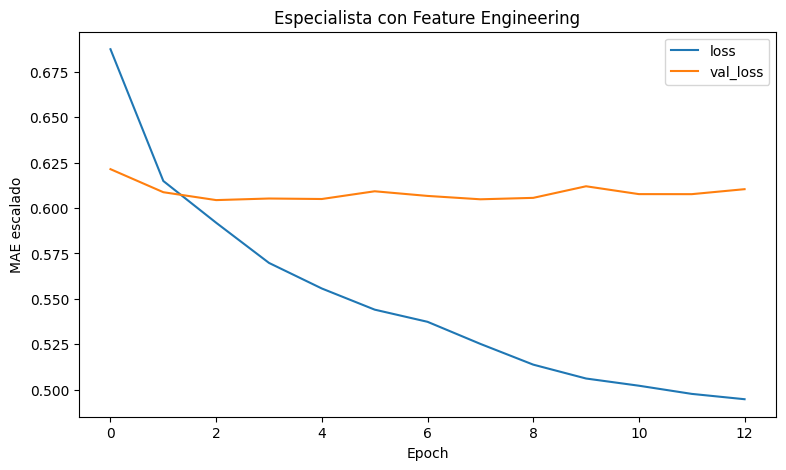

In [153]:
# =============================================================================
# CURVA DE ENTRENAMIENTO
# =============================================================================

if os.path.exists(HISTORY_FE_PATH):

    history_fe_df = pd.read_csv(HISTORY_FE_PATH)

    ax = history_fe_df[["loss","val_loss"]].plot(
        figsize=(9,5),
        xlabel="Epoch",
        ylabel="MAE escalado",
        title="Especialista con Feature Engineering"
    )

    ax.grid(False)

else:
    print("Historial no disponible.")

In [154]:
# =============================================================================
# FUNCIONES DE EVALUACIÓN
# =============================================================================

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

def wmae(y_true,y_pred,is_holiday):
    weights = np.where(is_holiday,5.0,1.0)
    return np.sum(weights*np.abs(y_true-y_pred))/np.sum(weights)

def regression_metrics(df,y_pred):

    y_true = df["Weekly_Sales"].values

    return {
        "MAE":mean_absolute_error(y_true,y_pred),
        "RMSE":np.sqrt(mean_squared_error(y_true,y_pred)),
        "WMAE":wmae(y_true,y_pred,df["IsHoliday"].values),
        "R2":r2_score(y_true,y_pred)
    }

def predict_specialist_fe(df):

    X = preprocessor_high_fe.transform(
        df[model_features_fe]
    ).astype("float32")

    residual_scaled = model_high_fe.predict(
        X,verbose=0
    )

    residual = target_scaler_high_fe.inverse_transform(
        residual_scaled
    ).ravel()

    return df["Lag_52"].values + residual

def predict_specialist_original(df):
    """Predicción reconstruida usando el especialista original y SUS transformadores."""
    X = preprocessor_high.transform(df[model_features])
    if sparse.issparse(X):
        X = X.toarray()
    X = np.asarray(X, dtype=np.float32)
    residual_scaled = mlp_high.predict(X, verbose=0)
    residual = target_scaler_high.inverse_transform(residual_scaled).ravel()
    return df["Lag_52"].to_numpy() + residual

In [155]:
# =============================================================================
# COMPARACIÓN DE AMBOS ESPECIALISTAS SOBRE LAS MISMAS FILAS
# =============================================================================
pred_high_original_same_rows = predict_specialist_original(validation_high_fe)
pred_high_fe = predict_specialist_fe(validation_high_fe)

metrics_high_original_same_rows = regression_metrics(
    validation_high_fe, pred_high_original_same_rows
)
metrics_high_fe = regression_metrics(validation_high_fe, pred_high_fe)

comparison_high_fe = pd.DataFrame([
    {"Model": "Especialista original (mismas filas)", **metrics_high_original_same_rows},
    {"Model": "Especialista + Feature Engineering", **metrics_high_fe},
])
display(comparison_high_fe.style.format({
    "MAE": "{:,.2f}", "RMSE": "{:,.2f}",
    "WMAE": "{:,.2f}", "R2": "{:.4f}"
}))

,Model,MAE,RMSE,WMAE,R2
0,Especialista original (mismas filas),"3,353.13","5,521.12","3,328.51",0.9533
1,Especialista + Feature Engineering,"3,166.28","5,388.91","3,122.22",0.9555


In [156]:
# =============================================================================
# EVALUACIÓN SOBRE LA MISMA POBLACIÓN DEL EXPERIMENTO ANTERIOR
# =============================================================================

validation_common_fe = validation_residual_fe[
    ~validation_residual_fe["Lag_52_imputed"]
].copy()

print("Filas comunes:",len(validation_common_fe))

Filas comunes: 112437


In [157]:
# =============================================================================
# HARD GATE + NUEVO ESPECIALISTA: POBLACIÓN COMÚN
# Comparación calculada, sin métricas antiguas escritas a mano.
# =============================================================================
validation_common_fe = validation_common_fe.copy()

pred_system_common = validation_common_fe["Lag_52"].to_numpy().copy()
pred_system_original_common = validation_common_fe["Lag_52"].to_numpy().copy()

high_mask_common = validation_common_fe["Lag_52"] > HIGH_THRESHOLD
high_common = validation_common_fe.loc[high_mask_common]

pred_system_common[high_mask_common.to_numpy()] = predict_specialist_fe(high_common)
pred_system_original_common[high_mask_common.to_numpy()] = predict_specialist_original(high_common)

metrics_system_common = regression_metrics(validation_common_fe, pred_system_common)
metrics_system_original_common = regression_metrics(
    validation_common_fe, pred_system_original_common
)
comparison_system_common = pd.DataFrame([
    {"Model": "Hard gate + especialista anterior", **metrics_system_original_common},
    {"Model": "Hard gate + Feature Engineering", **metrics_system_common},
])
display(comparison_system_common.style.format({
    "MAE": "{:,.2f}", "RMSE": "{:,.2f}",
    "WMAE": "{:,.2f}", "R2": "{:.4f}"
}))

,Model,MAE,RMSE,WMAE,R2
0,Hard gate + especialista anterior,"1,849.03","3,779.95","1,841.28",0.9713
1,Hard gate + Feature Engineering,"1,767.58","3,695.85","1,751.11",0.9726


In [158]:
# =============================================================================
# HARD GATE + NUEVO ESPECIALISTA: COBERTURA AMPLIADA
# =============================================================================

pred_system_extended = validation_residual_fe["Lag_52"].values.copy()

high_mask_extended = (
    validation_residual_fe["Lag_52"] > HIGH_THRESHOLD
)

pred_system_extended[high_mask_extended] = predict_specialist_fe(
    validation_residual_fe.loc[high_mask_extended]
)

metrics_system_extended = regression_metrics(
    validation_residual_fe,
    pred_system_extended
)

extended_result = pd.DataFrame([{
    "Model":"Hard gate + Feature Engineering",
    "N":len(validation_residual_fe),
    "Coverage":len(validation_residual_fe)/len(validation_lags_filled),
    **metrics_system_extended
}])

display(
    extended_result.style.format({
        "N":"{:,.0f}",
        "Coverage":"{:.2%}",
        "MAE":"{:,.2f}",
        "RMSE":"{:,.2f}",
        "WMAE":"{:,.2f}",
        "R2":"{:.4f}"
    })
)

,Model,N,Coverage,MAE,RMSE,WMAE,R2
0,Hard gate + Feature Engineering,"113,330",98.05%,"1,755.67","3,682.02","1,741.34",0.9727


### 9.3. Comparación de especialistas sobre una muestra común

Para aislar el efecto de las nuevas variables, se mantiene la regla de selección por volumen y se comparan el especialista anterior y el especialista con *Feature Engineering* sobre las mismas 112.437 observaciones de validación. El nuevo conjunto de características se evalúa de forma conjunta, por lo que no es posible atribuir la mejora a una variable individual.

| Sistema | MAE | RMSE | WMAE | R² |
|---|---:|---:|---:|---:|
| Hard gating + especialista anterior | — | — | 1.841,28 | — |
| Hard gating + especialista con FE | — | — | **1.751,11** | — |

El WMAE se reduce aproximadamente un **4,90 %**. Los guiones indican métricas que deben consultarse en la tabla calculada inmediatamente antes; no se sustituyen por valores procedentes de ejecuciones anteriores. Esta comparación permite atribuir la diferencia observada al sistema de características y al reentrenamiento correspondiente, sin cambiar la población evaluada.

### Cobertura ampliada mediante reconstrucción del histórico

La reconstrucción de retardos permite incorporar observaciones adicionales y alcanzar **113.330 registros de validación**, equivalentes al **98,05 %** de la muestra original. Sobre esta población ampliada, el sistema de hard gating con especialista FE obtiene:

| Modelo | N | Cobertura | MAE | RMSE | WMAE | R² |
|---|---:|---:|---:|---:|---:|---:|
| Hard gating + FE | 113.330 | 98,05 % | 1.755,67 | 3.682,02 | 1.741,34 | 0,9727 |

Este resultado se diferencia de la comparación anterior: aquí cambia la cobertura, mientras que en la muestra común se comparaba el efecto de las nuevas variables sobre las mismas observaciones. La ampliación recupera parte del histórico, aunque no resuelve los casos sin un retardo anual utilizable.


### 9.4. Soft Mixture of Experts con Feature Engineering

Tras estudiar el especialista con nuevas variables, se comprueba si una puerta aprendida permite aprovechar mejor la combinación entre la referencia anual y el experto neuronal. El Soft MoE con FE se entrena sobre todas las observaciones residuales disponibles y se evalúa sobre la misma muestra que el hard gating con FE. Sus pesos y transformadores se conservan en una carpeta independiente.

In [159]:
# =============================================================================
# SOFT MOE + FEATURE ENGINEERING: DATOS Y TRANSFORMADORES
# =============================================================================
from sklearn.base import clone
from pathlib import Path
import joblib

MOE_FE_DIR = Path("/content/drive/MyDrive/TFM/models/soft_moe_feature_engineering_v1")
MOE_FE_DIR.mkdir(parents=True, exist_ok=True)
MOE_FE_WEIGHTS = MOE_FE_DIR / "soft_moe_fe.weights.h5"
MOE_FE_PREPROCESSOR = MOE_FE_DIR / "preprocessor.joblib"
MOE_FE_TARGET_SCALER = MOE_FE_DIR / "target_scaler.joblib"
MOE_FE_HISTORY = MOE_FE_DIR / "training_history.csv"
MOE_FE_CURVE = MOE_FE_DIR / "training_curve.png"

# Control independiente: TRAIN=True fuerza también el reentrenamiento de este
# experimento. Con TRAIN=False se cargan pesos y transformadores existentes.
RETRAIN_MOE_FE = bool(TRAIN)
MOE_FE_READY = all(p.exists() for p in (
    MOE_FE_WEIGHTS, MOE_FE_PREPROCESSOR, MOE_FE_TARGET_SCALER
))
ENTRENAR_MOE_FE = RETRAIN_MOE_FE or not MOE_FE_READY
print("Soft MoE + FE:", "ENTRENAR" if ENTRENAR_MOE_FE else "CARGAR")

train_moe_fe = train_residual_fe.copy()
val_moe_fe = validation_residual_fe.copy()
if ENTRENAR_MOE_FE:
    preprocessor_moe_fe = clone(preprocessor_high_fe)
    preprocessor_moe_fe.fit(train_moe_fe[model_features_fe])
    target_scaler_moe_fe = StandardScaler()
    target_scaler_moe_fe.fit(train_moe_fe[["Residual_52"]])
else:
    preprocessor_moe_fe = joblib.load(MOE_FE_PREPROCESSOR)
    target_scaler_moe_fe = joblib.load(MOE_FE_TARGET_SCALER)

X_train_moe_fe = preprocessor_moe_fe.transform(train_moe_fe[model_features_fe]).astype("float32")
X_val_moe_fe = preprocessor_moe_fe.transform(val_moe_fe[model_features_fe]).astype("float32")
y_train_moe_fe = target_scaler_moe_fe.transform(train_moe_fe[["Residual_52"]]).astype("float32")
y_val_moe_fe = target_scaler_moe_fe.transform(val_moe_fe[["Residual_52"]]).astype("float32")

# Usar DataFrame con nombre de columna evita el aviso de sklearn.
baseline_residual_moe_fe = float(target_scaler_moe_fe.transform(
    pd.DataFrame({"Residual_52": [0.0]})
)[0, 0])
weights_train_moe_fe = np.where(train_moe_fe["IsHoliday"], 5.0, 1.0).astype("float32")
weights_val_moe_fe = np.where(val_moe_fe["IsHoliday"], 5.0, 1.0).astype("float32")
print("Train:", X_train_moe_fe.shape, "Validation:", X_val_moe_fe.shape)


Soft MoE + FE: CARGAR
Train: (150116, 166) Validation: (113330, 166)


In [160]:

# =============================================================================
# SOFT MOE + FEATURE ENGINEERING: ARQUITECTURA
# =============================================================================

import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

inputs_moe_fe = tf.keras.Input(
    shape=(X_train_moe_fe.shape[1],),
    name="features"
)

# Experto MLP residual
expert_fe = tf.keras.layers.Dense(
    128, activation="relu", name="expert_dense_1"
)(inputs_moe_fe)

expert_fe = tf.keras.layers.Dropout(
    0.20, name="expert_dropout_1"
)(expert_fe)

expert_fe = tf.keras.layers.Dense(
    64, activation="relu", name="expert_dense_2"
)(expert_fe)

expert_fe = tf.keras.layers.Dropout(
    0.10, name="expert_dropout_2"
)(expert_fe)

expert_output_fe = tf.keras.layers.Dense(
    1, name="expert_output"
)(expert_fe)

# Red de gating
gate_fe = tf.keras.layers.Dense(
    32, activation="relu", name="gate_dense_1"
)(inputs_moe_fe)

gate_fe = tf.keras.layers.Dense(
    16, activation="relu", name="gate_dense_2"
)(gate_fe)

gate_output_fe = tf.keras.layers.Dense(
    1, activation="sigmoid", name="gate"
)(gate_fe)

# Experto baseline: residual cero en escala estandarizada
baseline_output_fe = tf.keras.layers.Lambda(
    lambda x: tf.ones_like(x) * baseline_residual_moe_fe,
    name="baseline_expert"
)(expert_output_fe)

# Combinación ponderada
baseline_weighted_fe = tf.keras.layers.Multiply()([
    tf.keras.layers.Lambda(
        lambda x: 1.0 - x,
        name="baseline_weight"
    )(gate_output_fe),
    baseline_output_fe
])

expert_weighted_fe = tf.keras.layers.Multiply()([
    gate_output_fe,
    expert_output_fe
])

moe_output_fe = tf.keras.layers.Add(
    name="mixture_output"
)([baseline_weighted_fe, expert_weighted_fe])

moe_model_fe = tf.keras.Model(
    inputs=inputs_moe_fe,
    outputs=moe_output_fe,
    name="Residual_Soft_MoE_FE"
)

moe_model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mae"
)

moe_model_fe.summary()


Model: "Residual_Soft_MoE_FE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ features            │ (None, 166)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dense_1      │ (None, 128)       │     21,376 │ features[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dropout_1    │ (None, 128)       │          0 │ expert_dense_1[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_dense_1        │ (None, 32)        │      5,344 │ features[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dense_2      │ (None, 64)        │      8,256 │ expert_dropout_1… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_dense_2        │ (None, 16)        │        528 │ gate_dense_1[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_dropout_2    │ (None, 64)        │          0 │ expert_dense_2[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate (Dense)        │ (None, 1)         │         17 │ gate_dense_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_output       │ (None, 1)         │         65 │ expert_dropout_2… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ baseline_weight     │ (None, 1)         │          0 │ gate[0][0]        │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ baseline_expert     │ (None, 1)         │          0 │ expert_output[0]… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 1)         │          0 │ baseline_weight[… │
│ (Multiply)          │                   │            │ baseline_expert[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_3          │ (None, 1)         │          0 │ gate[0][0],       │
│ (Multiply)          │                   │            │ expert_output[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mixture_output      │ (None, 1)         │          0 │ multiply_2[0][0], │
│ (Add)               │                   │            │ multiply_3[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 35,586 (139.01 KB)

 Trainable params: 35,586 (139.01 KB)

 Non-trainable params: 0 (0.00 B)

In [161]:
# =============================================================================
# SOFT MOE + FE: CARGA O ENTRENAMIENTO (ARTEFACTOS INDEPENDIENTES)
# =============================================================================
if not ENTRENAR_MOE_FE:
    comprobar_entrada_modelo(moe_model_fe, X_val_moe_fe.shape[1], "Soft MoE + FE")
    moe_model_fe.load_weights(str(MOE_FE_WEIGHTS))
    print("Soft MoE + FE: pesos y transformadores recuperados de Drive.")
else:
    callbacks_moe_fe = [tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True
    )]
    history_moe_fe = moe_model_fe.fit(
        X_train_moe_fe, y_train_moe_fe,
        sample_weight=weights_train_moe_fe,
        validation_data=(X_val_moe_fe, y_val_moe_fe, weights_val_moe_fe),
        epochs=150, batch_size=256, callbacks=callbacks_moe_fe, verbose=1
    )
    moe_model_fe.save_weights(str(MOE_FE_WEIGHTS))
    joblib.dump(preprocessor_moe_fe, MOE_FE_PREPROCESSOR)
    joblib.dump(target_scaler_moe_fe, MOE_FE_TARGET_SCALER)
    pd.DataFrame(history_moe_fe.history).to_csv(MOE_FE_HISTORY, index=False)
    print("Soft MoE + FE: pesos, transformadores e historial guardados.")
print("Directorio:", MOE_FE_DIR)


Soft MoE + FE: pesos y transformadores recuperados de Drive.
Directorio: /content/drive/MyDrive/TFM/models/soft_moe_feature_engineering_v1


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


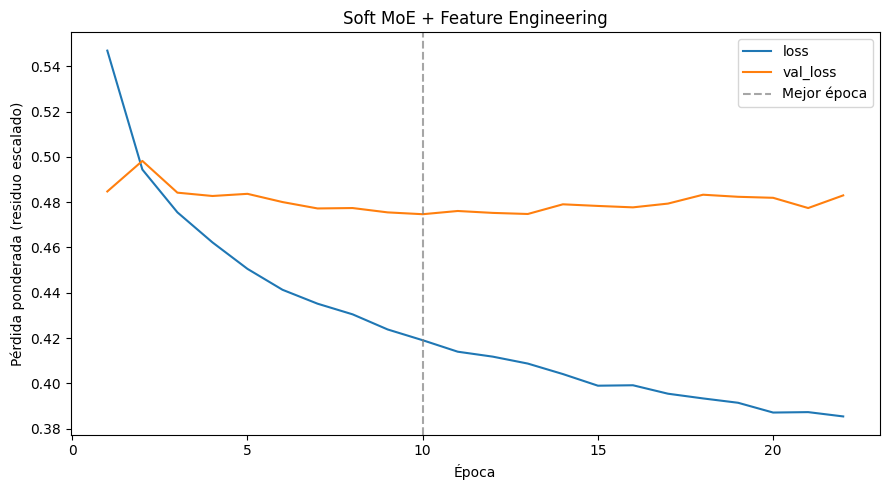

Mejor época: 10


In [162]:
# =============================================================================
# SOFT MOE + FE: CURVA DE ENTRENAMIENTO (TAMBIÉN EN MODO CARGA)
# =============================================================================
import matplotlib.pyplot as plt
if MOE_FE_HISTORY.exists():
    history_df_moe_fe = pd.read_csv(MOE_FE_HISTORY)
    history_df_moe_fe.index += 1
    history_df_moe_fe.index.name = "Epoch"
    ax = history_df_moe_fe[["loss", "val_loss"]].plot(figsize=(9, 5))
    ax.axvline(history_df_moe_fe["val_loss"].idxmin(), linestyle="--",
               color="gray", alpha=.7, label="Mejor época")
    ax.set(xlabel="Época", ylabel="Pérdida ponderada (residuo escalado)",
           title="Soft MoE + Feature Engineering")
    ax.legend()
    plt.tight_layout()
    plt.savefig(MOE_FE_CURVE, dpi=150, bbox_inches="tight")
    plt.show()
    print("Mejor época:", history_df_moe_fe["val_loss"].idxmin())
else:
    print("Historial no disponible: pesos cargados de un entrenamiento anterior sin CSV.")


In [163]:

# =============================================================================
# SOFT MOE + FEATURE ENGINEERING: EVALUACIÓN
# =============================================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predicción del residual en escala original
pred_residual_moe_fe_scaled = moe_model_fe.predict(
    X_val_moe_fe,
    verbose=0
)

pred_residual_moe_fe = target_scaler_moe_fe.inverse_transform(
    pred_residual_moe_fe_scaled
).ravel()

# Reconstrucción de ventas semanales
y_true_moe_fe = val_moe_fe["Weekly_Sales"].to_numpy()
y_pred_moe_fe = (
    val_moe_fe["Lag_52"].to_numpy() + pred_residual_moe_fe
)

# Métricas
mae_moe_fe = mean_absolute_error(y_true_moe_fe, y_pred_moe_fe)
rmse_moe_fe = np.sqrt(mean_squared_error(y_true_moe_fe, y_pred_moe_fe))
wmae_moe_fe = np.average(
    np.abs(y_true_moe_fe - y_pred_moe_fe),
    weights=weights_val_moe_fe
)
r2_moe_fe = r2_score(y_true_moe_fe, y_pred_moe_fe)

metrics_moe_fe = {
    "MAE": mae_moe_fe,
    "RMSE": rmse_moe_fe,
    "WMAE": wmae_moe_fe,
    "R2": r2_moe_fe
}

display(
    pd.DataFrame(
        [metrics_moe_fe],
        index=["Soft MoE + Feature Engineering"]
    ).round(4)
)

print("Observaciones evaluadas:", len(val_moe_fe))


,MAE,RMSE,WMAE,R2
Soft MoE + Feature Engineering,1705.4273,3583.6674,1691.6818,0.9741


Observaciones evaluadas: 113330


In [164]:

# =============================================================================
# COMPARACIÓN FINAL: HARD GATING + FE VS SOFT MOE + FE
# =============================================================================

# Predicciones del Soft MoE con FE, indexadas por observación.
pred_soft_fe = pd.Series(
    y_pred_moe_fe,
    index=val_moe_fe.index,
    name="Soft MoE + FE"
)

# Reconstrucción de las predicciones del hard gating con FE.
# El especialista solo interviene cuando Lag_52 supera el umbral.
X_val_high_fe = preprocessor_high_fe.transform(
    val_moe_fe.loc[
        val_moe_fe["Lag_52"] > best_threshold,
        model_features_fe
    ]
).astype("float32")

pred_high_fe_scaled = model_high_fe.predict(
    X_val_high_fe,
    verbose=0
)

pred_high_fe_residual = target_scaler_high_fe.inverse_transform(
    pred_high_fe_scaled
).ravel()

pred_hard_fe = pd.Series(
    val_moe_fe["Lag_52"].to_numpy().copy(),
    index=val_moe_fe.index,
    name="Hard gating + FE"
)

mask_high_fe = val_moe_fe["Lag_52"] > best_threshold

pred_hard_fe.loc[mask_high_fe] += pred_high_fe_residual

# Comparación sobre las mismas observaciones.
comparison_fe = pd.DataFrame({
    "Real": val_moe_fe["Weekly_Sales"],
    "Peso": weights_val_moe_fe,
    "Hard gating + FE": pred_hard_fe,
    "Soft MoE + FE": pred_soft_fe
}).dropna()

results_comparison_fe = []

for model_name in ["Hard gating + FE", "Soft MoE + FE"]:
    y_true = comparison_fe["Real"].to_numpy()
    y_pred = comparison_fe[model_name].to_numpy()
    weights = comparison_fe["Peso"].to_numpy()

    results_comparison_fe.append({
        "Modelo": model_name,
        "N": len(comparison_fe),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "WMAE": np.average(np.abs(y_true - y_pred), weights=weights),
        "R2": r2_score(y_true, y_pred)
    })

display(
    pd.DataFrame(results_comparison_fe)
    .set_index("Modelo")
    .round(4)
)

print("Observaciones comunes:", len(comparison_fe))


,N,MAE,RMSE,WMAE,R2
Modelo,,,,,
Hard gating + FE,113330,1755.6747,3682.0222,1741.3359,0.9727
Soft MoE + FE,113330,1705.4273,3583.6674,1691.6818,0.9741


Observaciones comunes: 113330



### Comparación final entre hard gating y soft gating con Feature Engineering

Una vez incorporadas las nuevas variables, se ha evaluado si la mejora obtenida mediante Feature Engineering también se mantiene al utilizar una arquitectura de soft gating. Para ello, se ha entrenado un nuevo modelo Soft Mixture of Experts (Soft MoE) con las mismas variables ampliadas, conservando el planteamiento de combinar un experto basado en la predicción residual con otro que mantiene el valor de referencia proporcionado por `Lag_52`.

La comparación se ha realizado sobre las mismas 113.330 observaciones de validación, evitando que las diferencias en la cobertura de los modelos condicionen la interpretación de los resultados.

| Modelo | N | MAE | RMSE | WMAE | R² |
|---|---:|---:|---:|---:|---:|
| Hard gating + FE | 113.330 | 1.755,67 | 3.682,02 | 1.741,34 | 0,9727 |
| Soft MoE + FE | 113.330 | 1.705,43 | 3.583,67 | **1.691,68** | **0,9741** |

Los resultados muestran que el Soft MoE con Feature Engineering supera al sistema de hard gating con las mismas variables en todas las métricas consideradas. En particular, el WMAE disminuye de 1.741,34 a 1.691,68, lo que representa una mejora relativa del 2,85 %. También se observan reducciones en el MAE y el RMSE, acompañadas de un ligero incremento del coeficiente R².

Esta diferencia resulta especialmente relevante porque ambos modelos se han evaluado sobre exactamente las mismas observaciones y utilizan la misma información de entrada. Por tanto, la mejora observada no puede atribuirse a una mayor cobertura de validación, sino a las diferencias entre las estrategias de combinación de los expertos.

En consecuencia, el Soft MoE con Feature Engineering pasa a ser la **arquitectura seleccionada en validación** para el entrenamiento final posterior, al presentar el menor WMAE entre las alternativas comparadas en esta fase. Esta selección se fundamenta exclusivamente en los resultados de validación, dado que el conjunto de test no dispone de la variable objetivo y no permite evaluar directamente el rendimiento predictivo.


## 10. Cierre experimental y selección de arquitectura

La experimentación comienza con el baseline anual `Lag_52` y una MLP que aprende el residuo respecto a esa referencia. La segmentación por volumen muestra que la MLP no aporta la misma mejora en todos los regímenes, lo que motiva la comparación entre un *hard gating* basado en un umbral y una combinación flexible mediante *soft gating*.

La selección del umbral del hard gating se realiza sobre validación: el cuantil elegido es **Q55**, correspondiente a `Lag_52 = 9.861,66`. Esta regla se mantiene en los experimentos posteriores con especialistas para garantizar la trazabilidad de las comparaciones. La reconstrucción de los retardos y las variables derivadas amplían la información disponible y permiten alcanzar el **98,05 %** de cobertura de validación.

Finalmente, se entrena un Soft MoE con las variables de *Feature Engineering* y se compara con el hard gating con FE sobre **las mismas 113.330 observaciones**. El WMAE disminuye de **1.741,34 a 1.691,68**, una mejora relativa del **2,85 %**, y también mejoran el MAE, el RMSE y el R². En consecuencia, **se selecciona el Soft MoE con Feature Engineering** como arquitectura candidata para el modelo final.

Esta elección corresponde al proceso de selección sobre validación, que se ha utilizado repetidamente para comparar alternativas. Por tanto, el WMAE de **1.691,68** no debe interpretarse como rendimiento independiente sobre test. El conjunto de test no contiene `Weekly_Sales` y no permite calcular errores predictivos.

El siguiente notebook deberá reconstruir la arquitectura seleccionada, ajustar sus transformadores y entrenar una nueva red con **train y validation combinados**, utilizando una política de épocas establecida a partir del desarrollo anterior y sin usar test para selección o parada temprana. Después podrá generar predicciones para las filas con `Lag_52` disponible. Los casos sin referencia anual requieren una decisión explícita adicional y no se consideran resueltos en este notebook.


## 11. Exportación para el notebook final

Se exportan los datos residuales con las variables de *Feature Engineering* a `/content/drive/MyDrive/TFM/data/final_model`: `train_final.parquet` (**150.116** filas), `validation_final.parquet` (**113.330** filas) y `test_final.parquet` (**113.915** filas, sin variable objetivo). También se guarda `feature_config.json` con las variables de entrada, la arquitectura seleccionada, las rutas de los artefactos de validación y la información de cobertura.

Los pesos de validación del **Soft MoE + FE** se conservan en `/content/drive/MyDrive/TFM/models/soft_moe_feature_engineering_v1`, junto con su preprocesador, escalador e historial. **No son todavía los pesos definitivos para test**: el notebook final deberá volver a ajustar y entrenar el modelo sobre todos los datos históricos etiquetados. La selección de arquitectura se basa exclusivamente en validación; el test no permite calcular métricas de error.

La cobertura sigue siendo parcial: las observaciones sin `Lag_52` no están incluidas en los archivos residuales exportados. No se introduce aquí una predicción alternativa para esos casos.


In [165]:
print("Weekly_Sales" in test_residual_fe.columns)
print("Residual_52" in test_residual_fe.columns)

False
False


In [166]:
# =============================================================================
# DATASETS FINALES PARA EL NOTEBOOK DE TEST
# =============================================================================

import os
import json

FINAL_DATA_DIR = "/content/drive/MyDrive/TFM/data/final_model"
os.makedirs(FINAL_DATA_DIR,exist_ok=True)

# Columnas identificativas
id_cols = ["Store","Dept","Date"]

# Features exactas utilizadas por el modelo ganador
final_model_features = model_features_fe.copy()

# Evitar duplicados
train_cols = list(dict.fromkeys(
    id_cols + ["Weekly_Sales","Residual_52"] + final_model_features
))

validation_cols = list(dict.fromkeys(
    id_cols + ["Weekly_Sales","Residual_52"] + final_model_features
))

test_cols = list(dict.fromkeys(
    id_cols + final_model_features
))

train_final = train_residual_fe[train_cols].copy()
validation_final = validation_residual_fe[validation_cols].copy()
test_final = test_residual_fe[test_cols].copy()

print("Train:",train_final.shape)
print("Validation:",validation_final.shape)
print("Test:",test_final.shape)

Train: (150116, 41)
Validation: (113330, 41)
Test: (113915, 39)


In [167]:
# =============================================================================
# COMPROBACIÓN DE FEATURES
# =============================================================================

for name,df in [
    ("Train",train_final),
    ("Validation",validation_final),
    ("Test",test_final)
]:

    missing_features = [
        col for col in final_model_features
        if col not in df.columns
    ]

    print(f"{name}:")
    print("  Features ausentes:",missing_features)
    print("  Duplicados:",df.duplicated(["Store","Dept","Date"]).sum())

Train:
  Features ausentes: []
  Duplicados: 0
Validation:
  Features ausentes: []
  Duplicados: 0
Test:
  Features ausentes: []
  Duplicados: 0


In [168]:
# =============================================================================
# GUARDADO DE LOS DATASETS FINALES
# =============================================================================

TRAIN_FINAL_PATH = f"{FINAL_DATA_DIR}/train_final.parquet"
VALIDATION_FINAL_PATH = f"{FINAL_DATA_DIR}/validation_final.parquet"
TEST_FINAL_PATH = f"{FINAL_DATA_DIR}/test_final.parquet"

train_final.to_parquet(TRAIN_FINAL_PATH,index=False)
validation_final.to_parquet(VALIDATION_FINAL_PATH,index=False)
test_final.to_parquet(TEST_FINAL_PATH,index=False)

print("Datasets guardados:")
print(TRAIN_FINAL_PATH)
print(VALIDATION_FINAL_PATH)
print(TEST_FINAL_PATH)

Datasets guardados:
/content/drive/MyDrive/TFM/data/final_model/train_final.parquet
/content/drive/MyDrive/TFM/data/final_model/validation_final.parquet
/content/drive/MyDrive/TFM/data/final_model/test_final.parquet


In [169]:
# =============================================================================
# CONFIGURACIÓN DEL MODELO SELECCIONADO PARA EL NOTEBOOK FINAL
# =============================================================================
feature_config = {
    "selected_model": "soft_moe_feature_engineering",
    "architecture": {
        "expert_dense": [128, 64], "expert_dropout": [0.20, 0.10],
        "gate_dense": [32, 16], "gate_activation": "sigmoid",
        "expert_output": "scaled_residual", "baseline_expert": "scaled_zero_residual",
        "loss": "mae", "holiday_weight": 5.0,
        "learning_rate": 0.001, "batch_size": 256,
        "max_epochs_selection": 150, "early_stopping_patience": 12
    },
    "categorical_features": categorical_features_fe,
    "numeric_features": numeric_features_fe,
    "binary_features": binary_features_fe,
    "model_features": final_model_features,
    "target": "Weekly_Sales",
    "residual_target": "Residual_52",
    "baseline_feature": "Lag_52",
    "historical_hard_gate_threshold": float(best_threshold),
    "validation_coverage": len(validation_final) / len(validation_lags_filled),
    "test_coverage": len(test_final) / len(test),
    "validation_rows": len(validation_final),
    "test_rows": len(test_final),
    "validation_model_artifacts": {
        "weights": str(MOE_FE_WEIGHTS),
        "preprocessor": str(MOE_FE_PREPROCESSOR),
        "target_scaler": str(MOE_FE_TARGET_SCALER),
        "history": str(MOE_FE_HISTORY)
    },
    "final_training_required": True,
    "final_training_note": "Reajustar transformadores y reentrenar con train+validation; test no tiene etiquetas."
}
CONFIG_PATH = f"{FINAL_DATA_DIR}/feature_config.json"
with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(feature_config, f, indent=4, ensure_ascii=False)
print("Configuración guardada:", CONFIG_PATH)


Configuración guardada: /content/drive/MyDrive/TFM/data/final_model/feature_config.json


In [170]:
# =============================================================================
# COMPROBACIÓN FINAL DE GUARDADO
# =============================================================================

for path in [
    TRAIN_FINAL_PATH,
    VALIDATION_FINAL_PATH,
    TEST_FINAL_PATH,
    CONFIG_PATH
]:
    print(
        os.path.basename(path),
        "→",
        os.path.exists(path)
    )

train_final.parquet → True
validation_final.parquet → True
test_final.parquet → True
feature_config.json → True


## Notas de ejecución y limitaciones

Con `TRAIN=False` se reutilizan los modelos guardados cuando sus artefactos están disponibles y son compatibles; si faltan, algunos bloques pueden entrenarse automáticamente. `TRAIN=True` fuerza el reentrenamiento. `RUN_SOFT_MOE=True` habilita el **Soft MoE original**, mientras que el **Soft MoE + FE** se gestiona independientemente y se carga de Drive cuando sus tres artefactos existen. Para revisar la ejecución actual se recomienda `TRAIN=False` y `RUN_SOFT_MOE=True`.

Las métricas proceden del conjunto de validación, utilizado también para seleccionar umbrales, modelos y características. No constituyen una evaluación independiente. El conjunto de test carece de `Weekly_Sales`; la formulación residual exige `Lag_52`, disponible en el **98,05 %** de validación y aproximadamente el **99,00 %** del test tras la reconstrucción. La solución para los registros restantes queda fuera de esta exportación.
